# QuantStack: Breakout Strategy Case Studies — 7 Videos, One Framework, One Real Question

### *No hype. Just code.*

This is not a video about whether breakout trading works. Breakout logic is real and
professionally used — most trend-following CTAs run some form of it at institutional size.
This is a video about why seven separate YouTube videos, each teaching its own "breakout
strategy," none holds up as a demonstrated edge once you stop trusting their screenshots and actually run the numbers with real costs.

The structure:

1. **What a breakout strategy actually is** — underneath the different names and packaging,
a handful of recurring ideas: a pivot break, a pivot break with extra confirmation, a channel
break, a range break, a session-opening-range break, a fair-value-gap break.
2. **7 case studies** — each strategy built exactly as its source video showed it (same
detection logic, same stops, same entries wherever the source showed them; Strategy 3's SL/TP and Strategy 6's stop are the flagged exceptions), run through the same real-cost, seven-major-pair
Global-Lock portfolio engine — each on the timeframe its own video used, over the shared 20-year window (the one
exception is Strategy 5, a short 730-day M1 window matching its source; see 9a's `days` and `thin_sample` columns). Most of them lose money, often badly; the
few that don't are small results that rest on a thin sample (Strategy 2) or on a borrowed, unverified RSI exit hook (Strategy 3;
see 9a-iii) — not evidence of an edge.
3. **Diagnosis** — not "breakout doesn't work," but a data-backed autopsy of what these 7
implementations have in common: the specific shortcuts, missing filters, and untested
assumptions that killed each one.
4. **The control test** — an 8th strategy, built with none of the flaws diagnosed in step 3
(volatility-adaptive stops, a genuine trend/regime filter, textbook rather than curve-fit
parameters, tested across a basket of seven USD majors instead of one pair — which is broader, but not truly diversified, since all seven share the dollar). The goal here isn't to
hand you a profitable strategy — it's to isolate one variable: with those specific flaws
removed, what does a breakout strategy actually do?
5. **The real answer** — Strategy 8 might still lose money. That wouldn't be a failed
experiment — it would mean breakout's problems run deeper than these six specific flaws. The answer is in Section 15, and every number in it comes from the `RECEIPTS` cell.

**What this test cannot show:** it uses one cost model (Section 7), one roughly 20-year window, seven USD-quoted majors that move together, and one specific implementation of each idea. It shows these implementations have no demonstrated edge under those assumptions — not that breakout can never work. Context claims that no cell backs (for example that trend-following funds run breakout logic at scale) need an outside source on screen, or should be cut.


**Section 6** is where all 8 strategies live — the 7 case studies plus an 8th, deliberately
correct control strategy — in a shared registry (`STRATEGY_VARIANTS`) that any number of
strategies can register into, each with its own parameters, direction logic, and stop-loss/
take-profit mechanism where the source video showed one. Section 9c, right after the
backtesting engine, diagnoses what the 7 case studies share; the 8th strategy in Section 6
exists specifically to test whether removing those shared flaws changes the answer.
Everything before Section 6 and everything after Section 9 (results, visualizations,
robustness checks, cost sensitivity, multi-pair testing) is shared, strategy-agnostic
infrastructure — it doesn't care which of the 8 generated the signals it's evaluating, so
every one is held to exactly the same standard.

**Where the video's numbers come from:** every figure spoken or shown in the video must come from the
`RECEIPTS` printout in Section 15 (or the 9a/9a-ii tables), from a single frozen run. Prose in this
notebook deliberately avoids hard-coding results, because they change whenever a modelling fix is made.


## How to use this notebook

Two switches control fidelity:
- **`EXECUTION_MODE`** — `"production"` (realistic spread/slippage/commission) or `"naive"` (zero cost, matches how these strategies' own source videos priced their backtests).
- **`SIZING_MODE`** — `"production"` (volatility- and session-scaled position sizing) or `"fixed"` (plain fixed-fractional risk).

One more:
- **`ACTIVE_VARIANT`** (set in Section 9d) — which of the 8 registered strategies (the 7 case
studies plus the Section 6 control strategy) to run individually for a deep-dive; Section 10
onward (Results & Metrics, Visualizations, Robustness, Cost Sensitivity) all analyze that one
run. To compare all 8 at once instead, see Section 9a's `run_all_strategies()`.


---
## 0. Configuration

This is the only cell you *must* touch before running the notebook. Everything downstream reads from `CONFIG`.


In [1]:
import os, time, json, warnings, random
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import holidays
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from tqdm.auto import tqdm  
import plotly.io as pio
import scipy.stats as _scipy_stats  

pio.renderers.default = "notebook"

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

from dotenv import load_dotenv
load_dotenv()

MAJOR_PAIRS = ["EURUSD", "GBPUSD", "USDJPY", "USDCHF", "AUDUSD", "USDCAD", "NZDUSD"]  # the 7 standard USD majors

# --- 🎛️ STRATEGY PROFILES  ----------------------------------------------------
STRATEGY_PROFILES = {
    # Shared profile for all 7 strategies (Section 6). Holds only what every strategy
    # has in common (risk, session/holiday defaults, exits) -- each strategy's OWN
    # parameters (pivot windows, SL/TP logic, etc.) live in that strategy's own
    # STRATEGY_<N>_PARAMS dict, defined at the top of its definition cell in Section 6,
    # and merged with this profile at call time.
    "multi_breakout_strategy": {
        "bar_size": "1 hour",
        "symbols": MAJOR_PAIRS,   
        "risk_percent": 0.01,
        "session_start_hour": 0, "session_end_hour": 24,
        "hard_close_hour": 23, "hard_close_minute": 59,
        "time_stop_bars": 100_000,
        "journal_file": "data/multi_breakout_strategy_journal.csv",
        "min_bars": 200,   # generic warmup guard -- a strategy's own params can raise this
        "session_filter_enabled": False, "holiday_filter_enabled": False,
        "mtf_bias_filter_enabled": False, "adx_filter_enabled": False,
        "rsi_filter_enabled": False, "atr_filter_enabled": False,
        # Opt-in RSI early-exit hook (Section 9) -- off by default so switching
        # strategies never silently changes exit behavior; Strategy 2 (Level Break
        # Out) needs this True to be faithful to its source -- see its own markdown.
        "early_exit_enabled": False, "early_exit_rsi_high": 80, "early_exit_rsi_low": 20,
        "min_position_units": 1,
        "exit_mode": "fixed",
        "fixed_trail_pips": 20.0, "atr_trail_multiplier": 2.5,
    },
}

# -------------------------------------------------------------------------------
ACTIVE_PROFILE = "multi_breakout_strategy"

EXECUTION_MODE = "production"   # "naive" | "production"
SIZING_MODE    = "fixed"        # "fixed" | "production"

# PROFILE must be resolved before CONFIG, since CONFIG pulls its symbol list from it
PROFILE = STRATEGY_PROFILES[ACTIVE_PROFILE]

CONFIG = {
    "symbols": PROFILE["symbols"],
    "days": 7300,   # ~20 years -- long enough to make sparse-signal breakout strategies
                     # statistically meaningful; will fetch less if OANDA's history doesn't go
                     # back that far. Expect the first fetch to take a while (many paginated
                     # requests) -- cached after that.
    "price_component": "M",      
    "initial_capital": 10_000.0,
    "cache_dir": "./data_cache",
    "force_refresh": False,
}
# -----------------------------------------------------------------------------
#Timeframe
BAR_SIZE_TO_GRANULARITY = {
    "1 min": "M1", "2 mins": "M2", "3 mins": "M3", "5 mins": "M5", "10 mins": "M10",
    "15 mins": "M15", "20 mins": "M20", "30 mins": "M30",
    "1 hour": "H1", "2 hours": "H2", "4 hours": "H4", "1 day": "D",
}
BARS_PER_DAY = {"M1": 1440, "M5": 288, "M15": 96, "M30": 48, "H1": 24, "H4": 6, "D": 1}
CONFIG["granularity"] = BAR_SIZE_TO_GRANULARITY[PROFILE["bar_size"]]

OANDA_API_TOKEN = os.getenv("OANDA_API_TOKEN")
OANDA_ACCOUNT_ID = os.getenv("OANDA_ACCOUNT_ID")
OANDA_ENV = os.getenv("OANDA_ENV", "practice")
OANDA_BASE_URL = {"practice": "https://api-fxpractice.oanda.com", "live": "https://api-fxtrade.oanda.com"}[OANDA_ENV]
Path(CONFIG["cache_dir"]).mkdir(parents=True, exist_ok=True)

print(f"Portfolio: {', '.join(CONFIG['symbols'])} @ {CONFIG['granularity']} | "
      f"exec={EXECUTION_MODE} | sizing={SIZING_MODE} | risk={PROFILE['risk_percent']:.2%}")

# --- 🕒 SESSION-HOUR PRESETS (UTC) ---------------------------------------------
# Reference only — apply by copying a preset's hours into a profile's
# session_start_hour/session_end_hour and setting session_filter_enabled=True.
# Rough approximations (broker timestamp conventions vary — check your data's
# actual UTC offset before relying on these for anything beyond a first test).
SESSION_PRESETS = {
    "london":      {"session_start_hour": 7,  "session_end_hour": 16},
    "new_york":    {"session_start_hour": 12, "session_end_hour": 21},
    "london_ny_overlap": {"session_start_hour": 12, "session_end_hour": 16},
    "london_and_ny":     {"session_start_hour": 7,  "session_end_hour": 21},
    "asia":        {"session_start_hour": 0,  "session_end_hour": 8},
}

Portfolio: EURUSD, GBPUSD, USDJPY, USDCHF, AUDUSD, USDCAD, NZDUSD @ H1 | exec=production | sizing=fixed | risk=1.00%


---
## 1. Data Fetching 🔒

Pulls historical candles from OANDA's REST API, paging backward past the 5,000-bar-per-request cap. Results are cached to disk (`./data_cache/`) so re-running this notebook — or handing it to someone without an OANDA key — doesn't require hitting the API again.

**If you don't have an OANDA account:** [sign up for a free practice account](https://www.oanda.com/) to get an API token, or ask for a pre-fetched CSV to drop into `data_cache/` with a matching filename.


In [2]:
def to_oanda_instrument(symbol: str) -> str:
    """'EURUSD' -> 'EUR_USD'. Idempotent."""
    symbol = symbol.replace(".", "").upper()
    return symbol if "_" in symbol else f"{symbol[:3]}_{symbol[3:]}"


def cache_path(symbol: str, granularity: str, price: str) -> Path:
    # The cache key must include every parameter that changes the actual price
    # series. Mid, bid and ask are different numbers, so a bid cache must never
    # be allowed to satisfy a mid request. `days` is deliberately left out of
    # the key: a longer cached window can be trimmed to serve a shorter request
    # instead of re-fetching (see fetch_oanda_candles).
    return Path(CONFIG["cache_dir"]) / f"{symbol}_{granularity}_{price}.csv"


def fetch_oanda_candles(symbol: str, granularity: str, days: int,
                          price: str = "M", force_refresh: bool = False) -> pd.DataFrame:
    """
    Fetches `days` worth of historical candles for `symbol` at `granularity`,
    paging backward past OANDA's 5,000-bar cap. Caches to CSV; subsequent
    calls with the same symbol/granularity load from disk unless force_refresh=True.
    """
    # Defined up front — the cache-validation branch below reads it before the
    # fetch logic ever runs.
    bars_per_day = {
        "M1": 1440, "M5": 288, "M15": 96, "M30": 48,
        "H1": 24, "H4": 6, "D": 1,
        "M2": 720, "M3": 480, "M10": 144, "M20": 72, "H2": 12,
    }

    cache_file = cache_path(symbol, granularity, price)
    if cache_file.exists() and not force_refresh:
        df = pd.read_csv(cache_file, parse_dates=["date"])
        if df.empty:
            print(f"  ⚠️ Cached {symbol} {granularity} file is empty — re-fetching.")
        else:
            # Validate by DATE SPAN, not row count. A naive row-count estimate
            # (days * bars_per_day) assumes bars exist every calendar day, but FX
            # markets are closed ~2 of every 7 days — a genuinely complete, correctly
            # sized cache will always have ~30% fewer rows than that estimate, which
            # would make a row-count check flag every real cache as "stale" and force
            # a re-fetch on every run. Date span sidesteps the weekend-density guess
            # entirely: it just asks "does this cache reach back far enough."
            cached_span_days = (df["date"].max() - df["date"].min()).days
            if cached_span_days < days - 2:  # small slack for boundary rounding
                print(f"  ⚠️ Cached {symbol} {granularity} only spans ~{cached_span_days}d "
                      f"but {days}d was requested — re-fetching.")
            else:
                cutoff = df["date"].max() - pd.Timedelta(days=days)
                df = df[df["date"] >= cutoff].reset_index(drop=True)
                print(f"  📂 Loaded {len(df)} cached bars for {symbol} {granularity} from {cache_file}")
                return df

    if not OANDA_API_TOKEN or not OANDA_ACCOUNT_ID:
        raise RuntimeError(
            "No cache found and OANDA_API_TOKEN/OANDA_ACCOUNT_ID are not set. "
            "Either add a .env with those, or place a pre-fetched CSV at: " + str(cache_file)
        )

    instrument = to_oanda_instrument(symbol)
    headers = {"Authorization": f"Bearer {OANDA_API_TOKEN}"}

    total_bars_needed = days * bars_per_day.get(granularity, 96)
    max_per_request = 5000

    all_rows = []
    remaining = total_bars_needed
    page_end = None  # None = most recent available

    print(f"  📥 Fetching {days}d ({total_bars_needed} bars) of {instrument} {granularity} from OANDA...")

    while remaining > 0:
        count = min(remaining, max_per_request)
        params = {"granularity": granularity, "count": count, "price": price}
        if page_end is not None:
            params["to"] = page_end.strftime("%Y-%m-%dT%H:%M:%S.000000000Z")

        url = f"{OANDA_BASE_URL}/v3/instruments/{instrument}/candles"
        resp = requests.get(url, headers=headers, params=params, timeout=15)
        if resp.status_code != 200:
            raise RuntimeError(f"OANDA error {resp.status_code}: {resp.text}")

        candles = resp.json().get("candles", [])
        page_rows = []
        for c in candles:
            if not c.get("complete", True):
                continue
            px = c[{"M": "mid", "B": "bid", "A": "ask"}[price]]
            page_rows.append({
                "date": pd.Timestamp(c["time"]),   # handles OANDA's 9-digit fractional seconds on every Python version
                "open": float(px["o"]), "high": float(px["h"]),
                "low": float(px["l"]), "close": float(px["c"]),
                "volume": float(c.get("volume", 0)),
            })

        if not page_rows:
            print("    ⚠️ No more data returned — reached history limit.")
            break

        new_end = min(r["date"] for r in page_rows)
        if page_end is not None and new_end >= page_end:
            # No older candle came back -- without this guard an inclusive `to` bound at the
            # start of history would re-request the same bar until `remaining` hit zero.
            print("    ⚠️ Page made no backward progress — reached history limit.")
            break
        all_rows = page_rows + all_rows
        remaining -= len(page_rows)
        page_end = new_end
        time.sleep(0.3)  # be polite to the API

    df = pd.DataFrame(all_rows).drop_duplicates(subset=["date"]).sort_values("date").reset_index(drop=True)
    df.to_csv(cache_file, index=False)
    print(f"  ✅ Fetched {len(df)} bars, cached to {cache_file}")
    # `total_bars_needed` counts weekend bars that don't exist, so the loop above overshoots
    # the requested window. Trim the RETURN value to `days` (cache keeps everything), so the
    # first run and every later cached run see the same data.
    cutoff = df["date"].max() - pd.Timedelta(days=days)
    return df[df["date"] >= cutoff].reset_index(drop=True)


# Fetch primary timeframe + H1 for every symbol in the active profile
dfs = {}
dfs_h1 = {}
for sym in CONFIG["symbols"]:
    dfs[sym] = fetch_oanda_candles(sym, CONFIG["granularity"], CONFIG["days"],
                                   price=CONFIG["price_component"], force_refresh=CONFIG["force_refresh"])
    dfs_h1[sym] = fetch_oanda_candles(sym, "H1", CONFIG["days"],
                                      price=CONFIG["price_component"], force_refresh=CONFIG["force_refresh"])

dfs[CONFIG["symbols"][0]].tail()

  📂 Loaded 126528 cached bars for EURUSD H1 from data_cache\EURUSD_H1_M.csv
  📂 Loaded 126528 cached bars for EURUSD H1 from data_cache\EURUSD_H1_M.csv
  📂 Loaded 126421 cached bars for GBPUSD H1 from data_cache\GBPUSD_H1_M.csv
  📂 Loaded 126421 cached bars for GBPUSD H1 from data_cache\GBPUSD_H1_M.csv
  📂 Loaded 126475 cached bars for USDJPY H1 from data_cache\USDJPY_H1_M.csv
  📂 Loaded 126475 cached bars for USDJPY H1 from data_cache\USDJPY_H1_M.csv
  📂 Loaded 126405 cached bars for USDCHF H1 from data_cache\USDCHF_H1_M.csv
  📂 Loaded 126405 cached bars for USDCHF H1 from data_cache\USDCHF_H1_M.csv
  📂 Loaded 126447 cached bars for AUDUSD H1 from data_cache\AUDUSD_H1_M.csv
  📂 Loaded 126447 cached bars for AUDUSD H1 from data_cache\AUDUSD_H1_M.csv
  📂 Loaded 126341 cached bars for USDCAD H1 from data_cache\USDCAD_H1_M.csv
  📂 Loaded 126341 cached bars for USDCAD H1 from data_cache\USDCAD_H1_M.csv
  📂 Loaded 126349 cached bars for NZDUSD H1 from data_cache\NZDUSD_H1_M.csv
  📂 Loaded 1

,date,open,high,low,close,volume
126523,2026-09-25 16:00:00+00:00,1.14000,1.14112,1.13910,1.13925,12688.0
126524,2026-09-25 17:00:00+00:00,1.13926,1.13941,1.13874,1.13910,5417.0
126525,2026-09-25 18:00:00+00:00,1.13912,1.14009,1.13900,1.13994,4867.0
126526,2026-09-25 19:00:00+00:00,1.13994,1.14013,1.13952,1.13953,4803.0
126527,2026-09-25 20:00:00+00:00,1.13952,1.13972,1.13906,1.13911,2279.0


---
## 2. Data Quality Checks 🔒

Cheap, unglamorous, and exactly the kind of check that would have caught real bugs before they cost hours of debugging. Run this before trusting anything downstream.


In [3]:
def data_quality_report(df: pd.DataFrame, name: str, expected_minutes: int) -> None:
    """
    Prints a quick health check for one symbol's bar data: duplicate timestamps,
    null OHLC values, physically impossible bars (high < low), and gaps bigger
    than 3x the expected bar size on a weekday (weekend closures are normal and
    excluded). Cheap and unglamorous — exactly the kind of check that catches a
    broken data feed before it quietly corrupts every backtest built on top of it.
    """
    print(f"=== {name} ===")
    print(f"Rows: {len(df)} | Range: {df['date'].min()} → {df['date'].max()}")

    dupes = df['date'].duplicated().sum()
    print(f"Duplicate timestamps: {dupes}")

    nulls = df[['open', 'high', 'low', 'close']].isnull().sum().sum()
    print(f"Null OHLC values: {nulls}")

    bad_bars = (df['high'] < df['low']).sum()
    print(f"Bars where high < low (impossible): {bad_bars}")

    # Gap check: flag gaps bigger than expected, excluding normal weekend closures
    gaps = df['date'].diff().dt.total_seconds() / 60
    weekday_gaps = gaps[(gaps > expected_minutes * 3) & (df['date'].dt.dayofweek < 5)]
    print(f"Unexpected intraday gaps (>3x bar size, weekday): {len(weekday_gaps)}")
    if len(weekday_gaps) > 0:
        print("  Largest gaps:")
        print(weekday_gaps.nlargest(3))
    print()

granularity_minutes = {"M1": 1, "M2": 2, "M3": 3, "M5": 5, "M10": 10, "M15": 15, "M20": 20, "M30": 30,
                       "H1": 60, "H2": 120, "H4": 240, "D": 1440}

# Run the report for every symbol's primary + H1 frame
for sym in CONFIG["symbols"]:
    data_quality_report(dfs[sym], f"{sym} {CONFIG['granularity']}", granularity_minutes[CONFIG['granularity']])
    data_quality_report(dfs_h1[sym], f"{sym} H1", 60)

=== EURUSD H1 ===
Rows: 126528 | Range: 2006-10-01 19:00:00+00:00 → 2026-09-25 20:00:00+00:00
Duplicate timestamps: 0
Null OHLC values: 0
Bars where high < low (impossible): 0
Unexpected intraday gaps (>3x bar size, weekday): 30
  Largest gaps:
65867    4440.0
65962    4440.0
72059    4380.0
Name: date, dtype: float64

=== EURUSD H1 ===
Rows: 126528 | Range: 2006-10-01 19:00:00+00:00 → 2026-09-25 20:00:00+00:00
Duplicate timestamps: 0
Null OHLC values: 0
Bars where high < low (impossible): 0
Unexpected intraday gaps (>3x bar size, weekday): 30
  Largest gaps:
65867    4440.0
65962    4440.0
72059    4380.0
Name: date, dtype: float64

=== GBPUSD H1 ===
Rows: 126421 | Range: 2006-10-01 16:00:00+00:00 → 2026-09-25 20:00:00+00:00
Duplicate timestamps: 0
Null OHLC values: 0
Bars where high < low (impossible): 0
Unexpected intraday gaps (>3x bar size, weekday): 29
  Largest gaps:
65757    4440.0
65852    4440.0
71949    4380.0
Name: date, dtype: float64

=== GBPUSD H1 ===
Rows: 126421 | Rang

---
## 3. Indicators / Feature Engineering 🔒

Wilder's ATR, ADX, and RSI — vectorized with pandas. **JPY pairs use a pip size of 0.01, everything else 0.0001.** This single `pip_size()` helper is the one source of truth for that conversion in this notebook — every other cell calls it rather than hardcoding a value. 

In [4]:
def pip_size(symbol: str) -> float:
    """0.01 for JPY pairs, 0.0001 for everything else. The single source of truth."""
    return 0.01 if symbol.upper().endswith("JPY") else 0.0001


def pip_value_per_unit(symbol: str, current_price: float) -> float:
    """
    USD value of 1 pip for 1 unit of the base currency. Correctly handles all
    three cases — this is what a hardcoded `0.0001` gets wrong for anything
    that isn't a USD-quote pair.
    """
    ps = pip_size(symbol)
    symbol = symbol.upper()
    if symbol.endswith("USD"):                      # USD is quote (EURUSD, GBPUSD)
        return ps
    elif symbol.startswith("USD"):                   # USD is base (USDJPY, USDCAD)
        return ps / current_price
    else:                                             # cross pair — approximation, flag it
        return ps  # extend this for cross pairs if you test one


def add_indicators(df: pd.DataFrame, symbol: str) -> pd.DataFrame:
    """
    Adds Wilder's ATR(14), ADX(14), and RSI(14) to a bar dataframe, vectorized
    with pandas — matches the smoothing convention (alpha=1/14, i.e. Wilder's
    RMA) used throughout the live bot's own indicator calculations. Also adds
    `atr_pips`, the JPY-aware pip conversion of ATR used by every downstream
    filter and sizing calculation.
    """
    df = df.copy()
    ps = pip_size(symbol)

    # --- ATR (Wilder's smoothing, alpha=1/14) ---
    high, low, close = df['high'], df['low'], df['close']
    prev_close = close.shift(1)
    tr = pd.concat([
        high - low,
        (high - prev_close).abs(),
        (low - prev_close).abs()
    ], axis=1).max(axis=1)
    df['atr_14'] = tr.ewm(alpha=1/14, adjust=False, min_periods=14).mean().ffill().fillna(0.0001)
    df['atr_pips'] = df['atr_14'] / ps

    # --- ADX (DX with Wilder-smoothed +DI/-DI, simple rolling mean of DX) ---
    up_move = high.diff()
    down_move = -low.diff()
    plus_dm = np.where((up_move > down_move) & (up_move > 0), up_move, 0.0)
    minus_dm = np.where((down_move > up_move) & (down_move > 0), down_move, 0.0)
    atr_for_di = tr.ewm(alpha=1/14, adjust=False, min_periods=14).mean()
    plus_di = 100 * pd.Series(plus_dm, index=df.index).ewm(alpha=1/14, adjust=False).mean() / atr_for_di
    minus_di = 100 * pd.Series(minus_dm, index=df.index).ewm(alpha=1/14, adjust=False).mean() / atr_for_di
    dx = 100 * (plus_di - minus_di).abs() / (plus_di + minus_di).replace(0, np.nan)
    df['adx'] = dx.rolling(14).mean()

    # --- RSI (Wilder's smoothing) ---
    delta = close.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    avg_gain = gain.ewm(alpha=1/14, adjust=False, min_periods=14).mean()
    avg_loss = loss.ewm(alpha=1/14, adjust=False, min_periods=14).mean()
    rs = avg_gain / avg_loss.replace(0, np.nan)
    df['rsi_14'] = (100 - (100 / (1 + rs))).fillna(50.0)

    # --- EMAs (fast/slow — periods set per-strategy in Section 6, computed there) ---

    return df


def compute_is_closed(df: pd.DataFrame) -> pd.Series:
    """
    Generic market-closed flag: True on weekends AND on US federal holidays that
    fall on a weekday (Christmas, New Year's, Thanksgiving, etc. — the ones that
    actually close or badly thin FX liquidity). This replaces the weekend-only
    version some individual strategy variants used to compute themselves — every
    variant now gets the same, more accurate calendar for free, and the engine's
    `holiday_filter_enabled` toggle decides whether it's actually *acted on*
    (it defaults to False in most profiles, so this alone changes no existing
    backtest's results until that toggle is switched on).

    This is a US-holiday approximation, not a true multi-exchange forex holiday
    calendar (which would also need UK/EU/JP bank holidays for full accuracy) —
    good enough to demonstrate the filter's effect, worth revisiting if you need
    precision for a specific pair.
    """
    us_holidays = holidays.US(years=range(df["date"].dt.year.min(), df["date"].dt.year.max() + 2))
    is_weekend = df["date"].dt.dayofweek >= 5
    is_holiday = df["date"].dt.date.astype(str).map(lambda d: pd.Timestamp(d).date() in us_holidays)
    return is_weekend | is_holiday


# Indicators for every symbol in the profile
for sym in CONFIG["symbols"]:
    dfs[sym] = add_indicators(dfs[sym], sym)
    dfs[sym]["is_closed"] = compute_is_closed(dfs[sym])
    print(f"Indicators added for {sym}. NaN rows from warmup: "
          f"{dfs[sym][['atr_14','adx','rsi_14']].isnull().any(axis=1).sum()} "
          f"(expected — first ~14-26 bars need history to compute). "
          f"is_closed bars: {dfs[sym]['is_closed'].sum()} "
          f"({dfs[sym]['is_closed'].sum() / len(dfs[sym]):.1%} of all bars)")

dfs[CONFIG["symbols"][0]][['date', 'close', 'atr_pips', 'adx', 'rsi_14', 'is_closed']].dropna().head()

Indicators added for EURUSD. NaN rows from warmup: 26 (expected — first ~14-26 bars need history to compute). is_closed bars: 8934 (7.1% of all bars)
Indicators added for GBPUSD. NaN rows from warmup: 26 (expected — first ~14-26 bars need history to compute). is_closed bars: 8802 (7.0% of all bars)
Indicators added for USDJPY. NaN rows from warmup: 26 (expected — first ~14-26 bars need history to compute). is_closed bars: 8833 (7.0% of all bars)
Indicators added for USDCHF. NaN rows from warmup: 26 (expected — first ~14-26 bars need history to compute). is_closed bars: 8789 (7.0% of all bars)
Indicators added for AUDUSD. NaN rows from warmup: 26 (expected — first ~14-26 bars need history to compute). is_closed bars: 8864 (7.0% of all bars)
Indicators added for USDCAD. NaN rows from warmup: 26 (expected — first ~14-26 bars need history to compute). is_closed bars: 8725 (6.9% of all bars)
Indicators added for NZDUSD. NaN rows from warmup: 26 (expected — first ~14-26 bars need history to 

,date,close,atr_pips,adx,rsi_14,is_closed
26,2006-10-02 21:00:00+00:00,1.27384,27.962466,45.713537,71.158257,False
27,2006-10-02 22:00:00+00:00,1.27398,26.322290,49.040125,71.717977,False
28,2006-10-02 23:00:00+00:00,1.27438,24.942126,50.999497,73.311611,False
29,2006-10-03 00:00:00+00:00,1.27436,23.531974,51.775873,73.089848,False
30,2006-10-03 01:00:00+00:00,1.27440,22.136833,52.680824,73.264040,False


---
## 4. Multi-Timeframe Bias 🔒

H1 EMA(50) as a macro trend filter, aligned to the primary timeframe with `pd.merge_asof` — every bar of the primary timeframe (whatever granularity is active) gets the most recently *closed* H1 bar's EMA value, no lookahead. 

In [5]:
def merge_h1_bias(df: pd.DataFrame, df_h1: pd.DataFrame) -> pd.DataFrame:
    """
    Adds h1_ema_50 / h1_bias to `df` using only H1 bars that have ALREADY CLOSED.
    OANDA stamps a bar with its OPEN time, so the H1 bar stamped 10:00 closes at 11:00.
    The old merge_asof matched a bar's own timestamp to that same H1 bar -- i.e. every row saw an
    EMA that included the close of the bar it was trading on (for an H1 primary series the bias
    was literally a function of the current close). Shifting the H1 stamps forward by one hour
    makes each H1 value available only from the moment its bar closed.
    """
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"], utc=True).astype("datetime64[ns, UTC]")
    h1 = df_h1[["date", "close"]].copy()
    h1["date"] = pd.to_datetime(h1["date"], utc=True).astype("datetime64[ns, UTC]")
    h1["h1_ema_50"] = h1["close"].ewm(span=50, adjust=False).mean()
    h1["date"] = h1["date"] + pd.Timedelta(hours=1)          # open-stamp -> close-stamp
    out = pd.merge_asof(df.sort_values("date"), h1[["date", "h1_ema_50"]].sort_values("date"))
        
    out["h1_bias"] = np.where(out["close"] >= out["h1_ema_50"], "bullish", "bearish")
    return out


for sym in CONFIG["symbols"]:
    dfs[sym] = merge_h1_bias(dfs[sym], dfs_h1[sym])

dfs[CONFIG["symbols"][0]][['date', 'close', 'h1_ema_50', 'h1_bias']].dropna().head()


,date,close,h1_ema_50,h1_bias
1,2006-10-01 20:00:00+00:00,1.26850,1.268350,bullish
2,2006-10-01 21:00:00+00:00,1.26860,1.268356,bullish
3,2006-10-01 22:00:00+00:00,1.26785,1.268365,bearish
4,2006-10-01 23:00:00+00:00,1.26845,1.268345,bullish
5,2006-10-02 00:00:00+00:00,1.26745,1.268349,bearish


---
## 5. Visual Sanity Check 🔒

Look at the data before you trust it. Adjust the date slice below to zoom into any period.


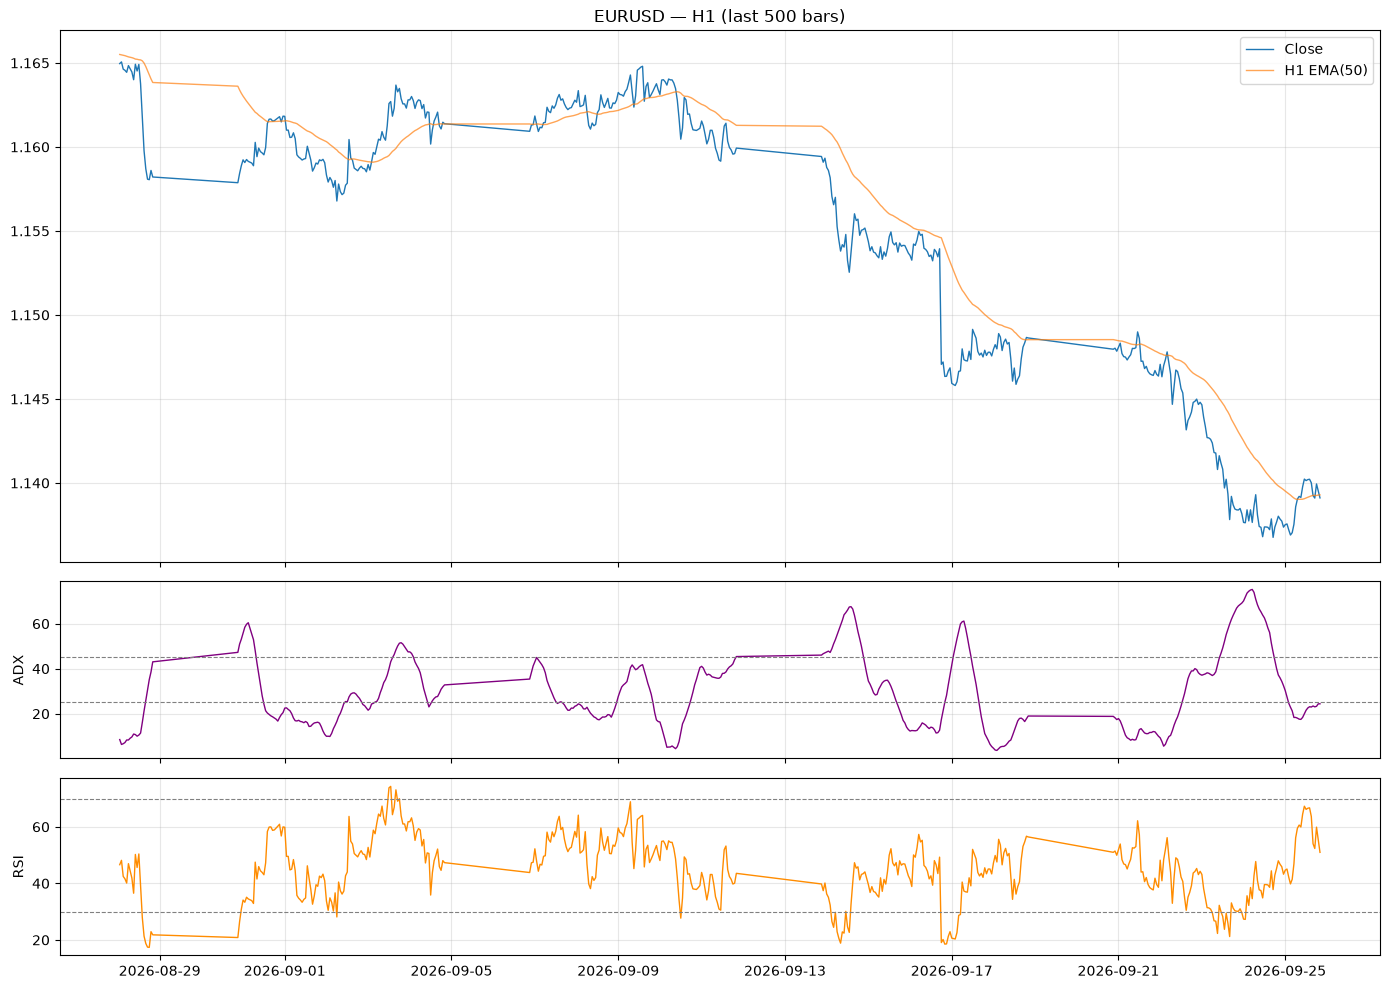

In [6]:
# Plots the first symbol in the portfolio for a quick visual check
first_sym = CONFIG["symbols"][0]
plot_slice = dfs[first_sym].dropna(subset=['atr_14', 'adx', 'rsi_14']).tail(500)

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True, gridspec_kw={'height_ratios': [3, 1, 1]})
axes[0].plot(plot_slice['date'], plot_slice['close'], label='Close', linewidth=1)
axes[0].plot(plot_slice['date'], plot_slice['h1_ema_50'], label='H1 EMA(50)', linewidth=1, alpha=0.7)
axes[0].set_title(f"{first_sym} — {CONFIG['granularity']} (last 500 bars)")
axes[0].legend()
axes[1].plot(plot_slice['date'], plot_slice['adx'], color='purple', linewidth=1)
axes[1].axhline(25, color='gray', linestyle='--', linewidth=0.8)
axes[1].axhline(45, color='gray', linestyle='--', linewidth=0.8)
axes[1].set_ylabel('ADX')
axes[2].plot(plot_slice['date'], plot_slice['rsi_14'], color='darkorange', linewidth=1)
axes[2].axhline(70, color='gray', linestyle='--', linewidth=0.8)
axes[2].axhline(30, color='gray', linestyle='--', linewidth=0.8)
axes[2].set_ylabel('RSI')
plt.tight_layout()
plt.show()

---
## 6. 🎯 STRATEGY DEFINITIONS — 7 case studies + 1 control, numbered 1–8

Each of the 7 breakout videos, plus an 8th control strategy, gets exactly two cells here — a
markdown explanation, then a code cell that defines it. Every strategy's code cell opens with
its own `STRATEGY_<N>_PARAMS` dict (the numbers that specific video actually used, or, for
Strategy 8, a set of textbook defaults), merged with the general `multi_breakout_strategy`
profile (Section 0) at call time: `p = {**profile, **STRATEGY_<N>_PARAMS}`. Shared parameters
(risk %, sessions, exits) live once in the profile; each strategy's own logic parameters live
with that strategy, not scattered across a shared registry.

Strategies 1-7 are each built **as they actually appeared in their source video** — its own
SL/TP, its own entry mechanism, its own exits — not a generic scheme grafted on. Where a source didn't show something, the gap is flagged in that strategy's own markdown (Strategy 3's SL/TP is borrowed from Strategy 2; Strategy 6's ATR stop is a placeholder so the engine can size a position). Two mechanics
needed a real engine extension to reproduce faithfully (documented in Section 9's own
markdown, not hidden): an opt-in RSI early-exit hook, and a `"limit_timeout"` entry-trigger
mode (a genuine pending order, fillable on a wick, cancelled if unfilled). **Strategy 8 is the
one exception to "sourced from a video"** — see its own markdown for why.

**Where the comparisons live:** right after all 8 strategies are defined, Sections 7-9 build
the execution model, risk sizing, and backtesting engine. **9a** then runs all 8 strategies
through that same engine for an across-strategy comparison table, and **9b** charts it. **9c**
diagnoses what the 7 case studies share. **9d**, right after, is where you set `ACTIVE_VARIANT`
to run one strategy individually — everything from Section 10 onward analyzes that one run
in depth.

In [7]:
# --- Shared detection helpers, used by more than one strategy below ---

def mark_pivots(df: pd.DataFrame, window: int) -> tuple:
    """
    Centred rolling-extrema pivot detection — a candle is a pivot high if its High is the
    max of the `2*window+1`-bar window centred on it (pivot low: analogous on Low).
    Matches the video's `mark_pivots` exactly. Returns (is_pivot_high, is_pivot_low) as
    boolean numpy arrays.
    """
    span = 2 * window + 1
    roll_max = df["high"].rolling(span, center=True).max()
    roll_min = df["low"].rolling(span, center=True).min()
    is_ph = ((df["high"] >= roll_max) & roll_max.notna()).values
    is_pl = ((df["low"] <= roll_min) & roll_min.notna()).values
    return is_ph, is_pl


def detect_liquidity_sweep_breakout(df: pd.DataFrame, backcandles: int, pivot_window: int,
                                     confirm_window: int = None) -> tuple:
    """
    Reimplementation of the video's `detect_structure()`, called once per candle in the
    original (with several DataFrame slices per call) — here the pivot positions are
    precomputed once, and each candle's lookup uses `np.searchsorted` for an O(log n) range
    query instead of repeated boolean-mask filtering on a DataFrame slice. Same signal
    output, meaningfully faster on a multi-year hourly series.

    BUGFIX: `pivot_window` and `confirm_window` used to be the same parameter here. The
    source actually uses two different values -- `mark_pivots(window=7)` to decide what
    counts as a pivot at all, but `detect_structure(..., window=5)` for the separate
    "how recent can a confirmed pivot be" cutoff. Defaults to `pivot_window` when not
    given, so any other caller relying on the old single-parameter behavior is unaffected.

    Look-ahead guard, unchanged from the original: a pivot at position p needs `pivot_window`
    bars of future data to confirm (the centred window in mark_pivots), so only pivots with
    p <= candle - confirm_window are used when deciding at `candle` — every pivot referenced
    is confirmable using data available through `candle` itself, never beyond it.

    Returns (signal, pivot_ref_idx) as numpy arrays — signal: 0=none, 1=bullish, 2=bearish
    (matching this notebook's buy/sell convention, not the video's own 2=bullish/1=bearish).
    """
    if confirm_window is None:
        confirm_window = pivot_window
    n = len(df)
    close = df["close"].values
    high = df["high"].values
    low = df["low"].values
    is_ph, is_pl = mark_pivots(df, pivot_window)

    ph_positions = np.flatnonzero(is_ph)
    pl_positions = np.flatnonzero(is_pl)

    signal = np.zeros(n, dtype=np.int8)
    pivot_ref = np.full(n, -1, dtype=np.int64)

    for candle in tqdm(range(backcandles, n), desc="Detecting structure", leave=False):
        prev = candle - 1
        piv_start = candle - backcandles
        piv_end = candle - confirm_window     # inclusive upper bound of CONFIRMABLE pivots

        # --- Bullish: pivot high -> sweep below prior low -> confirmed break back above ---
        lo, hi = np.searchsorted(ph_positions, [piv_start, piv_end + 1])
        if hi > lo:
            ph_idx = ph_positions[hi - 1]      # most recent confirmable pivot high
            ph_val = high[ph_idx]
            if close[candle] > ph_val and close[prev] <= ph_val:   # first candle to break it
                lo_b, hi_b = np.searchsorted(pl_positions, [piv_start, ph_idx])
                lo_a, hi_a = np.searchsorted(pl_positions, [ph_idx + 1, piv_end + 1])
                if hi_b > lo_b and hi_a > lo_a:
                    pl1_val = low[pl_positions[hi_b - 1]]           # last PL before the PH
                    pl2_val = low[pl_positions[lo_a:hi_a]].min()    # lowest PL after the PH
                    if pl2_val < pl1_val:                            # sweep confirmed
                        signal[candle] = 1
                        pivot_ref[candle] = ph_idx
                        continue                # bullish found — matches original priority

        # --- Bearish: symmetric ---
        lo, hi = np.searchsorted(pl_positions, [piv_start, piv_end + 1])
        if hi > lo:
            pl_idx = pl_positions[hi - 1]
            pl_val = low[pl_idx]
            if close[candle] < pl_val and close[prev] >= pl_val:
                lo_b, hi_b = np.searchsorted(ph_positions, [piv_start, pl_idx])
                lo_a, hi_a = np.searchsorted(ph_positions, [pl_idx + 1, piv_end + 1])
                if hi_b > lo_b and hi_a > lo_a:
                    ph1_val = high[ph_positions[hi_b - 1]]
                    ph2_val = high[ph_positions[lo_a:hi_a]].max()
                    if ph2_val > ph1_val:
                        signal[candle] = 2
                        pivot_ref[candle] = pl_idx

    return signal, pivot_ref


STRATEGY_VARIANTS = {}   # each strategy below registers itself into this as it's defined

---
### Strategy 1 — Liquidity Sweep Breakout

*Source: `BreakOut_Liquidity_Sweep`.* A pivot high/low only counts as a real level once
price has swept PAST the opposite-side pivot first (a "liquidity sweep") before breaking
back through it — the idea being that a genuine breakout should be preceded by stop-hunts
clearing out the opposite side's resting orders, not just a clean break on the first try.
Direction is further filtered by an EMA(150) trend condition (the last 15 candles must
ALL sit on one side of the EMA). SL/TP are ATR-based (SL = ATR × 1, TP = 1× that — a 1:1
ratio, as the deliberately lower-risk choice, not the one that
maximizes returns), held until hit — no session window, no time-stop, no trailing. The
source uses two different pivot windows (7 to mark a pivot at all, 5 for the separate
"how recent can a confirmed pivot be" cutoff) — both are distinct params here, but
`confirm_window` is now set to 7, not the source's 5. `mark_pivots` uses a CENTERED
window, so a pivot isn't knowable until `pivot_window` bars after it forms; a
`confirm_window` smaller than `pivot_window` lets the detector use pivots that still
need future data to exist — with the source's original 5/7 split, signals can change
when later bars are removed (no cell in this notebook currently measures that rate, so it stays out of the video until one does:
set `confirm_window=5` and run `lookahead_rate` from Section 16). Matching the two windows to 7 removes the look-ahead by construction, and
the Section 16 check confirms it: none of Strategy 1's checked signals vanish when later bars are removed. Worth its own beat in the video: the
source's own parameters don't hold up to a causality check.

| Field | Detail |
|---|---|
| **Strategy name** | 1 — Liquidity Sweep Breakout |
| **Direction logic** | New low must sweep the prior pivot low before a close back above the pivot high counts as bullish (mirror for bearish) · EMA(150) filter: last 15 candles all on one side of the EMA |
| **Entry trigger** | Close breaks back through the swept pivot, in the EMA-confirmed direction |
| **SL logic** | ATR(14) × 1.0 |
| **TP logic** | 1.0 × SL distance (1:1 R:R) |
| **Timeframe(s)** | H1 |

In [8]:
STRATEGY_1_PARAMS = {
    "ema_trend_period": 150, "ema_trend_bars": 15,
    "pivot_window": 7, "confirm_window": 7, "backcandles": 40,
    "atr_multiplier": 1.0, "tp_sl_ratio": 1.0,
    "min_bars": 200,   # EMA(150) + 15-bar confirmation needs ~165 bars warmup
    "granularity": "H1",

}

def _strategy_1_raw(df: pd.DataFrame, symbol: str, profile: dict):
    """
    Shared raw signal + trigger_level (+ pivot_ref) for the liquidity-sweep-breakout
    direction logic (EMA trend filter + structure detection). Used both by
    `generate_signals_1_liquidity_sweep_breakout` right below and by the entry-trigger
    demo variants later in this section, so this logic -- and the `confirm_window` used
    by `detect_liquidity_sweep_breakout` -- only has to be defined and kept correct once.
    """
    df = df.copy()
    p = {**profile, **STRATEGY_1_PARAMS}
    n = len(df)

    # --- EMA(150) trend filter: last `ema_trend_bars` candles ALL above/below EMA ---
    ema = df["close"].ewm(span=p["ema_trend_period"], adjust=False).mean()
    above = (np.minimum(df["open"], df["close"]) > ema).astype(int)
    below = (np.maximum(df["open"], df["close"]) < ema).astype(int)
    win = p["ema_trend_bars"] + 1
    uptrend = above.rolling(win, min_periods=win).sum() == win
    downtrend = below.rolling(win, min_periods=win).sum() == win

    # --- Structure detection ---
    struct_signal, pivot_ref = detect_liquidity_sweep_breakout(
        df, p["backcandles"], p["pivot_window"], p["confirm_window"])

    ok = np.arange(n) >= p["min_bars"]   # warmup guard
    buy_ok = ok & (struct_signal == 1) & uptrend.values
    sell_ok = ok & (struct_signal == 2) & downtrend.values
    raw_signal = np.select([buy_ok, sell_ok], [1, 2], default=0).astype(np.int8)

    # trigger_level: the specific pivot price this signal broke, so the generic
    # entry-trigger layer (Part 2, Section 6c) can act on it without knowing anything
    # about how liquidity-sweep-breakout works internally.
    high_arr, low_arr = df["high"].values, df["low"].values
    trigger_level = np.full(n, np.nan)
    long_ok = (raw_signal == 1) & (pivot_ref >= 0)
    short_ok = (raw_signal == 2) & (pivot_ref >= 0)
    trigger_level[long_ok] = high_arr[pivot_ref[long_ok]]
    trigger_level[short_ok] = low_arr[pivot_ref[short_ok]]

    return df, raw_signal, trigger_level, pivot_ref


def generate_signals_1_liquidity_sweep_breakout(df: pd.DataFrame, symbol: str, profile: dict) -> pd.DataFrame:
    """
    Liquidity Sweep Breakout — Price has to fake out first, then break out for real. 
    It watches for a swing high/low, waits for price to poke past the opposite swing 
    (stop-hunt territory), and only then treats a close back through the original level 
    as a real breakout. Only trades with the trend (last 15 candles all above/below a 150 EMA). 
    Stop = 1×ATR, target = same distance (1:1).
    
    Fulfils the same contract every strategy
    in this template must: adds `signal` (0/1/2), `sl_pips`/`tp_pips`, `strategy_name`,
    and `is_closed`. `is_closed` is no longer set here — Section 3 now computes it
    generically for every symbol (weekend + US holiday calendar), so every variant,
    old and new, gets the same accurate calendar without redefining it.

    Direction logic itself now lives in `_strategy_1_raw` (shared with the entry-trigger
    demo variants below) -- this function just layers `signal`/`trigger_level`/ATR SL-TP
    on top of it.
    """
    df, raw_signal, trigger_level, pivot_ref = _strategy_1_raw(df, symbol, profile)
    p = {**profile, **STRATEGY_1_PARAMS}

    df["signal"] = raw_signal
    df["pivot_ref_idx"] = pivot_ref
    df["trigger_level"] = trigger_level

    # --- SL/TP from ATR, exactly as the video: SL = ATR * atr_multiplier, TP = SL * tp_sl_ratio ---
    sl_dist_pips = df["atr_pips"] * p["atr_multiplier"]
    df["sl_pips"] = sl_dist_pips
    df["tp_pips"] = sl_dist_pips * p["tp_sl_ratio"]
    df["strategy_name"] = "Liquidity Sweep Breakout"

    return df


STRATEGY_VARIANTS["1_liquidity_sweep_breakout"] = generate_signals_1_liquidity_sweep_breakout


---
### Strategy 2 — Level Break Out (Daily)

*Source: `_LevelBreakOut_EURUSD_D1`.* Requires THREE recent pivot highs (or lows) within
a pip tolerance of each other before treating it as a real level — stronger confirmation
than a single pivot, fewer signals as the cost. Breakout fires when close clears the zone
by a margin. SL = **3% of the entry price** (a genuinely different idea from ATR: a stop
that scales with the price level itself, not with recent volatility or the broken level).
TP = 2× that distance. The source ALSO closes a trade early once RSI clears 80 (long) or
drops below 20 (short) — this needs Section 9's RSI early-exit hook switched on
(`profile["early_exit_enabled"] = True`) to actually reproduce; left off by default so
every OTHER strategy's results stay unaffected. Entry is immediate (same bar's close), no
entry-trigger layer. **Source ran on DAILY bars** — run this on granularity="D", not this
notebook's H1 default, to match.

| Field | Detail |
|---|---|
| **Strategy name** | 2 — Level Break Out (Daily) |
| **Direction logic** | 3 confirmed pivot highs (or lows) within a pip tolerance form a zone |
| **Entry trigger** | Close clears the zone by a margin (`margin_pips`) — same-bar entry, no separate trigger layer |
| **SL logic** | 3% of entry price |
| **TP logic** | 2.0 × SL distance |
| **Timeframe(s)** | D (source ran on daily bars — do not use this notebook's H1 default) |


In [9]:
STRATEGY_2_PARAMS = {
    "pivot_window": 6, "confirm_window": 6,   # source uses the same window for both
    "backcandles": 40,
    "zone_width_pips": 100.0, "margin_pips": 200.0,
    "sl_pct": 0.03, "tp_sl_ratio": 2.0,
    "min_bars": 0,   # daily bars -- backcandles/pivot_window alone are enough warmup
    "granularity": "D", "early_exit_enabled": True,
}


def generate_signals_2_level_break_out_daily(df: pd.DataFrame, symbol: str, profile: dict,
                                              params: dict = None) -> pd.DataFrame:
    """
    Level Break Out (Daily) — Needs 3 separate price touches near the same level before 
    it calls that level "real" (more confirmation = fewer, more selective signals). 
    Once confirmed, a close that clears the level by a margin is the trade. Stop is a 
    flat 3% of price (ignores volatility), target is 2× that. Runs on daily candles.
    
    """
    df = df.copy()
    strat_params = params if params is not None else STRATEGY_2_PARAMS
    p = {**profile, **strat_params}
    n = len(df)
    ps = pip_size(symbol)
    zone_width = p["zone_width_pips"] * ps
    margin = p["margin_pips"] * ps

    is_ph, is_pl = mark_pivots(df, p["pivot_window"])
    ph_idx_all = np.flatnonzero(is_ph)
    pl_idx_all = np.flatnonzero(is_pl)
    high, low, close = df["high"].values, df["low"].values, df["close"].values

    signal = np.zeros(n, dtype=np.int8)
    trigger_level = np.full(n, np.nan)

    confirm_window = p.get("confirm_window", p["pivot_window"])
    for candle in tqdm(range(p["backcandles"] + confirm_window + 1, n), desc=f"[{symbol}] Level Break Out (Daily) scan"):
        piv_end = candle - confirm_window
        piv_start = candle - p["backcandles"] - confirm_window
        if piv_start < 0:
            continue
        lo_h, hi_h = np.searchsorted(ph_idx_all, [piv_start, piv_end])
        lo_l, hi_l = np.searchsorted(pl_idx_all, [piv_start, piv_end])
        recent_highs = ph_idx_all[lo_h:hi_h][-3:]
        recent_lows = pl_idx_all[lo_l:hi_l][-3:]

        if len(recent_lows) == 3:
            lows = low[recent_lows]
            mean_low = lows.mean()
            if np.all(np.abs(lows - mean_low) <= zone_width) and (mean_low - close[candle]) > margin:
                signal[candle] = 2
                trigger_level[candle] = mean_low
        if len(recent_highs) == 3:
            highs = high[recent_highs]
            mean_high = highs.mean()
            if np.all(np.abs(highs - mean_high) <= zone_width) and (close[candle] - mean_high) > margin:
                signal[candle] = 1
                trigger_level[candle] = mean_high

    df["signal"] = signal
    df["pivot_ref_idx"] = -1
    df["trigger_level"] = trigger_level

    sl_price_dist = close * p["sl_pct"]
    df["sl_pips"] = np.where(signal != 0, sl_price_dist / ps, np.nan)
    df["tp_pips"] = df["sl_pips"] * p["tp_sl_ratio"]
    df["strategy_name"] = "Level Break Out (Daily)"
    return df


STRATEGY_VARIANTS["2_level_break_out_daily"] = generate_signals_2_level_break_out_daily


---
### Strategy 3 — Level Break Out (H1 companion)

*Source: `_LevelBreakOut_EURUSD_H1`.* The same creator's own companion notebook — but it
only ever shows the pivot/pattern DETECTION running on H1 data; there's no `Strategy`
class, no SL/TP, no backtest in it at all. Unlike an earlier pass at this variant, the
DETECTION here is not just Strategy 2 reused on a different timeframe — this source
notebook has its own distinct numbers for it: pivot window 10 (not Daily's 6), confirm
window 11 (its own comment is explicit that this must exceed the pivot window — Strategy
2's source uses equal windows, this one doesn't), backcandles 60 (not 40), zone width 10
pips / margin 20 pips (not 100/200 — an order of magnitude tighter, which makes sense on
H1 vs. daily bars). Only the SL/TP is genuinely borrowed from Strategy 2 — that part truly
isn't shown here, and there's no faithful H1-native alternative to fall back on. Run on
granularity="H1".

**Caution — do not present this as a survivor.** Strategy 3's exit is dominated by the RSI early-exit hook, which is *also*
borrowed from Strategy 2 and not verified in this source. Section 9a-iii separates what the hook does: with it on, the strategy
ends slightly positive whether or not the hook may fire on the entry bar (so entry-bar exits are *not* the explanation); with it
off (stop / take-profit only), it loses. The small positive result therefore exists only because of an exit rule this source never
showed. Quote the hook-off row (R13) next to the 9a row.

| Field | Detail |
|---|---|
| **Strategy name** | 3 — Level Break Out (H1 companion) |
| **Direction logic** | Same zone logic as Strategy 2, own numbers: pivot window 10, confirm window 11, zone 10 pips / margin 20 pips |
| **Entry trigger** | Close clears the zone by a margin — same-bar entry |
| **SL logic** | 3% of entry price (borrowed from Strategy 2 — not shown in this source, unverified) |
| **TP logic** | 2.0 × SL distance (borrowed from Strategy 2) |
| **Timeframe(s)** | H1 |


In [10]:
STRATEGY_3_PARAMS = {
    # This source's OWN detection numbers -- not copied from Strategy 2, see markdown above.
    "pivot_window": 10, "confirm_window": 11, "backcandles": 60,
    "zone_width_pips": 10.0, "margin_pips": 20.0,
    # SL/TP has no source in this video at all -- borrowed from Strategy 2 as the closest
    # available stand-in (see markdown). Genuinely not video-verified, unlike everything above.
    "sl_pct": 0.03, "tp_sl_ratio": 2.0,
    "min_bars": 0,
    "granularity": "H1", "early_exit_enabled": True,
}


def generate_signals_3_level_break_out_h1(df: pd.DataFrame, symbol: str, profile: dict) -> pd.DataFrame:
    """
    Companion to Strategy 2, but with this source's OWN detection parameters (pivot/confirm
    window, backcandles, zone width -- all different from Strategy 2's Daily numbers, see
    markdown above). Reuses Strategy 2's function body (same detection algorithm, different
    parameters) and its SL/TP as a stand-in, since this source shows no backtest at all.
    """
    df2 = generate_signals_2_level_break_out_daily(df, symbol, profile, params=STRATEGY_3_PARAMS)
    df2["strategy_name"] = "Level Break Out (H1 companion)"
    return df2


STRATEGY_VARIANTS["3_level_break_out_h1"] = generate_signals_3_level_break_out_h1


---
### Strategy 4 — Channel Breakout (Regression)

*Source: `BreakOut_Strategy_` (first/simpler version).* Fits a linear regression line
through the last 3 confirmed pivot highs, and separately the last 3 pivot lows; requires
the two lines be roughly parallel and both R² > 0.9 before calling it a real channel.
Breakout fires when price clears the sloped line, requiring at least 2 confirmed pivots on
EACH side *and* at least 5 total between them (i.e. one side must have all 3) before it will
even attempt the fit. The strictest, most selective direction logic in this whole set of 7.
SL = 3% of price, TP = **1.5×** that (tighter than Level Break Out's 2:1). Immediate entry, no RSI exit in this version. The source's own second,
more elaborate version — a limit-order entry with a 2-bar cancel, RSI exit, 1.8:1 R:R —
has its entry mechanism demonstrated separately in the Entry-Trigger Variants
subsection just below (`"limit_timeout"` mode) rather than being built as an 8th case study.

| Field | Detail |
|---|---|
| **Strategy name** | 4 — Channel Breakout (Regression) |
| **Direction logic** | Regression line through the last 3 confirmed pivot highs and, separately, the last 3 pivot lows; lines must be roughly parallel and both R² > 0.9 — needs ≥2 confirmed pivots per side and ≥5 total |
| **Entry trigger** | Close clears the sloped regression line |
| **SL logic** | 3% of entry price |
| **TP logic** | 1.5 × SL distance |
| **Timeframe(s)** | H1 |


In [11]:
STRATEGY_4_PARAMS = {
    "pivot_window": 5, "backcandles": 40,
    "parallel_tol": 0.1, "r_sq_threshold": 0.9,
    "sl_pct": 0.03, "tp_sl_ratio": 1.5,
    "min_bars": 0,
    "granularity": "H1",
}

def generate_signals_4_channel_breakout(df: pd.DataFrame, symbol: str, profile: dict) -> pd.DataFrame:
    """
    Instead of a flat level, it fits a sloped line through 3 recent highs and 3 recent lows 
    and only counts it as a channel if both lines are roughly parallel and a good statistical fit. 
    Breakout = price closes past the sloped line, not a horizontal one. Stop = 3% of price, target = 1.5× that.
    """
    df = df.copy()
    p = {**profile, **STRATEGY_4_PARAMS}
    n = len(df)
    is_ph, is_pl = mark_pivots(df, p["pivot_window"])
    ph_idx_all = np.flatnonzero(is_ph)
    pl_idx_all = np.flatnonzero(is_pl)
    high, low, close, open_ = df["high"].values, df["low"].values, df["close"].values, df["open"].values

    signal = np.zeros(n, dtype=np.int8)
    trigger_level = np.full(n, np.nan)

    for candle in tqdm(range(p["backcandles"] + p["pivot_window"] + 1, n), desc=f"[{symbol}] Channel Breakout scan"):
        piv_end = candle - p["pivot_window"]
        piv_start = candle - p["backcandles"] - p["pivot_window"]
        if piv_start < 0:
            continue
        lo_h, hi_h = np.searchsorted(ph_idx_all, [piv_start, piv_end + 1])
        lo_l, hi_l = np.searchsorted(pl_idx_all, [piv_start, piv_end + 1])
        recent_highs_idx = ph_idx_all[lo_h:hi_h][-3:]
        recent_lows_idx = pl_idx_all[lo_l:hi_l][-3:]
        # Source's own gate: >=2 confirmed pivots on EACH side AND >=5 total between them --
        # i.e. at least one side must have all 3. An earlier pass at this variant only checked
        # the per-side >=2 parts and dropped the combined >=5 check, slightly loosening the
        # source's own filter (letting a 2-and-2 configuration through that the video would not).
        if len(recent_highs_idx) < 2 or len(recent_lows_idx) < 2:
            continue
        if (len(recent_highs_idx) + len(recent_lows_idx)) < 5:
            continue

        sl_h, ic_h, r_h, _, _ = _scipy_stats.linregress(recent_highs_idx, high[recent_highs_idx])
        sl_l, ic_l, r_l, _, _ = _scipy_stats.linregress(recent_lows_idx, low[recent_lows_idx])
        r_sq_h, r_sq_l = r_h ** 2, r_l ** 2
        if p["parallel_tol"] > 0 and abs((sl_l - sl_h) / (sl_h + sl_l + 1e-12)) / 2 > p["parallel_tol"]:
            continue
        if r_sq_h < p["r_sq_threshold"] or r_sq_l < p["r_sq_threshold"]:
            continue

        prev = candle - 1
        lower_now, lower_prev = sl_l * candle + ic_l, sl_l * prev + ic_l
        upper_now, upper_prev = sl_h * candle + ic_h, sl_h * prev + ic_h

        if open_[candle] < lower_now and close[candle] < lower_prev:
            signal[candle] = 2
            trigger_level[candle] = lower_now
        elif open_[candle] > upper_now and close[candle] > upper_prev:
            signal[candle] = 1
            trigger_level[candle] = upper_now

    df["signal"] = signal
    df["pivot_ref_idx"] = -1
    df["trigger_level"] = trigger_level
    ps = pip_size(symbol)
    sl_price_dist = close * p["sl_pct"]
    df["sl_pips"] = np.where(signal != 0, sl_price_dist / ps, np.nan)
    df["tp_pips"] = df["sl_pips"] * p["tp_sl_ratio"]
    df["strategy_name"] = "Channel Breakout"
    return df


STRATEGY_VARIANTS["4_channel_breakout"] = generate_signals_4_channel_breakout


---
### Strategy 5 — Box Range Breakout

*Source: `Box`.* No pivots at all — just the highest high / lowest low of the previous
`box_size` candles, held constant and refreshed only every `box_size` bars (an opening-
range-style box, not a continuously-updating Donchian channel). Breakout = close beyond
the held box. SL = the **signal candle's own low/high** — a tight structural stop, not
ATR- or price-percentage-based. TP = 2× that. Immediate entry. The source's manual spread
sanity check is superseded here by Section 7's own realistic execution/friction model, so
it's intentionally not reproduced as a separate check.

**Timeframe and window:** the source ran `box_size=5` on **1-MINUTE** data — a genuine
5-*minute* box — over about **2 years**. This notebook does the same: `granularity="M1"`,
`days=730`. Every other strategy still uses the shared 20-year window, so this row is a
*shorter* sample (the 9a table shows each strategy's window). On the H1 default the same
`box_size=5` would give a 5-*hour* box, a materially different strategy —
`run_all_strategies(..., force_default_granularity=True)` reproduces that H1 variant if you
want to compare.

**Leverage cap:** a signal-candle stop on 1-minute bars is often only 1–3 pips, and
fixed-fractional sizing (1% risk ÷ stop distance) turns that into roughly 35–110× notional
leverage on a $10k account. So this strategy's params set `max_leverage=5.0` (the same cap
the production risk manager uses). Set it to `None` to see the uncapped version. Every other
strategy is unchanged (no cap).

| Field | Detail |
|---|---|
| **Strategy name** | 5 — Box Range Breakout |
| **Direction logic** | Highest high / lowest low of the previous `box_size` candles, held constant and refreshed only every `box_size` bars |
| **Entry trigger** | Close beyond the held box |
| **SL logic** | Signal candle's own low/high |
| **TP logic** | 2.0 × SL distance |
| **Timeframe(s)** | M1, 730 days — matches the source's ~2-year 1-minute window |
| **Leverage cap** | 5× (this strategy only; see above) |


In [12]:
STRATEGY_5_PARAMS = {
    "box_size": 5, 
    "dedup_block_size": 5,
    "tp_sl_ratio": 2.0, 
    "min_bars": 0,
    "granularity": "M1",   # source ran box_size=5 on 1-MINUTE bars -> a genuine 5-minute box
    "days": 730,           # ...over ~2 years; every other strategy keeps the shared 20-year CONFIG["days"]
    "max_leverage": 5.0,   # fixed sizing has no leverage cap; a 1-3 pip M1 stop would otherwise mean ~35-110x. None = uncapped
}

def generate_signals_5_box_range_breakout(df: pd.DataFrame, symbol: str, profile: dict) -> pd.DataFrame:
    """
    Simplest one: take the highest high and lowest low of the last few candles, freeze that box, 
    and wait for a close outside it. The box only updates every N candles, not every bar — that's 
    what makes it a "box" instead of a rolling channel. Stop = that signal candle's own high/low, 
    target = 2× that. Runs on the source's own 1-minute candles (2 years, see STRATEGY_5_PARAMS);
    on H1 the same box_size=5 would be a 5-HOUR box, a meaningfully different strategy.
    
    """
    df = df.copy()
    p = {**profile, **STRATEGY_5_PARAMS}
    n = len(df)
    high, low, close = df["high"].values, df["low"].values, df["close"].values

    # dt.minute % box_size only works when each bar IS 1 minute (source's actual M1 data).
    # On H1/H2 bars .dt.minute is always 0, so this fired on EVERY bar, and the box was
    # never actually held -- it silently became a plain rolling max/min. Fixed to refresh
    # every box_size bars' worth of REAL wall-clock minutes (derived from the data's own
    # bar spacing), which reduces to the source's exact M1 behavior and stays genuinely
    # "held" on any other granularity too.
    if n > 1:
        bar_minutes = max(1, int(round(df["date"].diff().dt.total_seconds().median() / 60)))
    else:
        bar_minutes = 1
    box_minutes = bar_minutes * p["box_size"]
    minutes_since_epoch = df["date"].dt.as_unit("ns").astype("int64").values // 10**9 // 60
    box_start = (minutes_since_epoch % box_minutes == 0)
    raw_max_box = pd.Series(high).shift(1).rolling(p["box_size"]).max()
    raw_min_box = pd.Series(low).shift(1).rolling(p["box_size"]).min()
    max_box = raw_max_box.where(box_start).ffill().values
    min_box = raw_min_box.where(box_start).ffill().values

    raw_signal = np.zeros(n, dtype=np.int8)
    raw_signal[close > max_box] = 1
    raw_signal[close < min_box] = 2

    signal = np.zeros(n, dtype=np.int8)
    block = np.arange(n) // p["dedup_block_size"]
    seen = set()
    for i in range(n):
        sgn = raw_signal[i]
        if sgn == 0:
            continue
        key = (block[i], sgn)
        if key not in seen:
            seen.add(key)
            signal[i] = sgn

    df["signal"] = signal
    df["pivot_ref_idx"] = -1
    df["trigger_level"] = np.where(signal == 1, max_box, np.where(signal == 2, min_box, np.nan))

    ps = pip_size(symbol)
    sl_price_dist = np.where(signal == 1, close - low, np.where(signal == 2, high - close, np.nan))
    df["sl_pips"] = sl_price_dist / ps
    df["tp_pips"] = df["sl_pips"] * p["tp_sl_ratio"]
    df["strategy_name"] = "Box Range Breakout"
    return df


STRATEGY_VARIANTS["5_box_range_breakout"] = generate_signals_5_box_range_breakout


---
### Strategy 6 — Candle-Bias Session ORB

*Source: `01_CandlePattern_JPY_SessionStrategy`.* Yesterday's daily candle color sets
today's directional bias. A genuine STOP order is then placed at the extreme of the day's
first `test_candles` bars (an opening-range level) in the bias direction, filled the first
time price actually trades through it — High/Low, matching a real stop order, not a
Close-based approximation — at most once per day. Daily bias is computed directly from
this dataframe's own bars grouped by date, no separate daily fetch needed.

**The header finding for this whole video project:** the source places **neither an SL nor
a TP** on this stop order at all — that part is unchanged and confirmed. But risk is NOT
bounded by a same-session close: the source's own executed run uses `test_candles=8` on
its actual 2-HOUR bars (hence `granularity="H2"` above, not this notebook's H1 default) and
`exit_delay_days=4` — a pending stop order set up on day D, at day D's own opening-range
extreme, stays live for up to 4 days, ignoring every later day's own bias/opening-range
until it either fills or expires, and once filled the position isn't force-closed until end
of day D+4 either (`profile["exit_delay_days"]`, consumed by Section 9's engine). Because
this engine still needs an SL distance to size a position, the same wide placeholder (5×
ATR, floored at 50 pips) is used below, still invented for engine compatibility. Treat any
sizing-dependent number from this strategy (position size, $ risked, risk-of-ruin) as an
artifact of that placeholder — only the entry/exit MECHANICS are faithful.

| Field | Detail |
|---|---|
| **Strategy name** | 6 — Candle-Bias Session ORB |
| **Direction logic** | Yesterday's daily candle color sets today's directional bias |
| **Entry trigger** | Genuine stop order at the extreme of the day's first `test_candles` bars, filled on High/Low touch — at most once per day |
| **SL logic** | None in the source (placeholder 5×ATR, floored at 50 pips, used only so the engine can size a position) |
| **TP logic** | None in the source |
| **Timeframe(s)** | H2 · pending stop stays live up to `exit_delay_days`=4, position force-closed end of day D+4 |


In [13]:
STRATEGY_6_PARAMS = {
    "test_candles": 8, "min_bars": 0,
    "granularity": "H2", "hard_close_hour": 23, 
    "hard_close_minute": 0, "exit_delay_days": 4,
}


def generate_signals_6_candle_bias_session_orb(df: pd.DataFrame, symbol: str, profile: dict) -> pd.DataFrame:
    """
    Yesterday's daily candle color (green or red) sets today's bias. Then it places a real 
    pending stop order at the high or low of the first few hours of today, in that bias direction, 
    and waits for price to actually trade through it. Biggest thing to know: the original has
    no stop-loss and no take-profit at all — just a time-based exit. Any SL you see for this one 
    in the notebook is a placeholder bolted on so the backtest engine has something to size a 
    position with — it's not part of the real strategy.
    
    """
    df = df.copy()
    p = {**profile, **STRATEGY_6_PARAMS}
    n = len(df)
    dates = df["date"].dt.date.values
    high, low, close = df["high"].values, df["low"].values, df["close"].values

    day_df = df.groupby(df["date"].dt.date).agg(day_open=("open", "first"), day_close=("close", "last"))
    day_df["bias"] = np.where(day_df["day_close"] > day_df["day_open"], 1,
                       np.where(day_df["day_close"] < day_df["day_open"], 2, 0))
    day_df["bias"] = day_df["bias"].shift(1).fillna(0).astype(int)
    bias_map = day_df["bias"].to_dict()
    bar_bias = np.array([bias_map.get(d, 0) for d in dates])

    signal = np.zeros(n, dtype=np.int8)
    trigger_level = np.full(n, np.nan)
    day_start_idx = np.flatnonzero(np.r_[True, dates[1:] != dates[:-1]])
    day_end_idx = np.r_[day_start_idx[1:], n]
    tc = p["test_candles"]

    n_days = len(day_start_idx)
    exit_delay_days = p.get("exit_delay_days", 1)

    # Day-by-day state machine: at most one pending order at a time, its level fixed on
    # the day it was set (a later day's own bias/opening-range never overrides an
    # already-pending order) -- matches the source's own len(self.orders)==0 gating,
    # where the order stays live (GTC) through day D+exit_delay_days.
    active_order = None   # {"direction", "level", "expire_end", "scan_from"}
    for d in range(n_days):
        start, end = day_start_idx[d], day_end_idx[d]

        if active_order is None and end - start > tc:
            bias = bar_bias[start]
            if bias != 0:
                or_high = high[start:start + tc].max()
                or_low = low[start:start + tc].min()
                expire_day = min(d + exit_delay_days, n_days - 1)
                active_order = {
                    "direction": bias,
                    "level": or_high if bias == 1 else or_low,
                    "expire_end": day_end_idx[expire_day] - 1,
                    "scan_from": start + tc,   # skip today's own test-candle window
                }

        if active_order is not None:
            scan_from = max(active_order["scan_from"], start)
            scan_end = min(end, active_order["expire_end"] + 1)
            filled = False
            direction, level = active_order["direction"], active_order["level"]
            for i in range(scan_from, scan_end):
                if direction == 1 and high[i] >= level:
                    signal[i] = 1
                    trigger_level[i] = level
                    filled = True
                    break
                elif direction == 2 and low[i] <= level:
                    signal[i] = 2
                    trigger_level[i] = level
                    filled = True
                    break
            if filled or active_order["expire_end"] < end:
                active_order = None   # filled, or its expiry day has now fully elapsed

    df["signal"] = signal
    df["pivot_ref_idx"] = -1
    df["trigger_level"] = trigger_level

    placeholder_sl_pips = (df["atr_pips"] * 5.0).clip(lower=50.0)
    df["sl_pips"] = np.where(signal != 0, placeholder_sl_pips, np.nan)
    df["tp_pips"] = np.where(signal != 0, 99999.0, np.nan)
    df["strategy_name"] = "Candle-Bias Session ORB"
    return df


STRATEGY_VARIANTS["6_candle_bias_session_orb"] = generate_signals_6_candle_bias_session_orb


---
### Strategy 7 — FVG + Key Level Break

*Source: `FVG_Strategy`.* Direction logic and entry trigger are fused into one condition
here, unlike Strategies 1–6 above: a signal only fires on a bar that BOTH (a) forms a
fair value gap (a 3-candle imbalance, middle candle's body above a body-size threshold)
AND (b) the previous candle just closed through a recent swing high/low key level, in the
gap's own direction. Two corrections from the source: its signal convention was flipped
(2=bullish there, 1=bullish here) and its key-level pip offset was hardcoded to EURUSD,
now generalized via `pip_size(symbol)`. SL = the candle BEFORE the signal bar's own low/
high, TP = `tp_sl_ratio` × that — native to the source, not this notebook's shared scheme.
`tp_sl_ratio` here (1.8) is the source class's own default; the source's actual reported
run instead optimized this over a 1.0-2.2 grid, landing on 31.49% return but a -73.45%
max drawdown — numbers its own creator calls out explicitly on camera: "as a strategy as
is... it's not a good strategy," despite the positive return. 

| Field | Detail |
|---|---|
| **Strategy name** | 7 — FVG + Key Level Break |
| **Direction logic** | Fused with entry trigger (see next column) — no separate direction step |
| **Entry trigger** | Bar both forms a fair value gap (3-candle imbalance, middle body > threshold) AND the previous candle just closed through a recent swing high/low key level, in the gap's direction |
| **SL logic** | Prior candle's (the one before the signal bar) own low/high |
| **TP logic** | `tp_sl_ratio` (1.8) × SL distance |
| **Timeframe(s)** | H1 |


In [14]:
STRATEGY_7_PARAMS = {
    "fvg_lookback": 10, "fvg_body_multiplier": 1.5,
    "level_backcandles": 50, "level_test_candles": 10,
    "tp_sl_ratio": 1.8, "min_bars": 0,
    "granularity": "H1",
}


def generate_signals_7_fvg_key_level_break(df: pd.DataFrame, symbol: str, profile: dict) -> pd.DataFrame:
    """
    Looks for a 3-candle gap pattern (price leaves a hole behind, a "fair value gap") 
    that also happens to close through a recent swing high/low at the same time. When both 
    line up on one candle, that's the entry — direction and trigger are the same event here,
    not two separate steps. Stop = the candle before entry's own high/low, target = 1.8× that.
    
    """
    df = df.copy()
    p = {**profile, **STRATEGY_7_PARAMS}
    n = len(df)
    high, low, open_, close = df["high"].values, df["low"].values, df["open"].values, df["close"].values
    ps = pip_size(symbol)

    body = np.abs(close - open_)
    avg_body = pd.Series(body).shift(1).rolling(p["fvg_lookback"], min_periods=1).mean().values
    avg_body = np.where(avg_body > 0, avg_body, 0.001)

    fvg_type = np.zeros(n, dtype=np.int8)
    for i in range(2, n):
        first_high, first_low = high[i - 2], low[i - 2]
        mid_body = body[i - 1]
        third_low, third_high = low[i], high[i]
        if third_low > first_high and mid_body > avg_body[i - 1] * p["fvg_body_multiplier"]:
            fvg_type[i] = 1
        elif third_high < first_low and mid_body > avg_body[i - 1] * p["fvg_body_multiplier"]:
            fvg_type[i] = 2

    lbc, ltc = p["level_backcandles"], p["level_test_candles"]
    is_res = np.zeros(n, dtype=bool)
    is_sup = np.zeros(n, dtype=bool)
    for i in range(ltc, n - ltc):
        before_hi = high[max(0, i - ltc):i].max()
        after_hi = high[i + 1:i + 1 + ltc].max()
        if high[i] > before_hi and high[i] > after_hi:
            is_res[i] = True
        before_lo = low[max(0, i - ltc):i].min()
        after_lo = low[i + 1:i + 1 + ltc].min()
        if low[i] < before_lo and low[i] < after_lo:
            is_sup[i] = True

    res_idx = np.flatnonzero(is_res)
    sup_idx = np.flatnonzero(is_sup)

    signal = np.zeros(n, dtype=np.int8)
    trigger_level = np.full(n, np.nan)

    for i in tqdm(range(lbc + ltc, n), desc=f"[{symbol}] FVG + key-level scan"):
        if fvg_type[i] == 0:
            continue
        piv_end = i - ltc
        piv_start = i - lbc - ltc
        prev_open, prev_close = open_[i - 1], close[i - 1]

        if fvg_type[i] == 1:
            lo, hi = np.searchsorted(res_idx, [piv_start, piv_end + 1])
            for lvl_idx in res_idx[lo:hi]:
                lvl_price = high[lvl_idx]
                if prev_open < lvl_price < prev_close:
                    signal[i] = 1
                    trigger_level[i] = lvl_price
                    break
        elif fvg_type[i] == 2:
            lo, hi = np.searchsorted(sup_idx, [piv_start, piv_end + 1])
            for lvl_idx in sup_idx[lo:hi]:
                lvl_price = low[lvl_idx]
                if prev_open > lvl_price > prev_close:
                    signal[i] = 2
                    trigger_level[i] = lvl_price
                    break

    df["signal"] = signal
    df["pivot_ref_idx"] = -1
    df["trigger_level"] = trigger_level

    low_prev = pd.Series(low).shift(1).values
    high_prev = pd.Series(high).shift(1).values
    sl_price_dist = np.where(signal == 1, close - low_prev, np.where(signal == 2, high_prev - close, np.nan))
    df["sl_pips"] = sl_price_dist / ps
    df["tp_pips"] = df["sl_pips"] * p["tp_sl_ratio"]
    df["strategy_name"] = "FVG + Key Level Break"
    return df


STRATEGY_VARIANTS["7_fvg_key_level_break"] = generate_signals_7_fvg_key_level_break

print("All 7 strategies registered:", list(STRATEGY_VARIANTS.keys()))


All 7 strategies registered: ['1_liquidity_sweep_breakout', '2_level_break_out_daily', '3_level_break_out_h1', '4_channel_breakout', '5_box_range_breakout', '6_candle_bias_session_orb', '7_fvg_key_level_break']


---
### Strategy 8 — The Control Breakout (Donchian + ADX)

Not sourced from any video. Section 9c, later in this notebook, walks through six recurring
design flaws found across the 7 case studies above — this strategy was built with none of
them, using only textbook-default parameters chosen before this backtest was ever run. The
point isn't to produce a winning strategy — it's to isolate one variable and see what a
breakout strategy free of these specific flaws actually does with real costs, whatever that
turns out to be.

| Flaw fixed | How |
|---|---|
| Flat, non-adaptive stops (Strategies 2, 3, 4) | SL = 2× ATR — scales with real volatility |
| No genuine trend/regime filter (6 of 7; Strategy 6's prior-day candle colour is a directional bias, not a regime test) | Only fires when ADX(14) > 25 — a genuine trending-market gate |
| Curve-fit parameter (Strategy 7) | Every number here is a textbook default (Donchian 55, ADX 25, 2×ATR stop, the profile's default 2.5×ATR trail; no fixed take-profit) — none tuned against this notebook's own EURUSD chart |
| Timeframe mismatch (Strategy 5) | Donchian-55 is the Turtle system's number, defined on **daily** bars — so this runs on Daily, not H1, the same granularity the number was actually built for |
| Borrowed, unverified risk logic (Strategy 3) | Fully self-contained — its own SL/TP, nothing transplanted |
| Single-pair validation (all 7, in their original videos) | Inherits the same `MAJOR_PAIRS` portfolio profile as every other strategy here |

Classic Donchian channel breakout: close clears the prior 55 **daily** bars' high/low, gated by
the shared Wilder ADX(14) column from Section 3 — no new indicator. SL = 2× ATR, exit is a
2.5×ATR trailing stop (no fixed TP) so winners aren't capped early. Entries, the
initial stop and the trailing stop are all evaluated on **Daily** bars (stops are tested against each daily bar's
high/low; the trail ratchets on each daily close using daily ATR). The H1 frame is loaded only to build the
multi-timeframe bias column — the engine does **not** check exits intrabar on H1. Because the trail (2.5×ATR) is looser
than the initial stop (2×ATR), the stop only starts tightening after price has moved more than 0.5 ATR in the trade's favour.


| Field | Detail |
|---|---|
| **Strategy name** | 8 — Control Breakout (Donchian + ADX) |
| **Direction logic** | Close clears the prior 55 daily bars' Donchian high/low, gated by ADX(14) > 25 |
| **Entry trigger** | Close breaks the Donchian(55) band on the Daily bar, with ADX(14) > 25 at that bar |
| **SL logic** | 2.0 × ATR(14) |
| **TP logic** | No fixed TP — 2.5×ATR trailing stop; exits checked on Daily bars |
| **Timeframe(s)** | D for entries and exits (H1 loaded for the bias column only) |



Results and conclusion: see section 15


In [15]:
STRATEGY_8_PARAMS = {
    "donchian_period": 55,
    "adx_threshold": 25.0,
    "atr_multiplier": 2.0,
    "tp_sl_ratio": 2.0,           # unused while exit_mode="atr_trail" is active (see below)
    "min_bars": 60,
    "granularity": "D",           # Donchian-55 is a daily-bar concept (Turtle system) --
                                   # running it on H1 was the actual bug in the original
                                   # version of this strategy, not the parameters. See
                                   # markdown above and 9c/9d.
    "exit_mode": "atr_trail",     # let winners run via a trailing stop instead of a fixed TP
    "atr_trail_multiplier": 2.5,  # matches PROFILE's own default trail distance
}

def generate_signals_8_control_breakout(df: pd.DataFrame, symbol: str, profile: dict) -> pd.DataFrame:
    """
    Strategy 8 — Control Breakout. See its own markdown above (Section 6): built to
    remove the six implementation flaws documented in Section 9c across Strategies 1-7,
    using only textbook-default parameters chosen before this backtest was ever run.
    Runs on Daily granularity -- donchian_period=55 is the Turtle system's number and
    was only ever meaningful on daily bars.
    """
    df = df.copy()
    p = {**profile, **STRATEGY_8_PARAMS}
    n = len(df)

    # Donchian channel, shifted so today's own bar can't leak into its own breakout level
    upper = df["high"].shift(1).rolling(p["donchian_period"]).max()
    lower = df["low"].shift(1).rolling(p["donchian_period"]).min()

    close = df["close"].values
    trending = (df["adx"] > p["adx_threshold"]).values

    above = close > upper.values
    below = close < lower.values

    # Only fire on the FIRST bar of a fresh breakout -- i.e. yesterday's close was NOT
    # already above/below its own (rolling) channel. Without this check, a sustained trend
    # keeps closing above its trailing 55-bar high for many bars in a row, so the "signal"
    # stays on continuously instead of firing once.
    prev_above = pd.Series(above).shift(1, fill_value=False).values
    prev_below = pd.Series(below).shift(1, fill_value=False).values

    buy_ok = trending & above & ~prev_above
    sell_ok = trending & below & ~prev_below

    ok = np.arange(n) >= p["min_bars"]
    raw_signal = np.select([ok & buy_ok, ok & sell_ok], [1, 2], default=0).astype(np.int8)

    df["signal"] = raw_signal
    df["pivot_ref_idx"] = -1
    df["trigger_level"] = np.where(raw_signal == 1, upper.values,
                            np.where(raw_signal == 2, lower.values, np.nan))

    sl_dist_pips = df["atr_pips"] * p["atr_multiplier"]
    df["sl_pips"] = np.where(raw_signal != 0, sl_dist_pips, np.nan)
    df["tp_pips"] = df["sl_pips"] * p["tp_sl_ratio"]
    df["strategy_name"] = "Control Breakout (Donchian-D + ADX)"

    return df


STRATEGY_VARIANTS["8_control_breakout"] = generate_signals_8_control_breakout
print("Registered:", list(STRATEGY_VARIANTS.keys()))

Registered: ['1_liquidity_sweep_breakout', '2_level_break_out_daily', '3_level_break_out_h1', '4_channel_breakout', '5_box_range_breakout', '6_candle_bias_session_orb', '7_fvg_key_level_break', '8_control_breakout']


---
*Two variant-agnostic helper functions kept here for ad-hoc use — not part of the
default pipeline below; nothing downstream calls them automatically.*

In [16]:
def sltp_atr_multiple(df: pd.DataFrame, symbol: str, profile: dict, signal: np.ndarray,
                       trigger_level: np.ndarray, atr_multiplier: float = None,
                       tp_sl_ratio: float = None):
    """Baseline every variant used before Part 3: SL = ATR * atr_multiplier, TP = SL *
    tp_sl_ratio. Volatility-based — ignores trigger_level / price structure entirely."""
    am = atr_multiplier if atr_multiplier is not None else profile.get("atr_multiplier", STRATEGY_1_PARAMS["atr_multiplier"])
    rr = tp_sl_ratio if tp_sl_ratio is not None else profile.get("tp_sl_ratio", STRATEGY_1_PARAMS["tp_sl_ratio"])
    sl_pips = df["atr_pips"].values * am
    tp_pips = sl_pips * rr
    return sl_pips, tp_pips


def sltp_structural(df: pd.DataFrame, symbol: str, profile: dict, signal: np.ndarray,
                     trigger_level: np.ndarray, buffer_pips: float = 3.0,
                     tp_sl_ratio: float = None):
    """SL anchored to the actual broken price level (trigger_level) plus a small buffer,
    instead of a volatility-derived distance — "the level failing is what proves the
    trade wrong." TP still scaled off that SL by tp_sl_ratio, holding R:R constant so this
    isolates SL PLACEMENT as the one variable changing. NaN wherever trigger_level is NaN
    (i.e. every row with no signal)."""
    rr = tp_sl_ratio if tp_sl_ratio is not None else profile.get("tp_sl_ratio", STRATEGY_1_PARAMS["tp_sl_ratio"])
    ps = pip_size(symbol)
    close = df["close"].values
    dist_pips = np.abs(close - trigger_level) / ps + buffer_pips
    sl_pips = np.where(signal != 0, dist_pips, np.nan)
    tp_pips = sl_pips * rr
    return sl_pips, tp_pips


def sltp_fixed_pips(df: pd.DataFrame, symbol: str, profile: dict, signal: np.ndarray,
                     trigger_level: np.ndarray, fixed_sl_pips: float = 20.0,
                     tp_sl_ratio: float = None):
    """Flat SL distance regardless of volatility or structure — the simplest possible
    scheme, and the one most likely to misbehave on JPY pairs or across volatility regime
    changes. Included as the deliberately naive baseline the other two schemes should beat."""
    rr = tp_sl_ratio if tp_sl_ratio is not None else profile.get("tp_sl_ratio", STRATEGY_1_PARAMS["tp_sl_ratio"])
    sl_pips = np.where(signal != 0, fixed_sl_pips, np.nan)
    tp_pips = sl_pips * rr
    return sl_pips, tp_pips


SLTP_SCHEMES = {
    "atr_multiple": sltp_atr_multiple,
    "structural": sltp_structural,
    "fixed_pips": sltp_fixed_pips,
}

ACTIVE_SLTP_SCHEME = "native"   # <-- "native" | any key in SLTP_SCHEMES above


def apply_sltp_scheme(df: pd.DataFrame, symbol: str, profile: dict, scheme: str, **kwargs) -> pd.DataFrame:
    """
    Overwrites df['sl_pips']/df['tp_pips'] using a scheme from SLTP_SCHEMES, run AFTER a
    variant's own generate_signals_* call. scheme="native" is a no-op pass-through —
    whatever the variant itself set is left alone. Every real scheme reads only the frame's
    own 'signal' and 'trigger_level' columns, both exported by every variant registered so
    far, so any direction-logic / entry-trigger combination from Parts 1-2 can be re-tested
    under a different stop-placement idea without touching that variant's own function.
    """
    if scheme == "native":
        return df
    fn = SLTP_SCHEMES[scheme]
    sl_pips, tp_pips = fn(df, symbol, profile, df["signal"].values, df["trigger_level"].values, **kwargs)
    df = df.copy()
    df["sl_pips"] = sl_pips
    df["tp_pips"] = tp_pips
    df["sltp_scheme"] = scheme
    return df


print("Registered SL/TP schemes:", list(SLTP_SCHEMES.keys()), "+ \"native\" (pass-through, default)")


Registered SL/TP schemes: ['atr_multiple', 'structural', 'fixed_pips'] + "native" (pass-through, default)


In [17]:
def add_daily_candle_bias(df: pd.DataFrame, df_daily: pd.DataFrame) -> pd.DataFrame:
    """
    For each intraday bar, the direction of the most recent daily candle that had ALREADY CLOSED
    (1 = closed above its open, 2 = closed below, 0 = doji / not yet available).

    BUGFIX (look-ahead): OANDA stamps a daily candle with its OPEN time -- 17:00 New York, i.e.
    ~21:00/22:00 UTC the evening BEFORE the trading day. The previous version keyed candles by
    that stamp's UTC calendar date and shifted by one row, so an intraday bar at 10:00 UTC was
    handed the direction of the daily candle still FORMING around it (measured on test data: it
    matched the forming candle's final direction ~96% of the time). Here a candle only becomes
    usable 24h after it opened, matched with an as-of lookup on the intraday timestamp.
    Returns a COPY of `df` with a `daily_bias` column; `df_daily` needs `date`/`open`/`close`.
    """
    daily = df_daily[["date", "open", "close"]].copy()
    daily["date"] = pd.to_datetime(daily["date"])
    daily = daily.sort_values("date").reset_index(drop=True)
    daily["bias"] = np.where(daily["close"] > daily["open"], 1,
                      np.where(daily["close"] < daily["open"], 2, 0))
    known_from = daily["date"] + pd.Timedelta(days=1)          # candle is final once its 24h are up
    pos = known_from.searchsorted(df["date"], side="right") - 1  # last candle already final at each bar
    bias = np.where(pos >= 0, daily["bias"].values[np.clip(pos, 0, None)], 0)

    out = df.copy()
    out["daily_bias"] = bias.astype(int)
    return out


def apply_daily_bias_filter(df: pd.DataFrame, df_daily: pd.DataFrame, signal: np.ndarray,
                             mode: str = "off") -> np.ndarray:
    """
    Applies `add_daily_candle_bias` (defined just above) as an optional directional
    filter on top of any variant's already-generated `signal` — variant-agnostic,
    same pattern as `apply_entry_trigger` and `apply_sltp_scheme`.

    mode:
    - "off" — pass signal through unchanged (default; no existing result changes).
    - "require_agreement" — a long signal survives only if yesterday's daily candle closed
      bullish (symmetrically for shorts); disagreement zeroes that bar's signal.
    - "require_disagreement" — the contrarian test: keep a signal only when it goes AGAINST
      yesterday's daily candle.
    """
    if mode == "off":
        return signal.copy()
    merged = add_daily_candle_bias(df, df_daily)
    bias = merged["daily_bias"].values   # 1 = bullish, 2 = bearish, 0 = unavailable
    out = signal.copy()
    if mode == "require_agreement":
        out[(signal == 1) & (bias != 1)] = 0
        out[(signal == 2) & (bias != 2)] = 0
    elif mode == "require_disagreement":
        out[(signal == 1) & (bias != 2)] = 0
        out[(signal == 2) & (bias != 1)] = 0
    else:
        raise ValueError(f"Unknown mode: {mode!r}")
    return out


ACTIVE_DAILY_BIAS_MODE = "off"   # <-- "off" | "require_agreement" | "require_disagreement"


---
## 7. Execution & Friction Model 🔒

The gap between "the signal fired" and "the trade actually filled" . Four pieces work together here:

- **Volatility regime** (`low`/`normal`/`high`/`extreme`) classifies each bar and scales both spread and slippage.
- **Realistic entry price** — mid ± half-spread, worsened further by slippage; a buy pays more, a sell receives less.
- **Slippage** — a base 0.5 pips, scaled by regime and by a non-linear position-size penalty (bigger orders move the market more).
- **Commission** — a flat per-lot cost, charged on *both* entry and exit — a real round-trip cost, not a double-charge bug.

This section only matters when `EXECUTION_MODE = "production"`. In `"naive"` mode it's defined but unused, so you can always compare the two on identical signals.

**Timeframe-normalised regimes.** The regime thresholds (0.0005 / 0.0015 / 0.0030) are H1-scale. The 20-bar return std is now divided by
√(bar length in hours) before bucketing, so the same thresholds mean the same thing on M1, H1 and Daily. Before this fix almost every Daily bar
was classed "extreme" (2.5× spread, 2× slippage) and ~99% of M1 bars "low" — which made Daily strategies look costlier, and M1 cheaper, than they are.

**Fill reference price.** Class-parity fills reference the entry bar's **mid** ((high+low)/2). On Daily bars that uses the whole day's range;
`profile["entry_price_basis"] = "open"` uses the bar's open instead. Section 9d runs both so you can see how much it matters.


In [18]:
VOLATILITY_REGIMES = {
    "low":     {"volatility_threshold": 0.0005, "slippage_factor": 0.3, "spread_factor": 0.8},
    "normal":  {"volatility_threshold": 0.0015, "slippage_factor": 0.7, "spread_factor": 1.0},
    "high":    {"volatility_threshold": 0.0030, "slippage_factor": 1.2, "spread_factor": 1.5},
    "extreme": {"volatility_threshold": np.inf, "slippage_factor": 2.0, "spread_factor": 2.5},
}
COMMISSION_PER_LOT = 2.0   # class: 0.00002 * 100000

# 20-bar log-return std, NORMALISED to an H1-equivalent before bucketing.
# The regime thresholds (0.0005/0.0015/0.0030) are H1-scale numbers. Applied to raw daily
# returns (std ~0.005) they put almost every Daily bar in "extreme" (2.5x spread, 2x slippage),
# and on M1 they put ~99% of bars in "low". Scaling by sqrt(bar length in hours) makes the same
# thresholds mean the same thing on every timeframe. Reconstruction, not a byte-for-byte match
# of the source class's internal 'volatility' field.
def _bar_hours(df: pd.DataFrame) -> float:
    step = df["date"].diff().dt.total_seconds().median()
    return max(step / 3600.0, 1.0 / 3600.0) if step and step > 0 else 1.0

def add_vol_regime(df: pd.DataFrame) -> pd.DataFrame:
    """Adds `volatility` (raw 20-bar log-return std), `volatility_h1eq` (that std scaled to an
    H1-equivalent) and `vol_regime`, which the engine's production-mode fills read."""
    df = df.copy()
    raw = np.log(df["close"] / df["close"].shift(1)).rolling(20).std()
    h1eq = raw / np.sqrt(_bar_hours(df))
    df["volatility"] = raw.fillna(raw.median())
    df["volatility_h1eq"] = h1eq.fillna(h1eq.median())
    df["vol_regime"] = np.select(
        [df["volatility_h1eq"] < 0.0005, df["volatility_h1eq"] < 0.0015, df["volatility_h1eq"] < 0.0030],
        ["low", "normal", "high"], default="extreme")
    return df

# Computed per symbol — feeds the regime classification used for spread/slippage below
for sym in CONFIG["symbols"]:
    dfs[sym] = add_vol_regime(dfs[sym])

def calculate_slippage_pips(regime: str, position_size: float, rng) -> float:
    """
    Slippage in pips: a 0.5-pip base, scaled by the volatility regime's factor and
    by position size (larger orders assumed to move the market more — a simple
    non-linear market-impact penalty), plus a small amount of random noise so
    identical setups don't fill at an identical price every time.
    """
    r = VOLATILITY_REGIMES.get(regime, VOLATILITY_REGIMES["normal"])
    size_factor = 1.0 + (position_size / 100_000.0) * 2.0      # non-linear market impact
    return 0.5 * r["slippage_factor"] * size_factor + rng.uniform(0.0, 0.5)

def calculate_realistic_entry_price(bar, action: int, position_size: float,
                                    regime: str, ps: float, rng, basis: str = "mid") -> float:
    """BUY pays ref + half-spread + slippage; SELL hits bid - slippage. Class-parity default:
    ref = the entry bar's MID ((high+low)/2). basis="open" uses the bar's open instead -- the only
    price actually knowable when a next-bar order is placed. On Daily bars the two can differ by
    tens of pips, so run the mid-vs-open sensitivity cell in 9d before quoting a Daily result."""
    mid = bar["open"] if basis == "open" else (bar["high"] + bar["low"]) / 2.0
    half_spread = (2.0 * VOLATILITY_REGIMES[regime]["spread_factor"] * ps) / 2.0
    base = mid + half_spread if action == 1 else mid - half_spread
    slip = calculate_slippage_pips(regime, position_size, rng) * ps
    return base + slip if action == 1 else base - slip

def calculate_transaction_cost(lots: float) -> float:
    """Flat commission per standard lot (100,000 units), charged on entry AND exit —
    a real round-trip cost, matching the class's own double-charge (not a bug there)."""
    return COMMISSION_PER_LOT * lots

print({sym: dfs[sym]["vol_regime"].value_counts().to_dict() for sym in CONFIG["symbols"]})

{'EURUSD': {'normal': 94098, 'high': 16541, 'low': 14748, 'extreme': 1141}, 'GBPUSD': {'normal': 98842, 'high': 16016, 'low': 9471, 'extreme': 2092}, 'USDJPY': {'normal': 90566, 'high': 19127, 'low': 14514, 'extreme': 2268}, 'USDCHF': {'normal': 97181, 'high': 18499, 'low': 9224, 'extreme': 1501}, 'AUDUSD': {'normal': 87689, 'high': 31288, 'extreme': 4748, 'low': 2722}, 'USDCAD': {'normal': 91939, 'low': 16902, 'high': 15917, 'extreme': 1583}, 'NZDUSD': {'normal': 82737, 'high': 36702, 'extreme': 5592, 'low': 1318}}


---
## 8. Position Sizing & Risk 🔒

Fixed fractional risk — risk a constant % of current equity per trade, sized off the trade's actual SL distance and the JPY-aware pip value from Section 3.


In [19]:
VOLATILITY_BASELINES = {   
    "1 min": 0.0002, "5 mins": 0.0005, "10 mins": 0.0008, "15 mins": 0.0010,
    "30 mins": 0.0015, "1 hour": 0.0040, "4 hours": 0.0080, "1 day": 0.0150,
}
TYPICAL_VOL = VOLATILITY_BASELINES.get(PROFILE["bar_size"], 0.0010)
RM_MAX_LEVERAGE = 5.0          
RM_MAX_POSITION_PCT = 0.01
RUIN_FLOOR_PCT = 0.01           

def calculate_position_size(equity, risk_pct, sl_pips, symbol, current_price, max_leverage=None) -> float:
    """Fixed fractional, whole units (v1 behaviour). `max_leverage=None` (default) is uncapped, exactly as
    before; a strategy can opt in via `max_leverage` in its params (Strategy 5 does -- its 1-3 pip M1
    stops would otherwise imply ~35-110x leverage)."""
    pv = pip_value_per_unit(symbol, current_price)
    if sl_pips <= 0 or pv <= 0: return 0.0
    size = equity * risk_pct / (sl_pips * pv)
    if max_leverage:
        # same USD-notional logic as the production sizer: USD-base pairs are already $1 per unit
        usd_per_unit = 1.0 if symbol.upper().startswith("USD") else current_price
        size = min(size, equity * max_leverage / usd_per_unit)
    return max(1.0, round(size))

def session_risk_factor(dt) -> float:
    """
    Scales position size by time of day: full size during the quieter Asia/early-London
    hours, a 1.3x boost during the London/NY liquidity overlap (12:00-16:00 UTC), and a
    cut to 0.7x/0.5x overnight when spreads widen and volume thins out. 
    
    """
    h = dt.hour
    if 12 <= h < 16: return 1.3   # London/NY overlap
    if 7 <= h < 12 or 16 <= h < 21: return 1.0
    if h >= 22 or h < 8: return 0.7
    return 0.5

def calculate_position_size_production(equity, risk_pct, sl_pips, symbol, price_data, bar_time) -> float:
    """
    Volatility- and session-scaled position sizing .
    
    """
    pv = pip_value_per_unit(symbol, price_data[-1] if price_data else 1.0)
    base = equity * risk_pct / (sl_pips * pv) if sl_pips * pv > 0 else 1000.0
    vf = 1.0
    if len(price_data) >= 20:
        rets = np.diff(price_data[-20:]) / np.array(price_data[-20:-1])
        ratio = np.std(rets) / TYPICAL_VOL if TYPICAL_VOL > 0 else 1.0
        vf = float(np.clip(1.0 / max(ratio, 1e-6), 0.3, 1.5))
    size = base * vf * session_risk_factor(bar_time)
    size = min(size, (equity * RM_MAX_POSITION_PCT) / (sl_pips * pv))          
    px = price_data[-1] if price_data else 1.0
    usd_per_unit = 1.0 if symbol.upper().startswith("USD") else px
    size = min(size, (equity * RM_MAX_LEVERAGE) / usd_per_unit)  # leverage cap
    return max(1.0, round(size)) if size > 0 else 0.0


def risk_of_ruin(win_rate, expectancy, n_trades, initial_capital, risk_percent):
    """
    Analytic gambler's-ruin estimate for a fixed-fractional strategy with a POSITIVE edge.
    Returns NaN (not a made-up number) when the analytic formula does not apply: fewer than 10
    trades, or zero/negative expectancy -- there ruin is certain in the limit and the finite-sample
    probability is answered by the resampling Monte Carlo in Section 12, not by this formula.
    (This function used to return a hard-coded 0.95 in those cases, which is a placeholder, not an estimate.)
    """
    if n_trades < 10 or win_rate <= 0 or initial_capital <= 0: return float("nan")
    risk_dollars = initial_capital * risk_percent
    if risk_dollars <= 0 or expectancy <= 0: return float("nan")
    edge = expectancy / risk_dollars
    if edge < 0.01: return 0.50      # analytic formula degenerates at micro-edge
    try:
        return max(0.01, min(0.99, ((1 - edge) / (1 + edge)) ** (0.5 / risk_percent)))
    except (OverflowError, ZeroDivisionError, ValueError):
        return float("nan")


---
## 9. Backtesting Engine 🔒

A single **Global Lock** portfolio engine — every symbol in the active profile walks one shared master timeline (the sorted union of all their bar timestamps), and only one position can be open across the *entire* portfolio at a time. While flat, it scans symbols in the profile's list order at each timestamp and the first one to signal wins the lock; every other symbol is skipped until that trade closes.

Every open position is closed by exactly one of: stop-loss, take-profit, session hard-close, or the N-bar time-stop — with SL/TP ties on the same bar broken by proximity to that bar's open, matching production, not by assuming the stop always wins.

**Ruin stop (added after the Strategy 5 M1 run):** fixed sizing floors every trade at 1 unit, so an account that had
already been wiped out kept firing 1-unit "dust" trades for years — inflating trade counts, dragging win rate and
profit factor, and even pushing the balance below zero (-100.3%). The engine now stops taking *new* entries once
realized balance falls to `RUIN_FLOOR_PCT` (1%) of starting capital; the 9a table's `ruined_at` column shows when.
Total returns barely move (the dust trades were worth cents); trade counts, win rates and PF of ruined strategies
do. `profile["ruin_floor_pct"] = None` restores the old behaviour.

**Note on scope:** because of the Global Lock, per-symbol trade counts here reflect "how often that symbol won the race for the lock," not "how often that symbol would signal on its own.

**Changes in this revision (all default-preserving unless noted):**
- The trailing stop is now an *exit-mode* property. It used to be enabled only in production mode, so "naive" runs silently swapped a trailing stop for a fixed TP.
- `trades.pnl` is now **net of entry and exit commission**, so `sum(pnl) == closed-trade balance − initial capital`, and win rate / PF / drawdown agree everywhere.
- `profile["zero_costs"] = True` keeps production fills but charges no spread, slippage or commission — used by Section 13 to isolate cost drag.
- `profile["early_exit_min_bars"]` (default 0) delays the RSI early-exit hook; see 9a-ii for why you may want it.
- `profile["entry_price_basis"]` = `"mid"` (default, class parity) or `"open"`.


In [20]:
def run_portfolio_backtest(dfs: dict, config: dict, profile: dict, exec_mode: str,
                            sizing_mode: str, show_progress: bool = True):
    """
    Global Lock portfolio backtest

    Mechanics:
      - Builds one master timeline: the sorted union of every symbol's bar timestamps.
      - At each timestamp, if a position is already open, only THAT symbol's bar is
        checked for an exit (stop-loss / take-profit / time-stop / session hard-close).
        Every other symbol is invisible to the engine until this trade closes.
      - While flat, symbols are scanned in `profile['symbols']`'s list order; the FIRST
        one with a live signal at that timestamp wins the lock (`break`) and every
        other symbol's signal at that same timestamp is silently discarded — this is
        the behavior that makes single- and portfolio-mode trade counts diverge on the
        same symbol, and it's intentional, not a bug to fix.
      - Ruin stop: once realized balance <= `ruin_floor_pct` (default `RUIN_FLOOR_PCT`, 1%) of initial
        capital, no NEW entries are taken (an open trade still exits normally). `equity_curve.attrs
        ["ruined_at"]` holds the timestamp, or None. Set `profile["ruin_floor_pct"] = None` to disable.
      - In `"production"` execution mode, entries fill on the bar AFTER the signal bar
        (avoids lookahead) at a realistic spread+slippage price; SL/TP ties on the same
        bar are broken by proximity to that bar's open rather than assuming the stop
        always wins first.

    Args:
        dfs: {symbol: DataFrame} — output of Sections 3-6 for every symbol in the profile.
             Each frame must already have `signal`, `sl_pips`, `tp_pips`, `atr_pips`,
             `adx`, `is_closed`, and (if exec_mode="production") `vol_regime`.
        config: the notebook's CONFIG dict (needs `initial_capital`).
        profile: the active STRATEGY_PROFILE dict (session hours, time-stop, exit mode, ...).
        exec_mode: "production" (class-parity friction) or "naive" (v1 behaviour, zero costs).
        sizing_mode: "production" (AdvancedRiskManager parity) or "fixed" (plain % risk).

    Returns:
        (equity_curve, trades) — trades.pnl is NET of entry+exit commission; equity_curve is a DataFrame with `date`/`equity` (mark-
        to-market, including unrealized P&L on any open position); trades is one row per
        closed trade with entry/exit prices, P&L, exit reason, and the symbol that took it.
    """
    rng = random.Random(42)
    ic = config["initial_capital"]
    capital = ic
    # Ruin stop: fixed sizing floors every trade at 1 unit even when equity is <= 0, so a wiped-out account
    # used to keep firing "dust" trades for years (inflating trade counts and dragging win rate / PF, and
    # letting the balance go negative). Once realized balance <= ruin_floor_pct of initial capital, no new
    # entries are taken; an open position is still managed to its exit, and the calendar span is kept.
    _rf = profile.get("ruin_floor_pct", RUIN_FLOOR_PCT)
    ruin_level = ic * _rf if _rf is not None else float("-inf")
    ruined_at, ruined_after = None, None
    equity_rows, trades, active_position = [], [], None
    friction = exec_mode == "production"
    # cost_on: spread/slippage/commission/stop-slippage. profile["zero_costs"]=True keeps EVERYTHING else
    # about production mode (next-bar fills, holiday skip, trailing exits) but charges no costs -- this is
    # what Section 13 uses to isolate cost drag. (naive mode differs in fill timing too.)
    cost_on = friction and not profile.get("zero_costs", False)
    fill_basis = profile.get("entry_price_basis", "mid")      # "mid" (class parity) | "open"
    # Trailing exits are an EXIT-MODE property, not a cost property. They used to be enabled only when
    # friction was on, so "naive" runs silently swapped a trailing stop for a fixed TP.
    trail_on = profile["exit_mode"] in ("fixed_trail", "atr_trail")
    holiday_skip = friction and profile.get("holiday_filter_enabled", True)
    session_on = profile.get("session_filter_enabled", False)
    sess_start_h = profile.get("session_start_hour", 0)
    sess_end_h = profile.get("session_end_hour", 24)
    hc_h, hc_m = profile["hard_close_hour"], profile["hard_close_minute"]
    symbols = list(dfs.keys())
    _dead = [k for k in ("mtf_bias_filter_enabled", "adx_filter_enabled", "rsi_filter_enabled", "atr_filter_enabled")
             if profile.get(k)]
    if _dead and show_progress:
        print(f"⚠️ Enabled in the profile but NOT implemented by the engine (no effect): {', '.join(_dead)}")
    
    
    all_dates = set()
    for sym in symbols: all_dates.update(dfs[sym]["date"].tolist())
    master_timeline = sorted(list(all_dates))

    ps_map = {sym: pip_size(sym) for sym in symbols}
    sym_date_idx = {sym: {d: i for i, d in enumerate(dfs[sym]["date"])} for sym in symbols}   # positional (matches .iloc) and ~100x faster than iterrows

    def unrealized(pos, row, sym):
        d, ps = pos["direction"], ps_map[sym]
        pips = ((row["close"] - pos["entry_price"]) if d == 1 else (pos["entry_price"] - row["close"])) / ps
        return pips * pip_value_per_unit(sym, row["close"]) * pos["size"]

    timeline_iter = tqdm(master_timeline, desc=f"Backtest ({'+'.join(symbols)})") if show_progress else master_timeline
    for current_time in timeline_iter:
        # Exit processing happens BEFORE the equity row is recorded for this timestamp —
        # this ordering matters. Recording equity first and processing exits second (the
        # original ordering here) means a trade that closes on bar T gets marked using
        # bar T's raw close price (still-open, mark-to-market) instead of its actual fill
        # price, and that error is never corrected — there's no later bar to fix it on if
        # T happens to be the LAST bar of the whole backtest, which silently corrupts the
        # reported Final Capital / Total Return whenever the last trade closes on the
        # final available bar. Doing exits first avoids this by construction.
        if active_position is not None:
            sym = active_position["symbol"]
            idx = sym_date_idx[sym].get(current_time)
            if idx is not None:
                row = dfs[sym].iloc[idx]
                d, ps = active_position["direction"], ps_map[sym]
                sl = active_position["current_sl"] if active_position["trail"] else active_position["sl_price"]
                tp = None if active_position["trail"] else active_position["tp_price"]
                exit_price, exit_reason = None, None

                exit_delay_days = profile.get("exit_delay_days", 1)
                days_held = (current_time.date() - active_position["entry_date"].date()).days
                if days_held >= exit_delay_days - 1 and (current_time.hour > hc_h or (current_time.hour == hc_h and current_time.minute >= hc_m)):
                    exit_price, exit_reason = float(row["close"]), "TIME_EXIT_DAY_CLOSE"
                elif (idx - active_position["entry_idx"]) >= profile["time_stop_bars"]:
                    in_profit = (row["close"] > active_position["entry_price"]) if d == 1 else (row["close"] < active_position["entry_price"])
                    if not in_profit: exit_price, exit_reason = float(row["close"]), "TIME_STOP_LOSS"
                
                if exit_price is None and profile.get("early_exit_enabled", False) \
                        and (idx - active_position["entry_idx"]) >= profile.get("early_exit_min_bars", 0):
                    # Opt-in, off by default -- see Section 9 markdown. Reads rsi_14,
                    # already computed for every symbol by add_indicators (Section 3).
                    rsi_val = float(row["rsi_14"])
                    hi = profile.get("early_exit_rsi_high", 80)
                    lo = profile.get("early_exit_rsi_low", 20)
                    if d == 1 and rsi_val >= hi:
                        exit_price, exit_reason = float(row["close"]), "EARLY_EXIT_RSI"
                    elif d == 2 and rsi_val <= lo:
                        exit_price, exit_reason = float(row["close"]), "EARLY_EXIT_RSI"

                if exit_price is None:
                    hit_sl = (row["low"] <= sl) if d == 1 else (row["high"] >= sl)
                    hit_tp = (tp is not None) and ((row["high"] >= tp) if d == 1 else (row["low"] <= tp))
                    if hit_sl and hit_tp:
                        if exec_mode == "production": exit_price, exit_reason = (sl, "STOP_LOSS") if abs(row["open"] - sl) < abs(row["open"] - tp) else (tp, "TAKE_PROFIT")
                        else: exit_price, exit_reason = sl, "STOP_LOSS"
                    elif hit_sl: exit_price, exit_reason = sl, "STOP_LOSS"
                    elif hit_tp: exit_price, exit_reason = tp, "TAKE_PROFIT"

                if exit_price is None and active_position["trail"]:
                    dist = (profile["fixed_trail_pips"] * ps if profile["exit_mode"] == "fixed_trail" else float(row["atr_14"]) * profile["atr_trail_multiplier"])
                    cand = row["close"] - dist if d == 1 else row["close"] + dist
                    active_position["current_sl"] = max(sl, cand) if d == 1 else min(sl, cand)

                if exit_price is not None:
                    if cost_on and exit_reason == "STOP_LOSS": exit_price = exit_price - 0.5 * ps if d == 1 else exit_price + 0.5 * ps
                    pips = ((exit_price - active_position["entry_price"]) if d == 1 else (active_position["entry_price"] - exit_price)) / ps
                    pnl = pips * pip_value_per_unit(sym, exit_price) * active_position["size"]
                    if cost_on: pnl -= calculate_transaction_cost(active_position["size"] / 100_000.0)
                    capital += pnl
                    # Entry commission was already deducted from `capital` at entry; it is folded into the
                    # trade's reported pnl here so that sum(trades.pnl) == final capital - initial capital,
                    # and win/loss/PF are net of the FULL round-trip cost.
                    pnl_net = pnl - active_position["entry_cost"]
                    trades.append({**active_position, "exit_idx": idx, "exit_date": current_time, "exit_price": exit_price, "exit_reason": exit_reason, "pips": pips, "pnl": pnl_net, "balance": capital})
                    active_position = None

        # Equity is marked AFTER exit processing above, so a same-bar close is reflected
        # immediately in this bar's row rather than one bar late (or never, if this is
        # the final bar of the backtest — see the note at the top of this function).
        daily_equity = capital
        if active_position is not None:
            sym_pos = active_position["symbol"]
            idx_pos = sym_date_idx[sym_pos].get(current_time)
            if idx_pos is not None:
                daily_equity += unrealized(active_position, dfs[sym_pos].iloc[idx_pos], sym_pos)
        equity_rows.append({"date": current_time, "equity": daily_equity})

        if active_position is None:
            first_sym = symbols[0]
            idx_first = sym_date_idx[first_sym].get(current_time)
            if idx_first is not None and holiday_skip and dfs[first_sym].iloc[idx_first]["is_closed"]: continue

            # Session-hours filter: when enabled, no NEW entries are taken outside
            # [sess_start_h, sess_end_h) — an open position is still managed/exited
            # normally regardless of session (that's what hard_close_hour is for).
            if session_on and not (sess_start_h <= current_time.hour < sess_end_h): continue

            if capital <= ruin_level:            # wiped out: no new entries from here on
                if ruined_at is None:
                    ruined_at, ruined_after = current_time, len(trades)
                continue

            for sym in symbols:
                idx = sym_date_idx[sym].get(current_time)
                if idx is None: continue
                row = dfs[sym].iloc[idx]
                if row["signal"] == 0: continue
                
                d = 1 if row["signal"] == 1 else 2
                sl_pips, tp_pips = float(row["sl_pips"]), float(row["tp_pips"])
                
                if sizing_mode == "production":
                    price_data = [float(x) for x in dfs[sym]["close"].iloc[max(0, idx - 20):idx + 1]]
                    size = calculate_position_size_production(capital, profile["risk_percent"], sl_pips, sym, price_data, current_time)
                    if size < profile.get("min_position_units", 1.0): size = 0.0
                else:
                    size = calculate_position_size(capital, profile["risk_percent"], sl_pips, sym, row["close"],
                                                   max_leverage=profile.get("max_leverage"))
                if size <= 0: continue

                entry_cost = 0.0
                if friction:
                    # Falls back to the SAME bar (not a skip) when there's no next bar to
                    # peek at — only matters on the literal last bar of a symbol's series,
                    # but skipping there would silently drop a valid signal for no reason.
                    next_idx = idx + 1 if idx + 1 < len(dfs[sym]) else idx
                    entry_bar = dfs[sym].iloc[next_idx]
                    if cost_on:
                        entry_price = calculate_realistic_entry_price(entry_bar, d, size, entry_bar["vol_regime"], ps_map[sym], rng, basis=fill_basis)
                        entry_cost = calculate_transaction_cost(size / 100_000.0)
                        capital -= entry_cost
                    else:
                        entry_price = float(entry_bar["open"]) if fill_basis == "open" else float((entry_bar["high"] + entry_bar["low"]) / 2.0)
                    entry_idx, entry_date = next_idx, entry_bar["date"]
                else:
                    entry_bar, entry_price = row, float(row["close"])
                    entry_idx, entry_date = idx, current_time

                sl_price = entry_price - sl_pips * ps_map[sym] if d == 1 else entry_price + sl_pips * ps_map[sym]
                tp_price = entry_price + tp_pips * ps_map[sym] if d == 1 else entry_price - tp_pips * ps_map[sym]
                
                active_position = {
                    "symbol": sym, "entry_idx": entry_idx, "entry_date": entry_date, "entry_price": entry_price,
                    "direction": d, "size": size, "entry_cost": entry_cost, "sl_price": sl_price, "tp_price": tp_price, "current_sl": sl_price,
                    "trail": trail_on, "sl_pips": sl_pips, "tp_pips": tp_pips,
                    "atr_pips": float(row["atr_pips"]), "adx": float(row["adx"]),
                    "market_regime": ("trending" if float(row["adx"]) >= 25 else ("volatile" if float(row["atr_14"]) > float(row["close"]) * 0.0012 else "ranging")),
                    "risk_amount": sl_pips * pip_value_per_unit(sym, entry_price) * size,
                    "strategy_name": str(row["strategy_name"]) if "strategy_name" in row.index else ACTIVE_PROFILE.replace("_", " ").title(),
                    "vol_regime": str(row["vol_regime"]) if "vol_regime" in row.index else "unknown",
                }
                break # 🔒 LOCK ENGAGED

    equity_curve = pd.DataFrame(equity_rows)
    equity_curve.attrs["ruined_at"] = ruined_at          # None if the account survived
    if ruined_at is not None:
        print(f"☠️  RUIN: balance fell to <= ${ruin_level:,.2f} ({_rf:.1%} of ${ic:,.0f}) on "
              f"{ruined_at:%Y-%m-%d %H:%M} after {ruined_after:,} trades -- no further entries were taken.")
    return equity_curve, pd.DataFrame(trades)


---
### 9a. Run every registered variant back-to-back — comparison table

This is the actual case-study comparison: every registered strategy (all 8 currently in
`STRATEGY_VARIANTS`, defined back in Section 6) run through the SAME locked engine above,
one after another, on the same already-fetched price data (`dfs`) — no re-fetching, since
OHLC/indicators/MTF bias don't change between strategies, only the signal logic does. One
row per strategy: return, win rate, profit factor, max drawdown, trade count.

**Updated behavior:** this table now runs each of the 8 case-study strategies on its OWN
faithful granularity and profile overrides (Strategy 2/3 on Daily/RSI-early-exit, Strategy
6 on H2 with its session hard-close/exit-delay) — pulled from `STRATEGY_N_PARAMS` for each,
not blindly forced onto one shared H1 default.

**Windows differ too:** Strategy 5 runs on 730 days of 1-minute data (its source's window); the
rest use the shared 20-year `CONFIG["days"]`. The table's `days` column shows each row's window —
a 2-year row is a much smaller sample and shouldn't be read as like-for-like with 20-year rows.

**Ruin:** the `ruined_at` column is set when a strategy's balance fell to 1% of starting capital; the engine takes
no new entries after that (see Section 9), so trade counts describe the life of the account, not zombie trades.

**What this means for comparing across strategies:** because each strategy now sits on its
own timeframe, differences here can come from real timeframe/mechanism differences, not
just signal quality — that's the honest tradeoff for these numbers actually being right for
each strategy individually. For a genuinely apples-to-apples comparison (everyone forced
onto the same EURUSD/H1 default, ignoring what each source video actually did), call
`run_all_strategies(dfs, CONFIG, PROFILE, EXECUTION_MODE, SIZING_MODE, force_default_granularity=True)`.

**Thin samples:** the `thin_sample` column flags rows with fewer than 100 trades. A return on 36 trades over 20 years is not an edge, whatever its sign.

**Re-running:** `run_all_strategies` now seeds its cache from `dfs_base` (the raw frames snapshotted at first run), so re-running 9a, Section 13 or 16 *after* 9d is safe; 9d overwrites `dfs` with the active variant's signal frames.


In [21]:
_STRATEGY_PARAMS_BY_NAME = {
    "1_liquidity_sweep_breakout": STRATEGY_1_PARAMS, "2_level_break_out_daily": STRATEGY_2_PARAMS,
    "3_level_break_out_h1": STRATEGY_3_PARAMS,       "4_channel_breakout": STRATEGY_4_PARAMS,
    "5_box_range_breakout": STRATEGY_5_PARAMS,       "6_candle_bias_session_orb": STRATEGY_6_PARAMS,
    "7_fvg_key_level_break": STRATEGY_7_PARAMS,      "8_control_breakout": STRATEGY_8_PARAMS,
}


_OVERRIDE_KEYS = ("early_exit_enabled", "hard_close_hour", "hard_close_minute",
                   "exit_delay_days", "exit_mode", "atr_trail_multiplier", "max_leverage",
                   )


# Snapshot of the RAW default-granularity frames (indicators + regime, NO strategy signals). 9d later overwrites
# `dfs[sym]` with the active variant's signal frames (possibly Daily); run_all_strategies must never seed its
# cache from those, or re-running 9a/13/16 after 9d would silently use the wrong data.
if "dfs_base" not in globals():
    dfs_base = {s: dfs[s] for s in CONFIG["symbols"]}

def run_all_strategies(dfs: dict, config: dict, profile: dict, exec_mode: str, sizing_mode: str,
                        force_default_granularity: bool = False, results_store: dict = None,
                       only: list = None, cache: dict = None) -> pd.DataFrame:
    
    """
    Runs every strategy currently in STRATEGY_VARIANTS through the locked engine, one
    after another -- each on data fetched/built at THAT STRATEGY'S OWN granularity
    (STRATEGY_N_PARAMS["granularity"], defaulting to Strategy 1's for the entry-trigger
    variants layered on its signal), not blindly reused from the default H1 `dfs`.
    A strategy may also carry its own `"days"` window (Strategy 5: 730d of M1, as in its source);
    otherwise it uses config["days"]. Distinct (symbol, granularity, days) combos are prepared once and shared across every
    strategy using that pair -- fetches are disk-cached already, so this mainly saves
    the indicators/bias recompute, not network calls. Generates that strategy's own
    signal/sl_pips/tp_pips columns on a fresh copy (never mutates the dfs the
    ACTIVE_VARIANT cell above populated), then a full portfolio backtest using that
    strategy's own profile overrides (Strategy 2/3's RSI early exit, Strategy 6's
    session hard-close/exit-delay).
    Returns one summary row per strategy AND stores each strategy's own (equity_curve,
    trades) in `all_strategy_results` for anything downstream that wants to dig into one
    of them specifically, without re-running the backtest.
    """
    def _prepare(symbol, granularity, cache, d):
        key = (symbol, granularity, d)
        if key not in cache:
            df = fetch_oanda_candles(symbol, granularity, d, price=config["price_component"], force_refresh=False)
            df_h1 = fetch_oanda_candles(symbol, "H1", d, price=config["price_component"], force_refresh=False)
            df = add_indicators(df, symbol)
            df["is_closed"] = compute_is_closed(df)
            df = merge_h1_bias(df, df_h1)
            df = add_vol_regime(df)
            # Guard: a window override silently being ignored is exactly how a 730-day request once
            # became a 7300-day fetch. fetch_oanda_candles always trims to `d`, so this can't fire
            # unless something upstream overwrote the requested window.
            span_days = (df["date"].max() - df["date"].min()).days
            assert span_days <= d + 30, (f"{symbol} {granularity}: loaded {span_days}d of data but only "
                                         f"{d}d was requested -- a per-strategy window is being ignored")
            if granularity.startswith("M"):   # intraday: show which friction regimes the bars actually land in
                mix = df["vol_regime"].value_counts(normalize=True).round(3).to_dict()
                print(f"    [{symbol} {granularity}] vol_regime mix: {mix}")
            cache[key] = df
        return cache[key]

    # default-granularity dfs are already built -- reuse them (same 3-part key shape _prepare uses)
    # `cache` lets repeated calls (e.g. cost scenarios) share the expensive fetch+indicator work.
    prepared_cache = cache if cache is not None else {}
    for sym in config["symbols"]:
        prepared_cache.setdefault((sym, config["granularity"], config["days"]), dfs_base[sym])
    store = all_strategy_results if results_store is None else results_store

    rows = []
    for name, variant_fn in STRATEGY_VARIANTS.items():
        if only and name not in only: continue        # `only=[...]` runs a subset of strategies
        strat_params = _STRATEGY_PARAMS_BY_NAME.get(name, STRATEGY_1_PARAMS)
        if force_default_granularity:
            granularity, strat_profile = config["granularity"], profile
        else:
            granularity = strat_params.get("granularity", config["granularity"])
            strat_profile = {**profile, **{k: strat_params[k] for k in _OVERRIDE_KEYS if k in strat_params}}

        window_days = config["days"] if force_default_granularity else strat_params.get("days", config["days"])
        strat_dfs = {}
        for sym in config["symbols"]:
            base_df = _prepare(sym, granularity, prepared_cache, window_days)
            strat_dfs[sym] = variant_fn(base_df.copy(), sym, strat_profile)

        eq, trades = run_portfolio_backtest(strat_dfs, config, strat_profile, exec_mode, sizing_mode, show_progress=False)
        store[name] = {"equity_curve": eq, "trades": trades}

        if trades.empty:
            rows.append({"strategy": name, "granularity": granularity, "days": window_days, "ruined_at": eq.attrs.get("ruined_at"), "n_trades": 0, "win_rate": np.nan,
                         "profit_factor": np.nan, "total_return_pct": np.nan, "max_drawdown_pct": np.nan})
            continue
        wins = trades.loc[trades["pnl"] > 0, "pnl"]
        losses = trades.loc[trades["pnl"] <= 0, "pnl"]
        win_rate = len(wins) / len(trades)
        profit_factor = wins.sum() / abs(losses.sum()) if losses.sum() != 0 else np.inf
        total_return_pct = (trades["balance"].iloc[-1] - config["initial_capital"]) / config["initial_capital"] * 100
        running_max = trades["balance"].cummax()
        max_dd_pct = ((trades["balance"] - running_max) / running_max).min() * 100
        rows.append({"strategy": name, "granularity": granularity, "days": window_days, "ruined_at": eq.attrs.get("ruined_at"), "n_trades": len(trades), "win_rate": win_rate,
                     "profit_factor": profit_factor, "total_return_pct": total_return_pct,
                     "max_drawdown_pct": max_dd_pct})
        print(f"  done: {name} @ {granularity} ({window_days}d) -- {len(trades)} trades, {total_return_pct:+.2f}%")
    return pd.DataFrame(rows)


all_strategy_results = {}   # name -> {"equity_curve": ..., "trades": ...}, filled by the call below
all_strategies_comparison = run_all_strategies(dfs, CONFIG, PROFILE, EXECUTION_MODE, SIZING_MODE)
all_strategies_comparison["thin_sample"] = all_strategies_comparison["n_trades"] < 100   # <100 trades: do not read the return as an edge
all_strategies_comparison.sort_values("total_return_pct", ascending=False)


Detecting structure:   0%|          | 0/126488 [00:00<?, ?it/s]

Detecting structure:   0%|          | 0/126381 [00:00<?, ?it/s]

Detecting structure:   0%|          | 0/126435 [00:00<?, ?it/s]

Detecting structure:   0%|          | 0/126365 [00:00<?, ?it/s]

Detecting structure:   0%|          | 0/126407 [00:00<?, ?it/s]

Detecting structure:   0%|          | 0/126301 [00:00<?, ?it/s]

... (37 outputs left out)

[USDCAD] FVG + key-level scan:   0%|          | 0/126281 [00:00<?, ?it/s]

[NZDUSD] FVG + key-level scan:   0%|          | 0/126289 [00:00<?, ?it/s]

☠️  RUIN: balance fell to <= $100.00 (1.0% of $10,000) on 2025-04-01 04:00 after 3,028 trades -- no further entries were taken.
  done: 7_fvg_key_level_break @ H1 (7300d) -- 3028 trades, -99.01%
  done: 8_control_breakout @ D (7300d) -- 193 trades, -34.14%


,strategy,granularity,days,ruined_at,n_trades,win_rate,profit_factor,total_return_pct,max_drawdown_pct,thin_sample
1,2_level_break_out_daily,D,7300,NaT,36,0.472222,1.229328,4.473318,-5.327849,True
2,3_level_break_out_h1,H1,7300,NaT,394,0.619289,1.051591,3.705450,-8.536709,False
3,4_channel_breakout,H1,7300,NaT,128,0.343750,0.775488,-17.209720,-26.087925,False
7,8_control_breakout,D,7300,NaT,193,0.269430,0.644136,-34.139246,-35.287208,False
5,6_candle_bias_session_orb,H2,7300,NaT,1176,0.424320,0.719845,-66.881796,-68.382813,False
0,1_liquidity_sweep_breakout,H1,7300,NaT,1251,0.407674,0.606020,-95.014558,-95.141244,False
4,5_box_range_breakout,M1,730,2024-10-15 00:40:00+00:00,4513,0.022380,0.092184,-99.000433,-98.999715,False
6,7_fvg_key_level_break,H1,7300,2025-04-01 04:00:00+00:00,3028,0.316711,0.813932,-99.009200,-99.109225,False


---
### 9a-ii. Diagnostic — are the stops bigger than the friction?

A tight-stop strategy can lose for two very different reasons: **no edge**, or **an edge smaller than the cost of getting in**.
This table separates the two symptoms per strategy: the median stop in pips, the entry cost the friction model charges
(half-spread + average slippage from Section 7's own constants — a *lower bound*, it ignores the size-impact term),
how many stops are smaller than that cost, and how many trades die on their entry bar. Two break-even columns: `planned_breakeven_wr` is the win rate the nominal TP:SL ratio needs *before* costs — meaningful only when
take-profit is really the exit (not for Strategy 6, which has no TP, Strategy 8, which trails, or Strategies 2/3, which mostly exit on the RSI hook);
`realised_breakeven_wr` is the win rate that the *realised* average win and loss (pips, net of costs) require. **Put the realised one on screen.**
Compare it with `win_rate`: the strategy is below break-even when `win_rate` is under it.

In [22]:
def strategy_diagnostics(results: dict = None) -> pd.DataFrame:
    """One row per strategy: does the stop survive the entry friction? Reads the trades already stored by 9a."""
    results = all_strategy_results if results is None else results

    def entry_cost_pips(regime):
        # engine: half_spread = spread_factor pips; slippage = 0.5*slippage_factor*size_factor + U(0, 0.5) (mean 0.25)
        r = VOLATILITY_REGIMES.get(regime, VOLATILITY_REGIMES["normal"])
        return r["spread_factor"] + 0.5 * r["slippage_factor"] + 0.25

    rows = []
    for name, res in results.items():
        t, eq = res["trades"], res["equity_curve"]
        if t.empty:
            rows.append({"strategy": name, "n_trades": 0}); continue
        cost = t["vol_regime"].map(entry_cost_pips)
        ratio = (t["tp_pips"] / t["sl_pips"]).replace([np.inf, -np.inf], np.nan).median()
        # Planned TP:SL only means something when take-profit is actually the exit. Strategies with no fixed TP
        # (6: time exit, 8: trailing stop) or where TP is rarely hit (2/3: RSI hook) need the REALISED payoff instead.
        w_pips = t.loc[t["pips"] > 0, "pips"].mean(); l_pips = abs(t.loc[t["pips"] <= 0, "pips"].mean())
        realised_be = l_pips / (w_pips + l_pips) if pd.notna(w_pips) and pd.notna(l_pips) and (w_pips + l_pips) > 0 else np.nan
        rows.append({
            "strategy": name, "n_trades": len(t),
            "win_rate": (t["pnl"] > 0).mean(),
            "planned_breakeven_wr": 1.0 / (1.0 + ratio) if pd.notna(ratio) else np.nan,  # nominal TP:SL, before costs -- only meaningful when TP is the exit
            "realised_breakeven_wr": realised_be,   # from realised avg win / avg loss in pips (net of costs) -- USE THIS ONE on screen
            "median_sl_pips": t["sl_pips"].median(),
            "avg_entry_cost_pips": cost.mean(),
            "stops_below_entry_cost": (t["sl_pips"] < cost).mean(),
            "exits_on_entry_bar": (t["exit_idx"] == t["entry_idx"]).mean(),
            "avg_pips_per_trade": t["pips"].mean(),
            "ruined_at": eq.attrs.get("ruined_at"),
        })
    return pd.DataFrame(rows).set_index("strategy")


strategy_diag = strategy_diagnostics()
display(strategy_diag.round({k: 3 for k in strategy_diag.select_dtypes('number')}))

if "5_box_range_breakout" in strategy_diag.index and strategy_diag.loc["5_box_range_breakout", "n_trades"]:
    r = strategy_diag.loc["5_box_range_breakout"]
    print(f"\nStrategy 5: median stop {r['median_sl_pips']:.2f} pips vs ~{r['avg_entry_cost_pips']:.2f} pips paid at entry "
          f"(+{0.5:.1f} pip more on every stop-out). {r['stops_below_entry_cost']:.0%} of stops are smaller than the entry cost "
          f"alone; {r['exits_on_entry_bar']:.0%} of trades exit on their entry bar; average {r['avg_pips_per_trade']:+.2f} pips/trade.")

,n_trades,win_rate,planned_breakeven_wr,realised_breakeven_wr,median_sl_pips,avg_entry_cost_pips,stops_below_entry_cost,exits_on_entry_bar,avg_pips_per_trade,ruined_at
strategy,,,,,,,,,,
1_liquidity_sweep_breakout,1251,0.408,0.500,0.502,15.458,1.739,0.000,0.153,-3.347,NaT
2_level_break_out_daily,36,0.472,0.333,0.404,342.728,1.683,0.000,0.028,55.732,NaT
3_level_break_out_h1,394,0.619,0.333,0.624,313.317,1.724,0.000,0.299,-0.020,NaT
4_channel_breakout,128,0.344,0.400,0.392,307.047,2.061,0.000,0.000,-39.081,NaT
5_box_range_breakout,4513,0.022,0.333,0.185,1.100,1.541,0.634,0.852,-1.751,2024-10-15 00:40:00+00:00
6_candle_bias_session_orb,1176,0.424,0.001,0.484,111.018,1.730,0.000,0.001,-9.820,NaT
7_fvg_key_level_break,3028,0.317,0.357,0.336,32.500,1.790,0.000,0.043,-2.359,2025-04-01 04:00:00+00:00
8_control_breakout,193,0.269,0.333,0.381,164.897,1.712,0.000,0.010,-40.390,NaT



Strategy 5: median stop 1.10 pips vs ~1.54 pips paid at entry (+0.5 pip more on every stop-out). 63% of stops are smaller than the entry cost alone; 85% of trades exit on their entry bar; average -1.75 pips/trade.


In [23]:
def exit_reason_breakdown(results: dict = None) -> pd.DataFrame:
    """Per strategy x exit reason: share of trades, win rate, avg pips, total P&L. Explains win-rate/PF oddities."""
    results = all_strategy_results if results is None else results
    rows = []
    for name, res in results.items():
        t = res["trades"]
        if t.empty: continue
        g = t.groupby("exit_reason").agg(n=("pnl", "size"), win_rate=("pnl", lambda x: (x > 0).mean()),
                                         avg_pips=("pips", "mean"), total_pnl=("pnl", "sum"))
        g["share"] = g["n"] / len(t); g.insert(0, "strategy", name)
        rows.append(g.reset_index())
    return pd.concat(rows, ignore_index=True)

exit_breakdown = exit_reason_breakdown()
display(exit_breakdown.round(3))

# RSI early-exit check: does the hook fire on the entry bar itself, turning a breakout into a tiny "win"?
for _n in ("2_level_break_out_daily", "3_level_break_out_h1"):
    _t = all_strategy_results.get(_n, {}).get("trades")
    if _t is None or _t.empty: continue
    _rsi, _non = _t[_t["exit_reason"] == "EARLY_EXIT_RSI"], _t[_t["exit_reason"] != "EARLY_EXIT_RSI"]
    print(f"{_n}: {len(_rsi)/len(_t):.0%} of trades exit via the RSI hook "
          f"({(_rsi['exit_idx'] == _rsi['entry_idx']).mean() if len(_rsi) else 0:.0%} of those ON the entry bar); "
          f"win rate {(_t['pnl'] > 0).mean():.1%} overall vs {(_non['pnl'] > 0).mean() if len(_non) else float('nan'):.1%} among trades the hook did NOT close (a selected subset, NOT the hook-off result -- see 9a-iii); "
          f"avg RSI-exit P&L ${_rsi['pnl'].mean() if len(_rsi) else float('nan'):.2f}")
print("The hook-on vs min_bars=1 vs hook-off comparison is run in 9a-iii; quote that, not the subset win rate above.")

,exit_reason,strategy,n,win_rate,avg_pips,total_pnl,share
0,STOP_LOSS,1_liquidity_sweep_breakout,741,0.000,-17.757,-24116.569,0.592
1,TAKE_PROFIT,1_liquidity_sweep_breakout,510,1.000,17.590,14615.113,0.408
2,EARLY_EXIT_RSI,2_level_break_out_daily,11,1.000,383.610,1172.701,0.306
3,STOP_LOSS,2_level_break_out_daily,19,0.000,-332.413,-1950.619,0.528
4,TAKE_PROFIT,2_level_break_out_daily,6,1.000,683.749,1225.250,0.167
5,EARLY_EXIT_RSI,3_level_break_out_h1,331,0.731,54.865,6309.256,0.840
6,STOP_LOSS,3_level_break_out_h1,61,0.000,-314.880,-6350.014,0.155
7,TAKE_PROFIT,3_level_break_out_h1,2,1.000,519.723,411.303,0.005
8,STOP_LOSS,4_channel_breakout,84,0.000,-318.070,-7665.374,0.656
9,TAKE_PROFIT,4_channel_breakout,44,1.000,493.533,5944.402,0.344


2_level_break_out_daily: 31% of trades exit via the RSI hook (9% of those ON the entry bar); win rate 47.2% overall vs 24.0% among trades the hook did NOT close (a selected subset, NOT the hook-off result -- see 9a-iii); avg RSI-exit P&L $106.61
3_level_break_out_h1: 84% of trades exit via the RSI hook (36% of those ON the entry bar); win rate 61.9% overall vs 3.2% among trades the hook did NOT close (a selected subset, NOT the hook-off result -- see 9a-iii); avg RSI-exit P&L $19.06
The hook-on vs min_bars=1 vs hook-off comparison is run in 9a-iii; quote that, not the subset win rate above.


---
#### 9a-iii. Strategy 2 / 3 — how much of the result is the RSI exit hook?

Strategies 2 and 3 exit mostly through the RSI early-exit hook (see 9a-ii), and 9a-ii flags many of those exits landing on the
entry bar. This re-runs just those two strategies three ways on the same signals: **(a)** as modelled (hook on, no minimum
bars), **(b)** hook on but not allowed to fire before one bar has passed (`early_exit_min_bars=1`), **(c)** hook off
(stop / take-profit only). How to read it: **(a) vs (b)** tests whether exits on the entry bar explain the result — if (b) ≈ (a), they do not.
**(a) vs (c)** is the hook's total contribution — if (c) is flat or negative, the small gain exists only because of the hook.
Quote (c) next to the 9a row whenever Strategy 2 or 3 appears in the video, and do not quote the "win rate without RSI exits"
subset figure printed under 9a-ii — it is a selected subset, not the hook-off run.


In [24]:
_S23 = ["2_level_break_out_daily", "3_level_break_out_h1"]
_s23_cache = {}
_s23_scenarios = [("(a) as modelled: RSI hook on, min_bars=0", {"early_exit_enabled": True,  "early_exit_min_bars": 0}),
                  ("(b) RSI hook on, min_bars=1",              {"early_exit_enabled": True,  "early_exit_min_bars": 1}),
                  ("(c) RSI hook OFF (SL/TP only)",            {"early_exit_enabled": False, "early_exit_min_bars": 0})]
_orig_flags = {n: _STRATEGY_PARAMS_BY_NAME[n].get("early_exit_enabled") for n in _S23}
_rows = []
try:
    for _label, _extra in _s23_scenarios:
        for n in _S23:                                   # run_all_strategies takes early_exit_enabled from the strategy's own params
            _STRATEGY_PARAMS_BY_NAME[n]["early_exit_enabled"] = _extra["early_exit_enabled"]
        _prof = {**PROFILE, "early_exit_min_bars": _extra["early_exit_min_bars"]}
        _df = run_all_strategies(dfs, CONFIG, _prof, EXECUTION_MODE, SIZING_MODE, only=_S23, results_store={}, cache=_s23_cache)
        for _, r in _df.iterrows():
            _rows.append({"scenario": _label, "strategy": r["strategy"], "n_trades": r["n_trades"], "win_rate": r["win_rate"],
                          "profit_factor": r["profit_factor"], "total_return_pct": r["total_return_pct"],
                          "max_drawdown_pct": r["max_drawdown_pct"]})
finally:
    for n in _S23:                                       # always restore the strategies' own settings
        _STRATEGY_PARAMS_BY_NAME[n]["early_exit_enabled"] = _orig_flags[n]
s23_rsi_sensitivity = pd.DataFrame(_rows).set_index(["strategy", "scenario"])
display(s23_rsi_sensitivity.round({k: 3 for k in s23_rsi_sensitivity.select_dtypes("number")}))
print("Row (a) must match the 9a table. If (c) is far worse than (a), the RSI hook -- not the breakout signal -- is producing the result.")


  📂 Loaded 5712 cached bars for EURUSD D from data_cache\EURUSD_D_M.csv
  📂 Loaded 126528 cached bars for EURUSD H1 from data_cache\EURUSD_H1_M.csv


[EURUSD] Level Break Out (Daily) scan:   0%|          | 0/5665 [00:00<?, ?it/s]

  📂 Loaded 5710 cached bars for GBPUSD D from data_cache\GBPUSD_D_M.csv
  📂 Loaded 126421 cached bars for GBPUSD H1 from data_cache\GBPUSD_H1_M.csv


[GBPUSD] Level Break Out (Daily) scan:   0%|          | 0/5663 [00:00<?, ?it/s]

  📂 Loaded 5728 cached bars for USDJPY D from data_cache\USDJPY_D_M.csv
  📂 Loaded 126475 cached bars for USDJPY H1 from data_cache\USDJPY_H1_M.csv


[USDJPY] Level Break Out (Daily) scan:   0%|          | 0/5681 [00:00<?, ?it/s]

... (47 outputs left out)

[NZDUSD] Level Break Out (Daily) scan:   0%|          | 0/126277 [00:00<?, ?it/s]

  done: 3_level_break_out_h1 @ H1 (7300d) -- 86 trades, -8.28%


,,n_trades,win_rate,profit_factor,total_return_pct,max_drawdown_pct
strategy,scenario,,,,,
2_level_break_out_daily,"(a) as modelled: RSI hook on, min_bars=0",36,0.472,1.229,4.473,-5.328
3_level_break_out_h1,"(a) as modelled: RSI hook on, min_bars=0",394,0.619,1.052,3.705,-8.537
2_level_break_out_daily,"(b) RSI hook on, min_bars=1",35,0.457,1.229,4.470,-5.328
3_level_break_out_h1,"(b) RSI hook on, min_bars=1",325,0.677,1.060,4.371,-7.945
2_level_break_out_daily,(c) RSI hook OFF (SL/TP only),32,0.344,1.028,0.594,-6.882
3_level_break_out_h1,(c) RSI hook OFF (SL/TP only),86,0.302,0.854,-8.276,-14.818


Row (a) must match the 9a table. If (c) is far worse than (a), the RSI hook -- not the breakout signal -- is producing the result.


---
#### Strategy 5 — gross vs. net, and how sensitive the verdict is to the spread assumption

Same signals, five execution assumptions. **Naive** (same-bar close fill, zero cost) is how the source video priced it; **production, zero cost** keeps
next-bar fills but charges nothing — the honest "gross" row. With a 2:1 TP:SL the break-even win rate is 33.3%, so a gross win rate near or below that
means no edge before costs. The three costed rows scale the spread in **every** volatility regime (×1, ×0.5, ×0.25); slippage and the 0.5-pip stop slippage stay.
Trade counts are not comparable across rows: once an account hits the ruin floor it stops trading, and a costed account hits it within weeks on 1-pip stops.
*Slow* — it re-runs the M1 backtest five times (fetch/indicator work is shared through `cache`).

In [25]:
_S5 = ["5_box_range_breakout"]
_shared_cache = {}                       # prepared M1 frames are built once and reused by every scenario
_orig_sf = {k: v["spread_factor"] for k, v in VOLATILITY_REGIMES.items()}
# (label, exec_mode, spread multiplier applied to EVERY regime, extra profile keys)
# "production, zero cost" keeps next-bar fills but charges nothing -> the honest "gross" number.
_scenarios = [("naive (same-bar close fill, zero cost)", "naive",      None, {}),
              ("production, zero cost",                  "production", 1.0,  {"zero_costs": True}),
              ("production, spread x1.0 (as modelled)",  "production", 1.0,  {}),
              ("production, spread x0.5",                "production", 0.5,  {}),
              ("production, spread x0.25",               "production", 0.25, {})]
_rows = []
try:
    for _label, _mode, _mult, _extra in _scenarios:
        for _k in VOLATILITY_REGIMES:
            VOLATILITY_REGIMES[_k]["spread_factor"] = _orig_sf[_k] * (1.0 if _mult is None else _mult)
        _r = run_all_strategies(dfs, CONFIG, {**PROFILE, **_extra}, _mode, SIZING_MODE,
                                only=_S5, results_store={}, cache=_shared_cache).iloc[0]
        _rows.append({"scenario": _label, "n_trades": _r["n_trades"], "win_rate": _r["win_rate"],
                      "profit_factor": _r["profit_factor"], "total_return_pct": _r["total_return_pct"],
                      "max_drawdown_pct": _r["max_drawdown_pct"], "ruined_at": _r["ruined_at"]})
finally:
    for _k in VOLATILITY_REGIMES: VOLATILITY_REGIMES[_k]["spread_factor"] = _orig_sf[_k]   # always restore
s5_scenarios = pd.DataFrame(_rows).set_index("scenario")
print("Break-even win rate at TP:SL = 2:1 (before costs): 33.3%")
print("NOTE: trade counts are NOT comparable across rows -- an account that hits the ruin floor stops trading.")
display(s5_scenarios.round({k: 3 for k in s5_scenarios.select_dtypes('number')}))


  📂 Loaded 741218 cached bars for EURUSD M1 from data_cache\EURUSD_M1_M.csv
  📂 Loaded 12433 cached bars for EURUSD H1 from data_cache\EURUSD_H1_M.csv
    [EURUSD M1] vol_regime mix: {'normal': 0.594, 'low': 0.334, 'high': 0.062, 'extreme': 0.009}
  📂 Loaded 741544 cached bars for GBPUSD M1 from data_cache\GBPUSD_M1_M.csv
  📂 Loaded 12433 cached bars for GBPUSD H1 from data_cache\GBPUSD_H1_M.csv
    [GBPUSD M1] vol_regime mix: {'normal': 0.646, 'low': 0.288, 'high': 0.06, 'extreme': 0.006}
  📂 Loaded 740842 cached bars for USDJPY M1 from data_cache\USDJPY_M1_M.csv
  📂 Loaded 12433 cached bars for USDJPY H1 from data_cache\USDJPY_H1_M.csv
    [USDJPY M1] vol_regime mix: {'normal': 0.661, 'low': 0.213, 'high': 0.112, 'extreme': 0.015}
  📂 Loaded 737558 cached bars for USDCHF M1 from data_cache\USDCHF_M1_M.csv
  📂 Loaded 12433 cached bars for USDCHF H1 from data_cache\USDCHF_H1_M.csv
    [USDCHF M1] vol_regime mix: {'normal': 0.669, 'low': 0.234, 'high': 0.086, 'extreme': 0.011}
  📂 Loade

,n_trades,win_rate,profit_factor,total_return_pct,max_drawdown_pct,ruined_at
scenario,,,,,,
"naive (same-bar close fill, zero cost)",94434,0.313,0.950,-94.650,-95.283,NaT
"production, zero cost",68414,0.299,0.899,-99.001,-99.030,2026-05-20 15:57:00+00:00
"production, spread x1.0 (as modelled)",4513,0.022,0.092,-99.000,-99.000,2024-10-15 00:40:00+00:00
"production, spread x0.5",5074,0.049,0.142,-99.002,-99.004,2024-10-22 22:00:00+00:00
"production, spread x0.25",5404,0.074,0.169,-99.000,-99.002,2024-10-30 07:15:00+00:00


---
### 9b. 📊 Visual Comparison Dashboard

Five charts, all built off `all_strategy_results` and `all_strategies_comparison`
(both already populated by the cell above) — nothing here re-runs a backtest:

1. **Normalized equity curves**, overlaid, all starting at 100 
2. **Drawdown (underwater curve)**, overlaid — pace of pain matters as much as depth.
3. **Risk/return scatter**, bubble size = trade count — makes it visible when a strategy's
   return came from 400 small trades vs. 12 lucky ones, which the table hides.
4. **Trade P&L distribution per strategy** (box plot) — profit factor can't tell you
   whether an edge is one outlier trade or genuinely repeatable; this can.
5. **Ranked by Calmar-like ratio (return / drawdown), not raw return** — sorting by
   `total_return_pct` alone (as the cell above does) crowns whichever strategy got the
   luckiest drawdown timing.


C:\Users\user\AppData\Local\Temp\ipykernel_10760\642153236.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


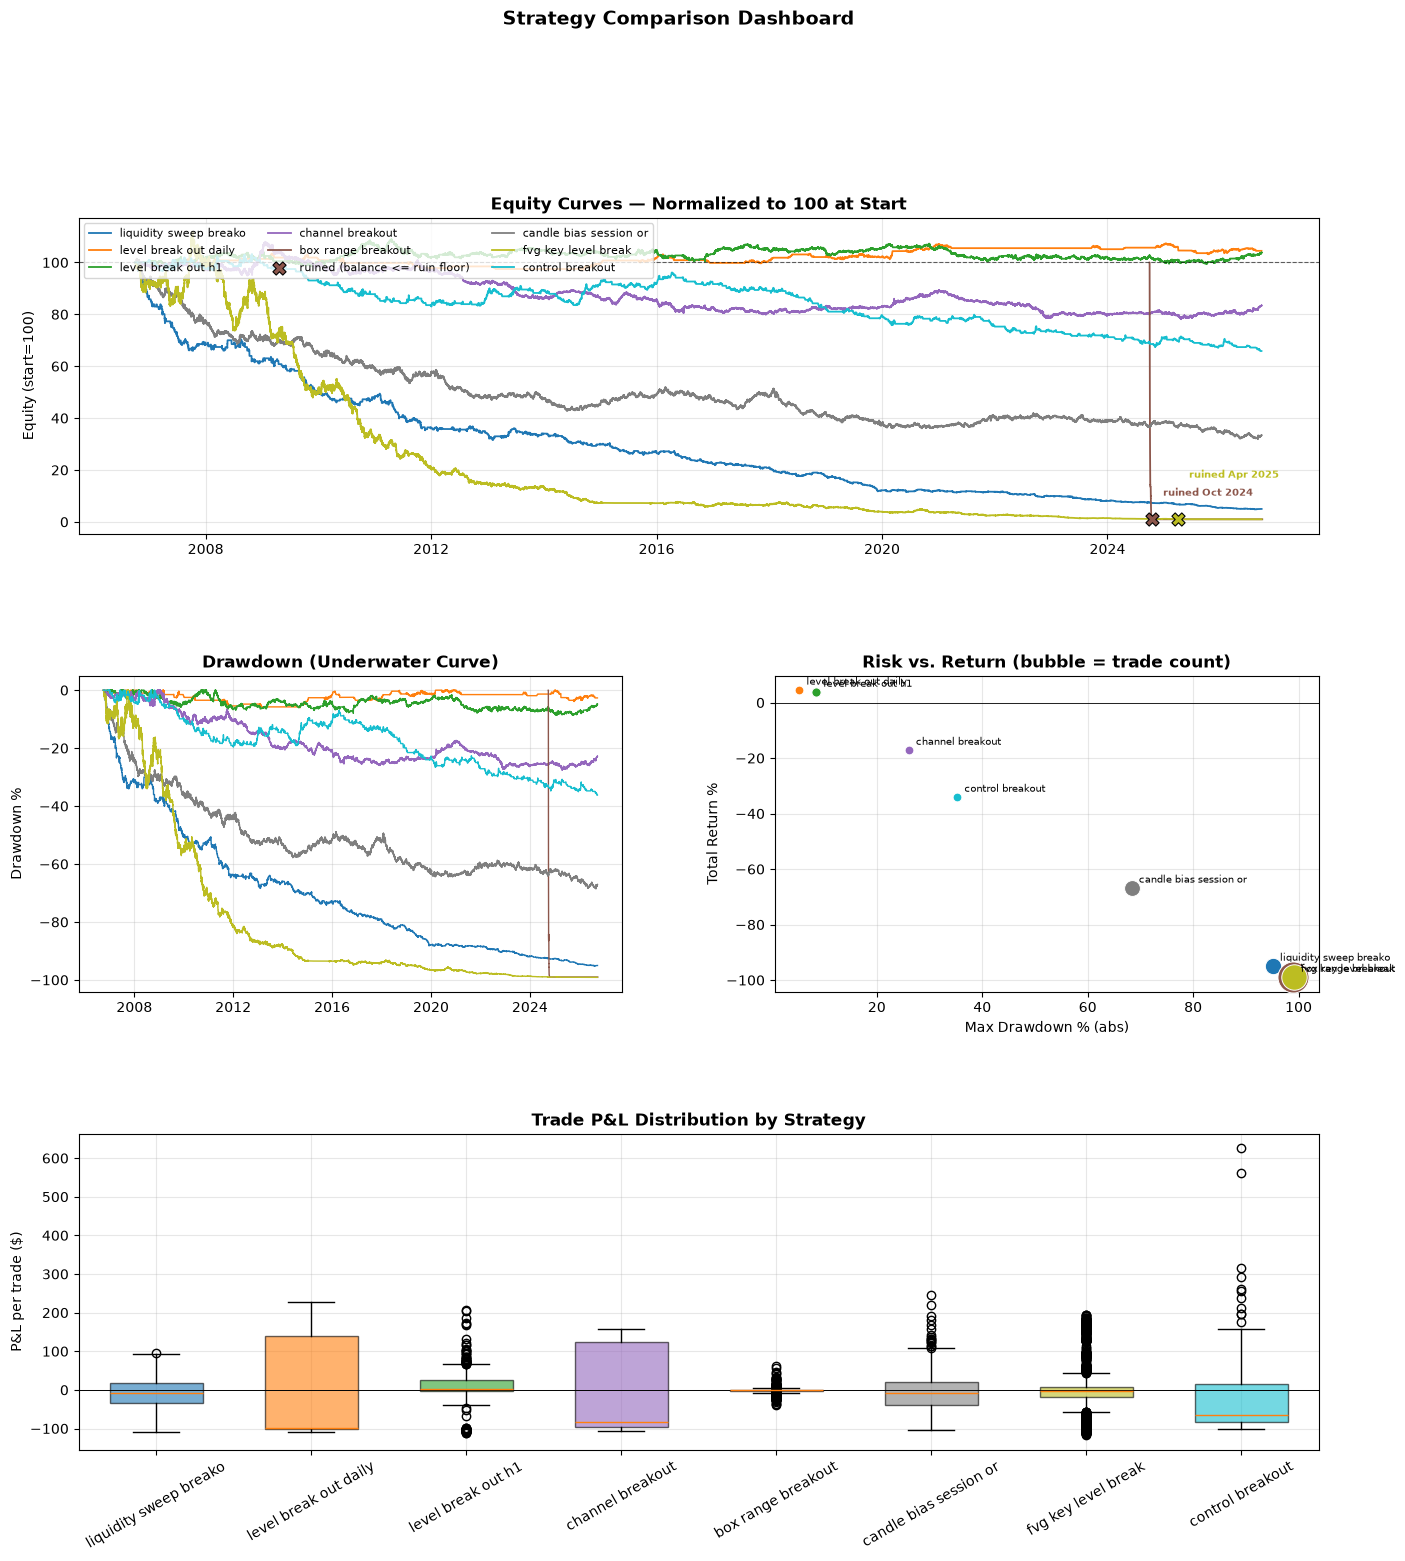

Ranked by return/drawdown (Calmar-like) -- not by raw return:


,strategy,n_trades,win_rate,profit_factor,total_return_pct,max_drawdown_pct,calmar_like
1,2_level_break_out_daily,36,0.472222,1.229328,4.473318,-5.327849,0.839610
2,3_level_break_out_h1,394,0.619289,1.051591,3.705450,-8.536709,0.434061
3,4_channel_breakout,128,0.343750,0.775488,-17.209720,-26.087925,-0.659681
7,8_control_breakout,193,0.269430,0.644136,-34.139246,-35.287208,-0.967468
5,6_candle_bias_session_orb,1176,0.424320,0.719845,-66.881796,-68.382813,-0.978050
0,1_liquidity_sweep_breakout,1251,0.407674,0.606020,-95.014558,-95.141244,-0.998668
6,7_fvg_key_level_break,3028,0.316711,0.813932,-99.009200,-99.109225,-0.998991
4,5_box_range_breakout,4513,0.022380,0.092184,-99.000433,-98.999715,-1.000007


In [26]:
def plot_strategy_comparison(all_strategy_results: dict, comparison_df: pd.DataFrame) -> pd.DataFrame:
    """
    Five-panel comparison dashboard built entirely from what run_all_strategies (9a)
    already computed -- no new backtests are run here. Returns the comparison table
    re-sorted by a Calmar-like ratio instead of raw return.
    """
    names = [n for n in all_strategy_results if not all_strategy_results[n]["trades"].empty]
    if not names:
        print("No completed trades to compare yet -- run Section 9a first.")
        return comparison_df

    cmap = plt.cm.tab10(np.linspace(0, 1, max(len(names), 1)))
    color = dict(zip(names, cmap))
    short = lambda n: n.split("_", 1)[-1].replace("_", " ")[:22]

    fig = plt.figure(figsize=(16, 16))
    gs = fig.add_gridspec(3, 2, hspace=0.45, wspace=0.28)

    # 1. Normalized equity curves, overlaid
    ax1 = fig.add_subplot(gs[0, :])
    _ruin_in_legend, _n_ruined = False, 0
    for n in names:
        eq = all_strategy_results[n]["equity_curve"]
        norm = eq["equity"] / eq["equity"].iloc[0] * 100
        ax1.plot(eq["date"], norm, label=short(n), color=color[n], linewidth=1.3)
        # Ruin marker: the engine records when balance hit the ruin floor (Section 9) in equity_curve.attrs
        ruined_at = eq.attrs.get("ruined_at")
        if ruined_at is not None:
            j = min(int(eq["date"].searchsorted(ruined_at)), len(eq) - 1)
            ax1.scatter([eq["date"].iloc[j]], [norm.iloc[j]], marker="X", s=90, color=color[n],
                        edgecolor="black", linewidth=0.8, zorder=5,
                        label=None if _ruin_in_legend else "ruined (balance <= ruin floor)")
            _ruin_in_legend = True
            _n_ruined += 1                     # stagger labels so neighbouring ruins stay readable
            ax1.annotate(f"ruined {ruined_at:%b %Y}", (eq["date"].iloc[j], norm.iloc[j]), fontsize=7.5,
                         xytext=(8, 4 + 13 * _n_ruined), textcoords="offset points", color=color[n], fontweight="bold")
    ax1.axhline(100, color="black", linewidth=0.8, linestyle="--", alpha=0.6)
    ax1.set_title("Equity Curves \u2014 Normalized to 100 at Start", fontweight="bold")
    ax1.legend(fontsize=8, ncol=3, loc="upper left")
    ax1.set_ylabel("Equity (start=100)")

    # 2. Drawdown overlay, same color key
    ax2 = fig.add_subplot(gs[1, 0])
    for n in names:
        eq = all_strategy_results[n]["equity_curve"]
        running_max = eq["equity"].cummax()
        dd = (eq["equity"] - running_max) / running_max * 100
        ax2.plot(eq["date"], dd, color=color[n], linewidth=1.0)
    ax2.set_title("Drawdown (Underwater Curve)", fontweight="bold")
    ax2.set_ylabel("Drawdown %")

    # 3. Risk/return scatter, bubble size = trade count
    ax3 = fig.add_subplot(gs[1, 1])
    plot_df = comparison_df.replace([np.inf, -np.inf], np.nan).dropna(
        subset=["total_return_pct", "max_drawdown_pct"])
    max_n = plot_df["n_trades"].max() or 1
    for _, row in plot_df.iterrows():
        ax3.scatter(abs(row["max_drawdown_pct"]), row["total_return_pct"],
                    s=max(row["n_trades"] / max_n * 500, 40),
                    color=color.get(row["strategy"], "gray"), edgecolor="white",
                    linewidth=0.7, zorder=3)
        ax3.annotate(short(row["strategy"]), (abs(row["max_drawdown_pct"]), row["total_return_pct"]),
                     fontsize=7.5, xytext=(5, 4), textcoords="offset points")
    ax3.axhline(0, color="black", linewidth=0.6)
    ax3.set_xlabel("Max Drawdown % (abs)")
    ax3.set_ylabel("Total Return %")
    ax3.set_title("Risk vs. Return (bubble = trade count)", fontweight="bold")

    # 4. Trade P&L distribution per strategy
    ax4 = fig.add_subplot(gs[2, :])
    box_data = [all_strategy_results[n]["trades"]["pnl"].values for n in names]
    # matplotlib >=3.9 renamed the boxplot 'labels' kwarg to 'tick_labels' (and later
    # versions drop 'labels' entirely), so pick whichever this environment supports.
    import matplotlib as _mpl
    _boxplot_label_kw = 'tick_labels' if tuple(map(int, _mpl.__version__.split('.')[:2])) >= (3, 9) else 'labels'
    bp = ax4.boxplot(box_data, patch_artist=True, showfliers=True, widths=0.6,
                      **{_boxplot_label_kw: [short(n) for n in names]})
    for patch, n in zip(bp["boxes"], names):
        patch.set_facecolor(color[n]); patch.set_alpha(0.6)
    ax4.axhline(0, color="black", linewidth=0.7)
    ax4.set_title("Trade P&L Distribution by Strategy", fontweight="bold")
    ax4.set_ylabel("P&L per trade ($)")
    ax4.tick_params(axis="x", rotation=30)

    plt.suptitle("Strategy Comparison Dashboard", fontsize=14, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()

    # 5. Calmar-like ranking -- printed as a table, not a bar chart: this ratio can be
    # +/-inf for a zero-drawdown strategy, and a bar chart handles that far worse than
    # a sorted table does.
    ranked = comparison_df.copy()
    ranked["calmar_like"] = ranked["total_return_pct"] / ranked["max_drawdown_pct"].abs().replace(0, np.nan)
    ranked = ranked.sort_values("calmar_like", ascending=False)
    print("Ranked by return/drawdown (Calmar-like) -- not by raw return:")
    display(ranked[["strategy", "n_trades", "win_rate", "profit_factor",
                     "total_return_pct", "max_drawdown_pct", "calmar_like"]])
    return ranked


strategy_ranking = plot_strategy_comparison(all_strategy_results, all_strategies_comparison)


---
### 9c. Diagnosis — What the 7 Actually Have in Common

Seven different videos, seven different names for it — but pull the risk logic and
parameter selection out of each one and the same six failures show up over and over.
This isn't a vibe, it's what's actually in `STRATEGY_1_PARAMS` through `STRATEGY_7_PARAMS`
above:

1. **Stop-loss methodology is inconsistent AND mostly not volatility-adaptive.**
   Strategies 2, 3, and 4 all use a flat `sl_pct = 0.03` — 3% of price, regardless of
   what the market is actually doing that day. Strategy 6 has **no stop-loss or take-profit
   at all** in the original — risk is bounded only by a pending stop order that expires after `exit_delay_days` (4 days) and a forced close at the end of day D+4, and the
   ATR-based placeholder in this notebook exists purely so the shared engine has something
   to size a position with. Only Strategy 1 genuinely scales its stop with current
   volatility (ATR). A stop that doesn't move with volatility is a stop that's too tight
   in calm markets and too loose in violent ones — on both counts, wrong.

2. **6 of 7 have no genuine trend or regime filter.** Only Strategy 1 checks anything about
   the broader market condition (EMA(150) trend, confirmed over 15 bars) before firing.
   (Strategy 6's prior-day candle colour sets a direction, but it doesn't test whether the market is trending.)
   The other six will happily take a breakout signal in a dead-flat range or directly into
   a violent reversal — a structural blind spot for anything called a "breakout" strategy,
   whose entire premise depends on genuine momentum continuing.

3. **Every one was hand-tuned on a single pair, then never touched again.** Pivot windows,
   lookback periods, R² thresholds, box sizes — all of it was picked once against EURUSD (or,
   for Strategy 2/3, one specific timeframe) and none of the source videos re-validate those
   numbers out-of-sample or on a second instrument. That's precisely the walk-forward and
   multi-pair testing this notebook's Sections 12–14 exist to do — because the sources didn't.

4. **At least one strategy's risk logic isn't even from its own source.** Strategy 3's
   detection is genuinely its creator's own (different pivot/backcandles numbers from
   Strategy 2) — but its SL/TP is borrowed wholesale from Strategy 2 because the H1 source
   video never showed a backtest at all. A third of this strategy's mechanics are a
   transplant, not a reproduction.

5. **At least one strategy has a timeframe trap.** Strategy 5's source ran
   `box_size=5` on 1-*minute* bars — a 5-minute opening range. On an H1 default, the identical
   parameter produces a 5-*hour* box: a materially different strategy wearing the same code.
   This notebook avoids it by running Strategy 5 on its source's own data — 2 years of M1
   (Section 6) — rather than forcing it onto the shared H1 default.

6. **At least one strategy's edge was reverse-engineered from the test set.** Strategy 7's
   `tp_sl_ratio = 1.8` isn't a design choice — it's the winner of a 1.0–2.2 grid search the
   creator ran on the exact data being evaluated, producing a 31% return riding a -73% max
   drawdown. The creator says as much on camera. That's not a strategy with an edge, that's
   in-sample optimization bias, disclosed by the person who did it.

None of this is "breakout doesn't work." It's seven specific decisions — a stop that ignores
volatility, a signal with no regime awareness, parameters fit once and never re-tested,
in at least one case a stop borrowed from someone else's video, in at least one case a
timeframe that silently changed, in at least one case a parameter that was curve-fit on
camera — compounding into strategies that mostly don't survive contact with real costs. (Strategies 2 and 3 end near breakeven, but on a few dozen to a few hundred trades with stops hundreds of pips wide, and their small gains depend on the borrowed RSI hook — with it off, Strategy 2 is roughly flat and Strategy 3 loses (9a-iii) — see 9a-ii, 9a-iii and the `thin_sample` flag — so they are not counter-examples.)
Strategy 8, defined back in Section 6, was built deliberately without those six decisions —
and, per the Section 15 receipts, it lost money anyway — a claim that is only valid if that section's CONCLUSION CHECK passes on the frozen run. Removing the
six known bugs was necessary, but on its own it wasn't enough.

In [27]:
diagnosis = pd.DataFrame([
    {"Strategy": "1. Liquidity Sweep Breakout", "Stop Method": "ATR (volatility-adaptive)",
     "R:R": "1:1", "Trend/Regime Filter": "EMA(150), 15-bar confirm", "Flaw": "Only ATR-adaptive stop of the seven — and still loses (win rate below its 50% break-even)"},
    {"Strategy": "2. Level Break Out (Daily)", "Stop Method": "Flat 3% of price",
     "R:R": "1:2", "Trend/Regime Filter": "None", "Flaw": "Stop ignores volatility"},
    {"Strategy": "3. Level Break Out (H1)", "Stop Method": "Borrowed from Strategy 2",
     "R:R": "1:2", "Trend/Regime Filter": "None", "Flaw": "SL/TP never shown by its own source"},
    {"Strategy": "4. Channel Breakout", "Stop Method": "Flat 3% of price",
     "R:R": "1:1.5", "Trend/Regime Filter": "None", "Flaw": "Stop ignores volatility"},
    {"Strategy": "5. Box Range Breakout", "Stop Method": "Signal candle's own range",
     "R:R": "1:2", "Trend/Regime Filter": "None", "Flaw": "Timeframe trap: 5-min box (M1) becomes 5-hour on an H1 default (run on M1 here)"},
    {"Strategy": "6. Candle-Bias Session ORB", "Stop Method": "None in original (placeholder added)",
     "R:R": "Undefined", "Trend/Regime Filter": "Prior-day candle color only", "Flaw": "No SL/TP in source; risk bounded only by a multi-day pending-order expiry"},
    {"Strategy": "7. FVG + Key Level Break", "Stop Method": "Prior candle's range",
     "R:R": "1:1.8 (grid-search optimized)", "Trend/Regime Filter": "None",
     "Flaw": "R:R curve-fit on the test data itself"},
])
diagnosis

,Strategy,Stop Method,R:R,Trend/Regime Filter,Flaw
0,1. Liquidity Sweep Breakout,ATR (volatility-adaptive),1:1,"EMA(150), 15-bar confirm",Only ATR-adaptive stop of the seven — and stil...
1,2. Level Break Out (Daily),Flat 3% of price,1:2,None,Stop ignores volatility
2,3. Level Break Out (H1),Borrowed from Strategy 2,1:2,None,SL/TP never shown by its own source
3,4. Channel Breakout,Flat 3% of price,1:1.5,None,Stop ignores volatility
4,5. Box Range Breakout,Signal candle's own range,1:2,None,Timeframe trap: 5-min box (M1) becomes 5-hour ...
5,6. Candle-Bias Session ORB,None in original (placeholder added),Undefined,Prior-day candle color only,No SL/TP in source; risk bounded only by a mul...
6,7. FVG + Key Level Break,Prior candle's range,1:1.8 (grid-search optimized),None,R:R curve-fit on the test data itself


---
### 9d. Run the active strategy — single-strategy deep dive

Set `ACTIVE_VARIANT` to any of the 8 case-study strategies defined in Section 6 and
re-run this cell (and the one below) to regenerate `dfs` and the portfolio backtest for
it. Sections 10 onward (Results & Metrics, Visualizations, Robustness, Cost Sensitivity)
all analyze THIS variant's `equity_curve`/`trades` specifically — 9a/9b above already gave
you the across-all-strategies comparison; this is where you pick one to dig into further.

Note: this cell overwrites `dfs[sym]` with the active variant's signal frames. Anything that needs the untouched default-timeframe frames must use `dfs_base`.


In [28]:
ACTIVE_VARIANT = "8_control_breakout"   # <-- change this to switch which strategy runs

_active_params = _STRATEGY_PARAMS_BY_NAME.get(ACTIVE_VARIANT, STRATEGY_1_PARAMS)
_active_granularity = _active_params.get("granularity", CONFIG["granularity"])
_active_days = _active_params.get("days", CONFIG["days"])   # per-strategy window (Strategy 5: 730d of M1)

PROFILE = {**STRATEGY_PROFILES[ACTIVE_PROFILE],
           **{k: _active_params[k] for k in _OVERRIDE_KEYS if k in _active_params}}

if _active_granularity == CONFIG["granularity"] and _active_days == CONFIG["days"]:
    active_dfs = dfs
else:
    active_dfs = {}
    for sym in CONFIG["symbols"]:
        raw = fetch_oanda_candles(sym, _active_granularity, _active_days,
                                   price=CONFIG["price_component"], force_refresh=False)
        raw_h1 = fetch_oanda_candles(sym, "H1", _active_days,
                                      price=CONFIG["price_component"], force_refresh=False)
        raw = add_indicators(raw, sym)
        raw["is_closed"] = compute_is_closed(raw)
        raw = merge_h1_bias(raw, raw_h1)
        raw = add_vol_regime(raw)
        active_dfs[sym] = raw

# Generate signals for every symbol in the profile, using the active variant
variant_fn = STRATEGY_VARIANTS[ACTIVE_VARIANT]
for sym in CONFIG["symbols"]:
    dfs[sym] = variant_fn(active_dfs[sym], sym, PROFILE)
    n_sig = (dfs[sym]["signal"] != 0).sum()
    print(f"[{ACTIVE_VARIANT}] {sym} Signals: {n_sig} ({(dfs[sym]['signal']==1).sum()} buy, "
          f"{(dfs[sym]['signal']==2).sum()} sell) of {len(dfs[sym])} bars ({n_sig/len(dfs[sym])*100:.3f}%)")

  📂 Loaded 5712 cached bars for EURUSD D from data_cache\EURUSD_D_M.csv
  📂 Loaded 126528 cached bars for EURUSD H1 from data_cache\EURUSD_H1_M.csv
  📂 Loaded 5710 cached bars for GBPUSD D from data_cache\GBPUSD_D_M.csv
  📂 Loaded 126421 cached bars for GBPUSD H1 from data_cache\GBPUSD_H1_M.csv
  📂 Loaded 5728 cached bars for USDJPY D from data_cache\USDJPY_D_M.csv
  📂 Loaded 126475 cached bars for USDJPY H1 from data_cache\USDJPY_H1_M.csv
  📂 Loaded 5712 cached bars for USDCHF D from data_cache\USDCHF_D_M.csv
  📂 Loaded 126405 cached bars for USDCHF H1 from data_cache\USDCHF_H1_M.csv
  📂 Loaded 5681 cached bars for AUDUSD D from data_cache\AUDUSD_D_M.csv
  📂 Loaded 126447 cached bars for AUDUSD H1 from data_cache\AUDUSD_H1_M.csv
  📂 Loaded 5698 cached bars for USDCAD D from data_cache\USDCAD_D_M.csv
  📂 Loaded 126341 cached bars for USDCAD H1 from data_cache\USDCAD_H1_M.csv
  📂 Loaded 5683 cached bars for NZDUSD D from data_cache\NZDUSD_D_M.csv
  📂 Loaded 126349 cached bars for NZDUSD

In [29]:
equity_curve, trades = run_portfolio_backtest(dfs, CONFIG, PROFILE, EXECUTION_MODE, SIZING_MODE)
print(f"Portfolio Backtest complete: {len(trades)} trades, final equity ${equity_curve['equity'].iloc[-1]:,.2f}")

Backtest (EURUSD+GBPUSD+USDJPY+USDCHF+AUDUSD+USDCAD+NZDUSD):   0%|          | 0/5822 [00:00<?, ?it/s]

Portfolio Backtest complete: 193 trades, final equity $6,586.08


In [30]:
# Sensitivity: where does a next-bar fill reference from? "mid" = (high+low)/2 of the entry bar (class parity),
# "open" = the bar's open (the only price actually knowable when the order is placed). On Daily bars they differ a lot.
_rows = []
for _basis in ("mid", "open"):
    _eq, _tr = run_portfolio_backtest(dfs, CONFIG, {**PROFILE, "entry_price_basis": _basis}, EXECUTION_MODE, SIZING_MODE, show_progress=False)
    if _tr.empty: continue
    _w, _l = _tr.loc[_tr["pnl"] > 0, "pnl"].sum(), abs(_tr.loc[_tr["pnl"] <= 0, "pnl"].sum())
    _rows.append({"entry_basis": _basis, "trades": len(_tr), "win_rate": (_tr["pnl"] > 0).mean(), "profit_factor": _w / _l if _l else np.inf,
                  "return_pct": (_eq["equity"].iloc[-1] / CONFIG["initial_capital"] - 1) * 100})
entry_basis_sensitivity = pd.DataFrame(_rows).set_index("entry_basis")
display(entry_basis_sensitivity.round(3))
print("If 'mid' and 'open' disagree materially, report the 'open' row -- it does not use the entry bar's own range.")

,trades,win_rate,profit_factor,return_pct
entry_basis,,,,
mid,193,0.269,0.644,-34.139
open,199,0.291,0.672,-33.594


If 'mid' and 'open' disagree materially, report the 'open' row -- it does not use the entry bar's own range.


### 9e. Receipt — what the timeframe mistake looked like

Strategy 8's first version ran Donchian-55 on **H1** bars — a daily-bar number on hourly data. This cell re-creates that mistake on
purpose (same exits, H1 granularity) so the video's "same code, wrong timeframe" beat has a live receipt instead of a remembered number.

In [31]:
_h1_profile = {**PROFILE, "exit_mode": "atr_trail", "atr_trail_multiplier": 2.5}
h1_mistake = run_all_strategies(dfs, CONFIG, _h1_profile, EXECUTION_MODE, SIZING_MODE, only=["8_control_breakout"],
                                force_default_granularity=True, results_store={})
display(h1_mistake.round(3))

☠️  RUIN: balance fell to <= $100.00 (1.0% of $10,000) on 2026-07-08 06:00 after 3,971 trades -- no further entries were taken.
  done: 8_control_breakout @ H1 (7300d) -- 3971 trades, -99.00%


C:\Users\user\AppData\Local\Temp\ipykernel_10760\3101446423.py:4: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(h1_mistake.round(3))


,strategy,granularity,days,ruined_at,n_trades,win_rate,profit_factor,total_return_pct,max_drawdown_pct
0,8_control_breakout,H1,7300,2026-07-08 06:00:00+00:00,3971,0.31,0.831,-99.003,-99.055


---
## 10. Results & Metrics 🔒

Things worth knowing about the numbers below (they analyse whichever strategy `ACTIVE_VARIANT` selects):
- **Max Drawdown is computed from the closed-trade equity curve**, not the mark-to-market curve. Since `trades.pnl` is now net of commission, this matches the 9a table's drawdown.
- **Net P&L** here is final mark-to-market equity minus initial capital; it equals the sum of trade P&L unless a position is still open on the last bar.
- **Risk of Ruin (analytic)** is only defined for a positive edge. For zero/negative expectancy it prints `n/a` — the finite-sample answer is the resampling Monte Carlo in Section 12. (It used to print a hard-coded 95%, which was a placeholder, not an estimate.)
- **Volatility-regime win rates** use the timeframe-normalised regime from Section 7. A filter like Strategy 8's ADX ≥ 25 correlates with, but is not identical to, that separate log-return classifier.
- **Buy & Hold** is shown for the first symbol only and is *not* a meaningful FX benchmark: its sign is set by the quote convention (long USDJPY vs long EURUSD are opposite dollar bets).

In [32]:
# risk_of_ruin() lives in Section 8 (Position Sizing & Risk)

def compute_metrics_and_log(trades, equity_curve, df_master, config, profile):
    """
    Computes the full metrics set and prints the report— Compact Trade
    Summary, Backtest Results Summary, Volatility Regime Win Rates, and Strategy
    Performance Breakdown. Also renders a compact scorecard first, for
    reading at a glance before the full report.

    `df_master` is used only as the Buy & Hold benchmark (first vs. last close) —
    pass whichever symbol's frame is most representative of the portfolio; it has
    no other effect on the metrics.

    Returns the metrics dict (also used by Section 15's export).
    """
    if trades.empty:
        print("🔸 No trades executed in this backtest.")
        return {}
        
    ic = config["initial_capital"]
    final = equity_curve["equity"].iloc[-1]
    
    # --- Basic Metrics ---
    total_return = (final - ic) / ic if ic > 0 else 0.0
    
    bars_per_day_map = {
        'M1': 1440, 'M2': 720, 'M3': 480, 'M5': 288, 'M10': 144, 'M15': 96, 'M20': 72, 'M30': 48,
        'H1': 24, 'H2': 12, 'H4': 6, 'H8': 3, 'D': 1
    }
    bars_per_day = bars_per_day_map.get(config["granularity"], 96)
    # config["granularity"] is the notebook default (H1); the ACTIVE_VARIANT may run on another timeframe
    # (Daily, H2, M1...), so derive bars/day from the equity curve's own bar spacing instead.
    _step_min = equity_curve["date"].diff().dt.total_seconds().median() / 60.0
    if _step_min and _step_min > 0:
        bars_per_day = 1440.0 / _step_min
    num_bars = len(equity_curve)
    
    # annualised return (and Calmar).
    span_days = max(1.0, (equity_curve["date"].iloc[-1] - equity_curve["date"].iloc[0]).total_seconds() / 86400.0)
    years = span_days / 365.25
    
    if years >= 0.25 and ic > 0:
        try: annualized_return = (final / ic) ** (1.0 / years) - 1.0
        except: annualized_return = total_return
    else:
        annualized_return = total_return
        
    wins = trades[trades['pnl'] > 0]
    losses = trades[trades['pnl'] <= 0]
    win_rate = len(wins) / len(trades)
    
    gross_profit = wins['pnl'].sum()
    gross_loss = abs(losses['pnl'].sum())
    profit_factor = (gross_profit / gross_loss) if gross_loss > 0 else float('inf')
    
    avg_win = (gross_profit / len(wins)) if len(wins) else 0.0
    avg_loss = (gross_loss / len(losses)) if len(losses) else 0.0
    expectancy = (win_rate * avg_win) - ((1.0 - win_rate) * avg_loss)
    largest_win = wins['pnl'].max() if len(wins) else 0.0
    largest_loss = losses['pnl'].min() if len(losses) else 0.0   # most negative trade
    
    # Payoff ratio = avg win / avg loss; breakeven win rate = 1 / (1 + payoff) = the win rate at which expectancy is exactly 0
    payoff_ratio = (avg_win / avg_loss) if avg_loss > 0 else float('inf')
    breakeven_win_rate = (1.0 / (1.0 + payoff_ratio)) if np.isfinite(payoff_ratio) else 0.0
    
    # Expectancy in R = mean(pnl / risk_amount) -- same definition as Section 12's expectancy_ci
    _r = (trades['pnl'] / trades['risk_amount']).replace([np.inf, -np.inf], np.nan).dropna()
    expectancy_r = float(_r.mean()) if len(_r) else float('nan')
    
    # Max drawdown from the CLOSED-trade equity curve 
    closed_equity = [ic]
    for pnl in trades['pnl']:
        closed_equity.append(closed_equity[-1] + pnl)
        
    max_eq = closed_equity[0]
    max_drawdown = 0.0
    for eq in closed_equity:
        if eq > max_eq: max_eq = eq
        if max_eq > 0:
            dd = (max_eq - eq) / max_eq
            if dd > max_drawdown: max_drawdown = dd
            
    max_drawdown = max(0.0, min(1.0, max_drawdown)) if np.isfinite(max_drawdown) else 0.0
    
    # Sharpe & Sortino from WEEKDAY daily returns, net of a 2%/yr risk-free rate, annualised with
    # sqrt(252). BUGFIX: flat days (no open position) used to be dropped, which inflates both ratios
    # by roughly 1/sqrt(fraction of days in the market) -- e.g. 1.9 instead of 0.2 when only ~9% of
    # days move. Sortino now uses the standard downside deviation (RMS of shortfalls over ALL days)
    # instead of the std of just the negative days.
    daily_equity = equity_curve.set_index("date")["equity"].resample("D").last().ffill()
    daily_equity = daily_equity[daily_equity.index.dayofweek < 5]
    daily_returns = daily_equity.pct_change().dropna()

    sharpe_ratio = 0.0
    sortino_ratio = 0.0
    if len(daily_returns) > 1:
        rf_daily = 0.02 / 252.0
        excess = daily_returns.values - rf_daily
        mu = np.mean(excess)
        sigma = np.std(excess)
        if sigma > 0:
            sharpe_ratio = float(np.sqrt(252) * (mu / sigma))
        downside_deviation = float(np.sqrt(np.mean(np.minimum(excess, 0.0) ** 2)))
        if downside_deviation > 0:
            sortino_ratio = float(np.sqrt(252) * (mu / downside_deviation))
        elif mu > 0:
            sortino_ratio = float('inf')

    # Calmar
    if max_drawdown > 0:
        calmar_ratio = annualized_return / max_drawdown
        if annualized_return < 0 and calmar_ratio < 0: calmar_ratio = -abs(calmar_ratio)
    else:
        calmar_ratio = float('inf') if annualized_return >= 0 else float('-inf')
        
    # Volatility-regime win rates, from the vol_regime the engine recorded at signal time.
    # BUGFIX: this used to relabel the ADX-based market_regime (trending/volatile/ranging) as
    # high/extreme/normal, so "Low Volatility" could never contain a trade and always printed 0.00%.
    regime_win_rates = {}
    regime_pnls = {}
    for _, t in trades.iterrows():
        regime_pnls.setdefault(str(t.get('vol_regime', 'unknown')).lower(), []).append(t['pnl'])
    for regime, pnls in regime_pnls.items():
        regime_win_rates[regime] = sum(1 for p in pnls if p > 0) / len(pnls)

    ror = risk_of_ruin(win_rate, expectancy, len(trades), ic, profile["risk_percent"])
    net_profit = final - ic
    
    # 92, not 96, bars/day for M15 — accounts for the ~1hr daily FX rollover break
    real_bars_per_day = 92 if config["granularity"] == "M15" else bars_per_day
    trading_days = num_bars / real_bars_per_day
    bars_label = "trading days" if bars_per_day <= 1.5 else "bars"
    
    # Benchmark (first symbol of the portfolio as proxy)
    bnh = (df_master["close"].iloc[-1] - df_master["close"].iloc[0]) / df_master["close"].iloc[0]
    
    metrics = {
        'total_return': total_return, 'annualized_return': annualized_return,
        'win_rate': win_rate, 'profit_factor': profit_factor, 'expectancy': expectancy,
        'max_drawdown': max_drawdown, 'sharpe_ratio': sharpe_ratio, 'sortino_ratio': sortino_ratio,
        'calmar_ratio': calmar_ratio, 'trade_count': len(trades),
        'regime_win_rates': regime_win_rates, 'risk_of_ruin': ror,
        'gross_profit': gross_profit, 'gross_loss': gross_loss, 'final_capital': final,
        'largest_win': largest_win, 'largest_loss': largest_loss, 'expectancy_r': expectancy_r,
        'payoff_ratio': payoff_ratio, 'breakeven_win_rate': breakeven_win_rate,
        'initial_capital': ic, 'buy_and_hold': bnh
    }
    
    
    verdict_emoji = "🟢" if net_profit > 0 else "🔴"
    verdict_label = "PROFITABLE" if net_profit > 0 else "UNPROFITABLE"
    print(f"{verdict_emoji}  {verdict_label}")
    print("-" * 40)
    for label, value in [
        ("Net P&L", f"${net_profit:,.2f}"),
        ("Win Rate", f"{win_rate:.1%}"),
        ("Profit Factor", f"{profit_factor:.2f}"),
        ("Max Drawdown", f"{max_drawdown:.1%}"),
        ("Sharpe / Sortino", f"{sharpe_ratio:.2f} / {sortino_ratio:.2f}"),
        ("Risk of Ruin (analytic)", f"{ror:.1%}" if np.isfinite(ror) else "n/a (edge <= 0)"),
        ("Total Trades", f"{len(trades)}"),
    ]:
        print(f"  {label:<20}{value:>18}")
    print("-" * 40)
    print()

    # 1. Compact Trade Summary
    summary_table = pd.DataFrame({
        "🔷 Count": [len(wins), len(losses), len(trades)],
        "🔷 Avg PnL": [wins['pnl'].mean() if not wins.empty else 0,
                      losses['pnl'].mean() if not losses.empty else 0,
                      trades['pnl'].mean()],
        "🔷 Total PnL": [wins['pnl'].sum(), losses['pnl'].sum(), trades['pnl'].sum()]
    }, index=[" 🔶 Wins", " 🔶 Losses", " 🔶 All Trades"])
    
    print("〰️" * 25)
    print("❇️ Backtest Compact Trade Summary ")
    print("〰️" * 25)
    print(summary_table.to_string(float_format=lambda x: f"{x:,.2f}"))
    
    # 2. Main Summary
    print("〰️" * 25)
    print("❇️ BACKTEST RESULTS SUMMARY")
    print("〰️" * 25)
    print(f"🔶 Period: {num_bars} bars over {years:.1f} calendar years")
    print(f"🔶 Initial Capital: ${ic:,.2f}")
    print(f"🔶 Final Capital: ${final:,.2f}")
    print(f"🔶 Gross Profit: ${gross_profit:,.2f}")
    print(f"🔶 Gross Loss: -${gross_loss:,.2f}")
    print(f"🔶 Largest Win: ${largest_win:,.2f}")
    print(f"🔶 Largest Loss: -${abs(largest_loss):,.2f}")
    print(f"🔶 Net Profit/Loss: ${net_profit:,.2f}")
    print(f"🔶 Total Return: {total_return:.2%}")
    print(f"🔶 Annualized Return: {annualized_return:.2%}")
    print(f"🔶 Max Drawdown: {max_drawdown:.2%}")
    print(f"🔶 Win Rate: {win_rate:.2%}")
    print(f"🔶 Breakeven Win Rate: {breakeven_win_rate:.2%}")
    print(f"🔶 Payoff Ratio: {payoff_ratio:.2f}")
    print(f"🔶 Profit Factor: {profit_factor:.2f}")
    print(f"🔶 Sharpe Ratio: {sharpe_ratio:.2f}")
    print(f"🔶 Sortino Ratio: {sortino_ratio:.2f}")
    print(f"🔶 Calmar Ratio: {calmar_ratio:.2f}")
    print(f"🔶 Expectancy: ${expectancy:.2f} per trade")
    print(f"🔶 Expectancy (R): {expectancy_r:+.3f} R per trade")
    print(f"🔶 Total Trades: {len(trades)}")
    print(f"🔶 Risk of Ruin (analytic, positive-edge only): {ror:.2%}" if np.isfinite(ror) else
          "🔶 Risk of Ruin (analytic): n/a -- expectancy <= 0; see Section 12 resampling Monte Carlo")
    
    print("🔶 Reference (NOT a meaningful FX benchmark -- first symbol only, direction set by quote convention):")
    print(f" 🔸 Buy & Hold of {df_master['close'].iloc[0]:.4f} -> {df_master['close'].iloc[-1]:.4f}: {bnh:.2%}")
    
    # 3. Volatility Regime Win Rates
    print("〰️" * 25)
    print("❇️ VOLATILITY REGIME WIN RATES")
    print("〰️" * 25)
    print("🔶 Performance by Volatility Regime:")
    for regime in ['low', 'normal', 'high', 'extreme']:
        n_r = len(regime_pnls.get(regime, []))
        if n_r:
            print(f"  🔸{regime.capitalize()} Volatility: {regime_win_rates[regime]:.2%} win rate ({n_r} trades)")
        else:
            print(f"  🔸{regime.capitalize()} Volatility: n/a (no trades)")
        
    # 4. Strategy Performance Breakdown
    print("〰️" * 25)
    print("❇️ STRATEGY PERFORMANCE BREAKDOWN")
    print("〰️" * 25)
    
    strategy_stats = trades.groupby('strategy_name').agg(
        total_trades=('pnl', 'count'),
        wins=('pnl', lambda x: (x > 0).sum()),
        losses=('pnl', lambda x: (x <= 0).sum())
    ).reset_index()
    strategy_stats['win_rate'] = strategy_stats['wins'] / strategy_stats['total_trades']
    
    for _, row in strategy_stats.iterrows():
        clean_name = row['strategy_name'].replace('Backtest_', '').replace('_', ' ').title()
        print(
            f"🔸 {clean_name:<22} | "
            f"Trades: {int(row['total_trades']):>3} | "
            f"Wins: {int(row['wins']):>3} | "
            f"Losses: {int(row['losses']):>3} | "
            f"Win Rate: {row['win_rate']:.1%}"
        )
        
    return metrics

# The first symbol's frame stands in as the Buy & Hold benchmark
metrics = compute_metrics_and_log(trades, equity_curve, dfs[CONFIG["symbols"][0]], CONFIG, PROFILE)

🔴  UNPROFITABLE
----------------------------------------
  Net P&L                     $-3,413.92
  Win Rate                         26.9%
  Profit Factor                     0.64
  Max Drawdown                     35.3%
  Sharpe / Sortino         -0.80 / -1.10
  Risk of Ruin (analytic)   n/a (edge <= 0)
  Total Trades                       193
----------------------------------------

〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️
❇️ Backtest Compact Trade Summary 
〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️
              🔷 Count  🔷 Avg PnL  🔷 Total PnL
🔶 Wins             52     118.83     6,179.41
🔶 Losses          141     -68.04    -9,593.34
🔶 All Trades      193     -17.69    -3,413.92
〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️
❇️ BACKTEST RESULTS SUMMARY
〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️
🔶 Period: 5822 bars over 20.0 calendar years
🔶 Initial Capital: $10,000.00
🔶 Final Capital: $6,586.08
🔶 Gross Profit: $6,179.41
🔶 Gross Loss: -$9,593.34
🔶 Large

In [33]:
from pathlib import Path

assert ACTIVE_VARIANT == "8_control_breakout", f"ACTIVE_VARIANT is {ACTIVE_VARIANT!r}"

trades[["entry_date", "exit_date", "pnl", "risk_amount", "symbol"]].to_csv("strategy8_trades.csv", index=False)
equity_curve[["date", "equity"]].to_csv("strategy8_equity.csv", index=False)

print(len(trades), round(equity_curve["equity"].iloc[-1], 2))   # expect: 193 and 6586.08
print(Path("strategy8_trades.csv").resolve())
print(Path("strategy8_equity.csv").resolve())

193 6586.08
C:\Users\user\strategy8_trades.csv
C:\Users\user\strategy8_equity.csv


---
## 11. Visualizations 🔒

Equity curve with drawdown underneath, trade P&L distribution alongside a breakdown of trades by exit reason, entries marked directly on the highest-volume symbol's price series, and monthly P&L. All four use one shared color palette (`PALETTE`, defined in the first cell below) so a video's charts read as one consistent visual identity rather than four independent plots.


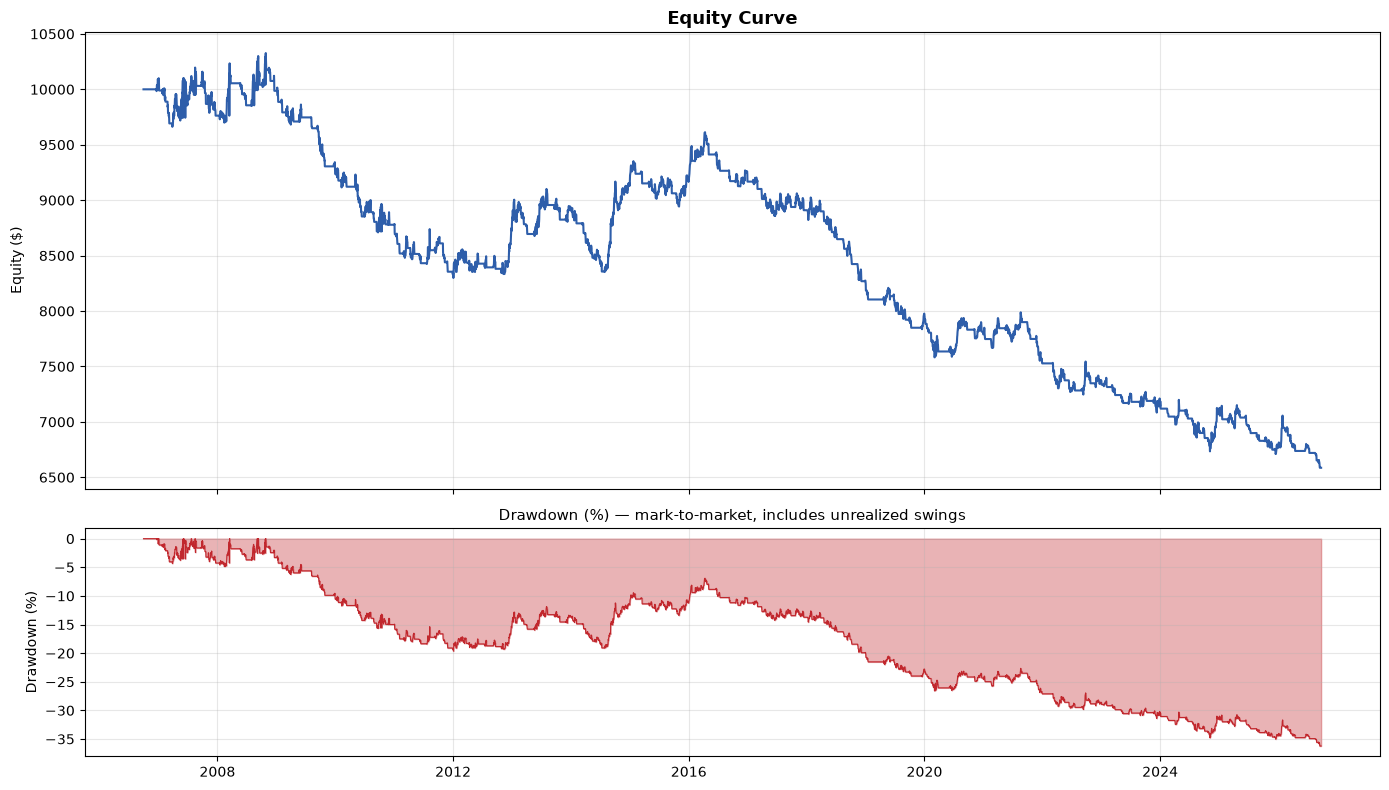

In [34]:
# Shared color identity across every chart in this section — one place to change if
# you want a different look, rather than hunting colors out of six separate cells.
PALETTE = {
    "equity": "#2E5EAA",     # steelblue-ish, brand primary
    "win":    "#2E8B57",     # seagreen
    "loss":   "#C1272D",     # crimson-ish
    "neutral":"#6B6B6B",
}

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={'height_ratios': [2, 1]})

axes[0].plot(equity_curve['date'], equity_curve['equity'], color=PALETTE["equity"], linewidth=1.5)
axes[0].set_title('Equity Curve', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Equity ($)')

dd = (equity_curve['equity'] - equity_curve['equity'].cummax()) / equity_curve['equity'].cummax() * 100
axes[1].fill_between(equity_curve['date'], dd, 0, color=PALETTE["loss"], alpha=0.35)
axes[1].plot(equity_curve['date'], dd, color=PALETTE["loss"], linewidth=0.8)
axes[1].set_title('Drawdown (%) — mark-to-market, includes unrealized swings', fontsize=11)
axes[1].set_ylabel('Drawdown (%)')

plt.tight_layout()
plt.show()

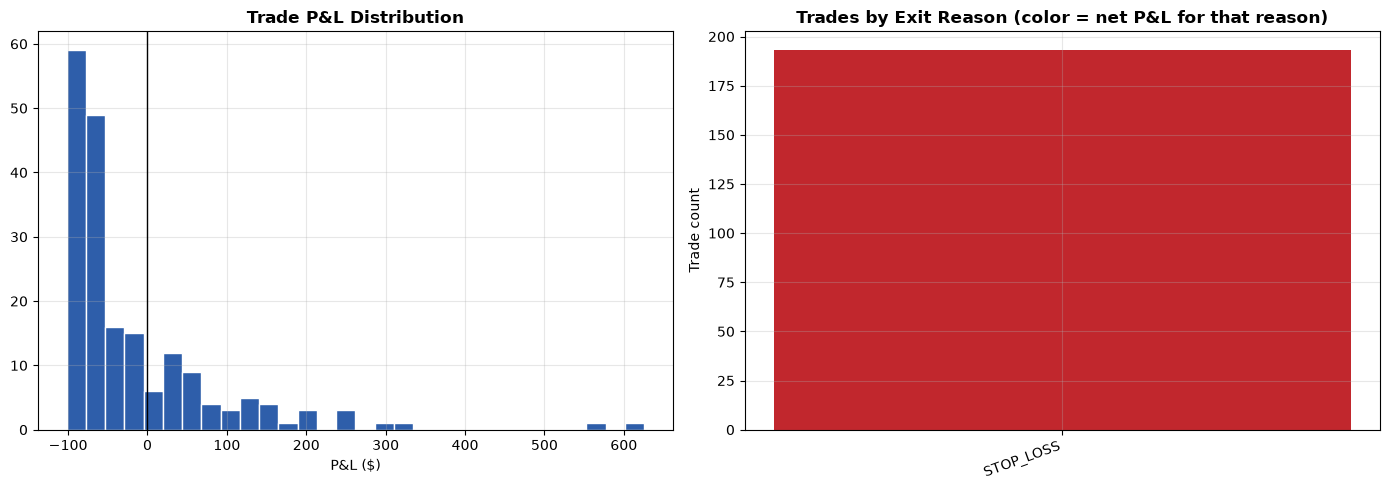

Exit reason breakdown:
             count   win_rate    avg_pnl    total_pnl
exit_reason                                          
STOP_LOSS      193  26.943005 -17.688729 -3413.924624


In [35]:
if not trades.empty:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].hist(trades['pnl'], bins=30, color=PALETTE["equity"], edgecolor='white')
    axes[0].axvline(0, color='black', linewidth=1)
    axes[0].set_title('Trade P&L Distribution', fontweight='bold')
    axes[0].set_xlabel('P&L ($)')

    exit_stats = trades.groupby('exit_reason').agg(
        count=('pnl', 'size'), win_rate=('pnl', lambda x: (x > 0).mean() * 100),
        avg_pnl=('pnl', 'mean'), total_pnl=('pnl', 'sum')
    ).sort_values('count', ascending=False)
    bar_colors = [PALETTE["win"] if v > 0 else PALETTE["loss"] for v in exit_stats['total_pnl']]
    axes[1].bar(exit_stats.index, exit_stats['count'], color=bar_colors)
    axes[1].set_title('Trades by Exit Reason (color = net P&L for that reason)', fontweight='bold')
    axes[1].set_ylabel('Trade count')
    plt.setp(axes[1].get_xticklabels(), rotation=20, ha='right')

    plt.tight_layout()
    plt.show()

    print("Exit reason breakdown:")
    print(exit_stats)

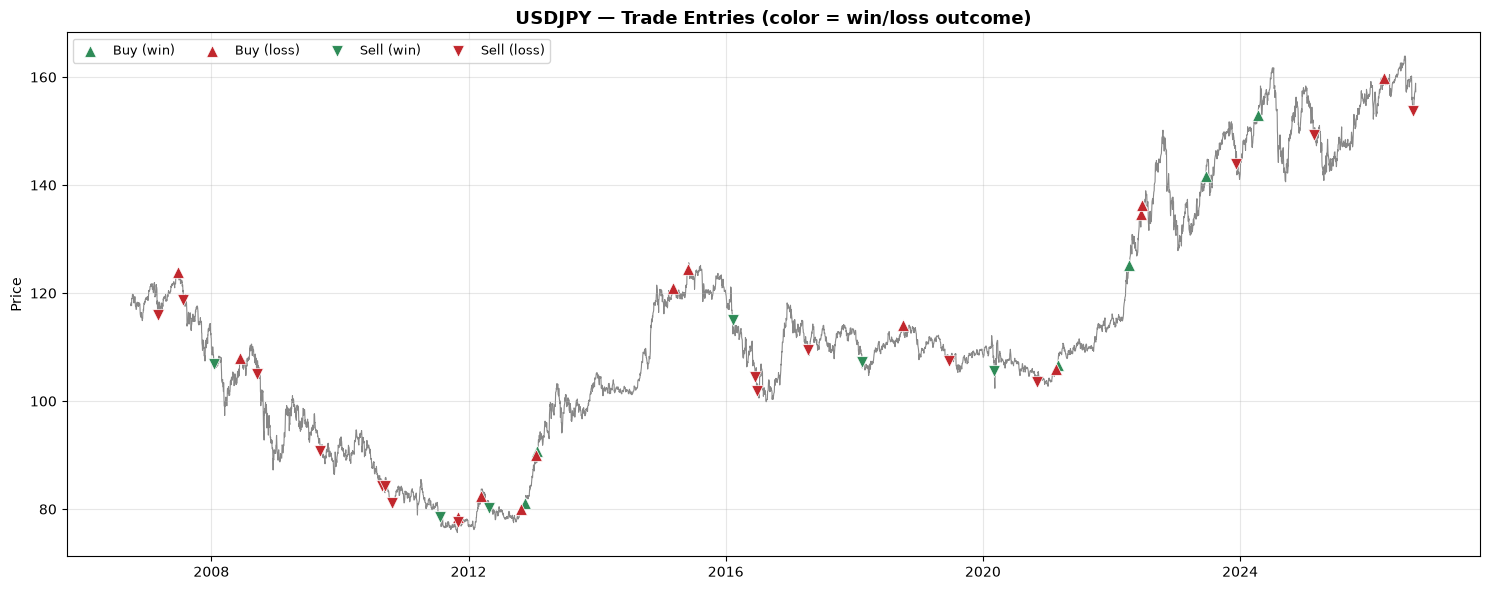

Showing 41 of 193 total trades — USDJPY won the Global Lock most often.


In [36]:
if not trades.empty:
    # Plot whichever symbol took the most trades under the Global Lock — the clearest
    # single picture of what this strategy actually does on a chart.
    top_symbol = trades['symbol'].value_counts().idxmax()
    sym_trades = trades[trades['symbol'] == top_symbol]
    price = dfs[top_symbol]

    fig, ax = plt.subplots(figsize=(15, 6))
    ax.plot(price['date'], price['close'], color=PALETTE["neutral"], linewidth=0.8, alpha=0.8, zorder=1)

    wins = sym_trades[sym_trades['pnl'] > 0]
    losses = sym_trades[sym_trades['pnl'] <= 0]
    for d, marker, label in [(1, '^', 'Buy'), (2, 'v', 'Sell')]:
        w = wins[wins['direction'] == d]
        l = losses[losses['direction'] == d]
        ax.scatter(w['entry_date'], w['entry_price'], marker=marker, color=PALETTE["win"],
                   s=70, zorder=3, edgecolor='white', linewidth=0.5, label=f'{label} (win)')
        ax.scatter(l['entry_date'], l['entry_price'], marker=marker, color=PALETTE["loss"],
                   s=70, zorder=3, edgecolor='white', linewidth=0.5, label=f'{label} (loss)')

    ax.set_title(f'{top_symbol} — Trade Entries (color = win/loss outcome)', fontsize=13, fontweight='bold')
    ax.set_ylabel('Price')
    ax.legend(loc='upper left', ncol=4, fontsize=9)
    plt.tight_layout()
    plt.show()
    print(f"Showing {len(sym_trades)} of {len(trades)} total trades — {top_symbol} won the Global Lock most often.")


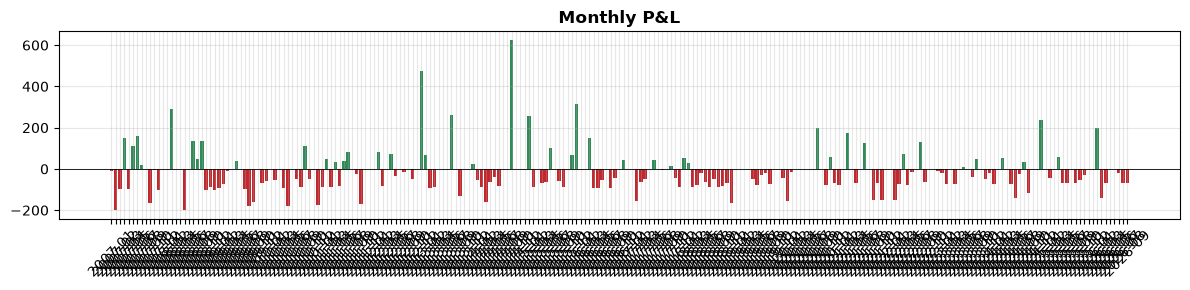

In [37]:
if not trades.empty:
    monthly = trades.set_index('exit_date')['pnl'].resample('ME').sum()
    fig, ax = plt.subplots(figsize=(12, 3))
    colors = [PALETTE["loss"] if v < 0 else PALETTE["win"] for v in monthly]
    ax.bar(monthly.index.strftime('%Y-%m'), monthly.values, color=colors)
    ax.set_title('Monthly P&L', fontweight='bold')
    ax.axhline(0, color='black', linewidth=0.6)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

---
## 12. Robustness Checks 🔒

A backtest number in isolation is easy to overtrust. These two checks are the minimum bar for "is this result real or noise": does performance hold up across different time slices, and does the trade *order* matter?


In [38]:
def temporal_consistency(trades, df, n_folds=6):
    """
    Splits the backtest into `n_folds` equal slices of CALENDAR TIME (not equal
    numbers of trades) and reports win rate / P&L per fold, plus a chi-square test
    for whether the folds' win rates differ from each other by more than chance.
    Calendar-time folds matter: a quiet period with fewer trades gets its own fold
    instead of being merged into a busier neighbor, which is the more honest check.
    """
    if trades.empty: print("No trades to fold."); return None
    start, end = df["date"].min(), df["date"].max()
    fold_len = (end - start) / n_folds
    rows = []
    for f in range(n_folds):
        fs, fe = start + fold_len * f, start + fold_len * (f + 1)
        is_last_fold = (f == n_folds - 1)
        # The last fold's upper bound must be inclusive, or a trade entering on the
        # dataset's exact final timestamp is silently dropped from every fold.
        mask = (trades["entry_date"] >= fs) & (trades["entry_date"] <= fe if is_last_fold else trades["entry_date"] < fe)
        fold = trades[mask]
        rows.append({"fold": f + 1, "start": fs.date(), "end": fe.date(), "trades": len(fold),
                      "win_rate": (fold["pnl"] > 0).mean() if len(fold) else np.nan,
                      "total_pnl": fold["pnl"].sum()})
    fold_df = pd.DataFrame(rows)
    print(fold_df.to_string(index=False))
    print(f"🔶 Profitable folds: {(fold_df['total_pnl'] > 0).sum()}/{n_folds}")
    if fold_df['win_rate'].notna().any():
        print(f"🔶 Win rate range across folds: {fold_df['win_rate'].min():.1%} - {fold_df['win_rate'].max():.1%}")
    try:
        from scipy.stats import chi2_contingency
        cont = [[int(round(r["trades"] * r["win_rate"])), r["trades"] - int(round(r["trades"] * r["win_rate"]))]
                for _, r in fold_df.iterrows() if r["trades"] > 0]
        if len(cont) >= 2:
            chi2, p, dof, expected = chi2_contingency(cont)
            print(f"🔶 Chi-square test (are fold win rates different from each other?): "
                  f"p={p:.4f} {'(win rates differ across folds)' if p < 0.05 else '(no detectable difference between folds)'}"
                  f" -- this tests homogeneity of win rate, NOT whether the edge is negative (see the expectancy bootstrap below)")
    except ImportError:
        pass
    return fold_df

def monte_carlo(trades, initial_capital, n_sims=1000, seed=42, risk_percent=None):
    """
    Reshuffles the trade sequence `n_sims` times to separate "the strategy has an
    edge" from "the trades happened to land in a favorable order." Reports risk of
    ruin (equity ever dropping to 50% of starting capital across the shuffles),
    95% VaR, and 95% CVaR on the resulting max-drawdown distribution.
    """
    if trades.empty: print("No trades to simulate."); return
    rng = np.random.default_rng(seed)
    pnls = trades["pnl"].values
    max_dds, ruin = [], 0
    for _ in tqdm(range(n_sims), desc="Monte Carlo simulations"):
        eq = np.r_[initial_capital, initial_capital + np.cumsum(rng.permutation(pnls))]   # start-of-run capital counts as a peak
        peak = np.maximum.accumulate(eq)
        max_dds.append(((peak - eq) / peak).max())
        if (eq <= initial_capital * 0.5).any(): ruin += 1
    max_dds = np.sort(max_dds)
    var95 = max_dds[int(0.95 * n_sims) - 1]
    cvar = max_dds[int(0.95 * n_sims):].mean()
    
    print("🔶 Monte Carlo Simulation Results:")
    print(f" 🔸 Expected Final Capital: ${(initial_capital + pnls.sum()):,.2f}") # Simplified for notebook
    print(f" 🔸 Order-shuffle only: P(equity ever <= 50%) = {ruin / n_sims:.2%}   (same trades, random order -- says nothing about edge)")
    print(f" 🔸 95% VaR (Max Expected DD): {var95:.2%} (${initial_capital * var95:,.2f})")
    print(f" 🔸 95% CVaR (Avg Worst DD): {cvar:.2%} (${initial_capital * cvar:,.2f})")

    # (b) RESAMPLE WITH REPLACEMENT in R-multiples, compounding at the fixed risk %: "if the next N trades come from
    # this same distribution, how often does the account touch -50%, and how often does it end below the start?"
    rp = risk_percent if risk_percent is not None else PROFILE["risk_percent"]
    R = (trades["pnl"] / trades["risk_amount"]).replace([np.inf, -np.inf], np.nan).dropna().values
    if len(R) >= 10:
        hits, finals = 0, []
        for _ in range(n_sims):
            eq = initial_capital * np.cumprod(1.0 + rp * rng.choice(R, size=len(R), replace=True))
            finals.append(eq[-1]); hits += int((eq <= initial_capital * 0.5).any())
        finals = np.array(finals)
        print(f" 🔸 Resampled (with replacement, {len(R)} trades): P(touch -50%) = {hits / n_sims:.2%} | "
              f"P(end below start) = {(finals < initial_capital).mean():.2%} | median final ${np.median(finals):,.0f}")


print("〰️" * 25)
print("❇️ MONTE CARLO SIMULATION RESULTS ")
print("〰️" * 25)
print("🔽 Running full Monte Carlo robustness test...")
monte_carlo(trades, CONFIG["initial_capital"], risk_percent=PROFILE["risk_percent"])

print("〰️" * 25)
print("❇️ TEMPORAL CONSISTENCY CHECK")
print("〰️" * 25)
print("🔽 Running Temporal Consistency analysis (6 folds)...")
temporal_consistency(trades, dfs[CONFIG["symbols"][0]])

〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️
❇️ MONTE CARLO SIMULATION RESULTS 
〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️
🔽 Running full Monte Carlo robustness test...


Monte Carlo simulations:   0%|          | 0/1000 [00:00<?, ?it/s]

🔶 Monte Carlo Simulation Results:
 🔸 Expected Final Capital: $6,586.08
 🔸 Order-shuffle only: P(equity ever <= 50%) = 0.20%   (same trades, random order -- says nothing about edge)
 🔸 95% VaR (Max Expected DD): 44.04% ($4,403.77)
 🔸 95% CVaR (Avg Worst DD): 45.76% ($4,575.72)
 🔸 Resampled (with replacement, 193 trades): P(touch -50%) = 5.90% | P(end below start) = 99.10% | median final $6,528
〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️
❇️ TEMPORAL CONSISTENCY CHECK
〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️
🔽 Running Temporal Consistency analysis (6 folds)...
 fold      start        end  trades  win_rate    total_pnl
    1 2006-09-29 2010-01-28      38  0.289474  -823.404901
    2 2010-01-28 2013-05-29      38  0.315789  -220.227800
    3 2013-05-29 2016-09-26      25  0.280000   215.533816
    4 2016-09-26 2020-01-26      32  0.218750 -1366.920489
    5 2020-01-26 2023-05-27      30  0.266667  -634.555892
    6 2023-05-27 2026-09-24      30  0.233333  -584.349359
🔶 Prof

,fold,start,end,trades,win_rate,total_pnl
0,1,2006-09-29,2010-01-28,38,0.289474,-823.404901
1,2,2010-01-28,2013-05-29,38,0.315789,-220.227800
2,3,2013-05-29,2016-09-26,25,0.280000,215.533816
3,4,2016-09-26,2020-01-26,32,0.218750,-1366.920489
4,5,2020-01-26,2023-05-27,30,0.266667,-634.555892
5,6,2023-05-27,2026-09-24,30,0.233333,-584.349359


In [39]:
def expectancy_ci(trades, n_boot=10_000, seed=7):
    """Bootstrap CI on mean R-multiple per trade (R = pnl / risk_amount). Answers 'is the edge distinguishable from zero?'
    directly -- unlike the fold chi-square, which only tests whether win rates differ between time slices."""
    R = (trades["pnl"] / trades["risk_amount"]).replace([np.inf, -np.inf], np.nan).dropna().values
    if len(R) < 10: print("Too few trades for a bootstrap."); return None
    rng = np.random.default_rng(seed)
    means = np.array([rng.choice(R, size=len(R), replace=True).mean() for _ in range(n_boot)])
    lo, hi = np.percentile(means, [2.5, 97.5])
    out = {"n": len(R), "mean_R": R.mean(), "ci_lo": lo, "ci_hi": hi, "p_mean_gt_0": (means > 0).mean()}
    print(f"🔶 Expectancy: {R.mean():+.3f} R/trade over {len(R)} trades | 95% bootstrap CI [{lo:+.3f}, {hi:+.3f}] | P(mean > 0) = {out['p_mean_gt_0']:.1%}")
    print("   -> " + ("CI excludes zero on the negative side -- but if the upper bound is close to zero, say 'no demonstrated edge, probably negative'. The bootstrap treats trades as independent; trades across pairs are correlated, so the true interval is wider than shown." if hi < 0 else
                       "CI excludes zero on the positive side." if lo > 0 else
                       "CI straddles zero: with this many trades the result cannot be told apart from no edge -- say 'no evidence of edge', not 'proven negative'."))
    return out

exp_ci = expectancy_ci(trades)

🔶 Expectancy: -0.209 R/trade over 193 trades | 95% bootstrap CI [-0.380, -0.020] | P(mean > 0) = 1.7%
   -> CI excludes zero on the negative side -- but if the upper bound is close to zero, say 'no demonstrated edge, probably negative'. The bootstrap treats trades as independent; trades across pairs are correlated, so the true interval is wider than shown.


---
## 13. Cost Sensitivity Test

Three runs on the **same signals**: **A** naive (how the source videos priced things: same-bar close fill, no costs), **B** production fills with **zero** cost, **C** production with real
spread, slippage and commission. **B − C isolates cost drag exactly**; **A − B** is the difference caused by fill timing alone (next-bar mid fill instead of same-bar close).
Comparing A to C directly would mix the two. If B is already negative, the signal has no gross edge and costs only made it worse.

In [40]:
print("Three runs on the SAME signals -- only the execution model changes:\n")
_prod_profile_free = {**PROFILE, "zero_costs": True}
equity_curve_naive, trades_naive = run_portfolio_backtest(dfs, CONFIG, PROFILE, "naive", SIZING_MODE, show_progress=False)
equity_curve_free,  trades_free  = run_portfolio_backtest(dfs, CONFIG, _prod_profile_free, "production", SIZING_MODE, show_progress=False)
metrics_naive = None   # (kept for compatibility with older cells)

def _summ(t, eq):
    if t.empty: return {"trades": 0}
    w, l = t.loc[t["pnl"] > 0, "pnl"].sum(), abs(t.loc[t["pnl"] <= 0, "pnl"].sum())
    return {"trades": len(t), "win_rate": (t["pnl"] > 0).mean(), "profit_factor": w / l if l else np.inf,
            "avg_pips": t["pips"].mean(), "net_pnl": t["pnl"].sum(),
            "return_pct": (eq["equity"].iloc[-1] - CONFIG["initial_capital"]) / CONFIG["initial_capital"] * 100}

cost_comparison = pd.DataFrame({
    "A. naive (source-style: same-bar close fill, no costs)": _summ(trades_naive, equity_curve_naive),
    "B. production fills, ZERO cost":                          _summ(trades_free, equity_curve_free),
    "C. production, real cost":                                _summ(trades, equity_curve),
}).T
display(cost_comparison.round(3))
_a, _b, _c = (cost_comparison.loc[k, "net_pnl"] for k in cost_comparison.index)
cost_drag = _b - _c
print(f"\nCost drag        (B - C, pure spread+slippage+commission): ${cost_drag:,.2f}   <- the number that isolates costs")
print(f"Fill/timing gap  (A - B, next-bar mid fill vs same-bar close, no cost): ${_a - _b:,.2f}")
print("If B is already negative, the signal has no gross edge and costs only made it worse.")
print("Note: trade counts differ between rows because the one-position Global Lock makes the path depend on fills.")


Three runs on the SAME signals -- only the execution model changes:



,trades,win_rate,profit_factor,avg_pips,net_pnl,return_pct
"A. naive (source-style: same-bar close fill, no costs)",199.0,0.296,0.687,-31.230,-3203.452,-32.035
"B. production fills, ZERO cost",192.0,0.266,0.660,-38.357,-3225.995,-32.260
"C. production, real cost",193.0,0.269,0.644,-40.390,-3413.925,-34.139



Cost drag        (B - C, pure spread+slippage+commission): $187.93   <- the number that isolates costs
Fill/timing gap  (A - B, next-bar mid fill vs same-bar close, no cost): $22.54
If B is already negative, the signal has no gross edge and costs only made it worse.
Note: trade counts differ between rows because the one-position Global Lock makes the path depend on fills.


---
## 14. Multi-Pair Backtesting

Two different questions:

- **14a** re-slices the Section 9/10 Global-Lock portfolio result by symbol — "given the one-position-at-a-time constraint, how did each pair do?"
- **14b** removes that constraint and runs each pair on its own account — "does this signal have edge on pair X, independent of the other six?"
- **14c** re-runs the Global-Lock portfolio under different symbol orders, because the lock gives the slot to whichever symbol is first in the list.

The gap between 14a and 14b is only interpretable once 14c shows how much the list order matters. All figures are printed by the cells themselves; none are hard-coded here.

---
### 14a. Portfolio Summary (Global Lock Enforced)

Per-pair breakdown of the same Global-Lock run reported in Section 10 — no new backtest, just grouped by symbol. Per-pair trade counts are small and are a direct consequence
of the lock: whichever pair fires first wins the shared slot, and every other pair's signal at that moment is discarded until the position closes (see Section 9). Per-pair win rates on
a few dozen trades each are very noisy.

In [41]:

if not trades.empty:
    combined_pnl = trades['pnl'].sum()
    combined_wins = sum(1 for p in trades['pnl'] if p > 0)
    combined_wr = combined_wins / len(trades)

    print("〰️" * 25)
    print("❇️ PORTFOLIO SUMMARY (Global Lock Enforced)")
    print("〰️" * 25)
    print(f"🔶 Pairs Scanned: {', '.join(CONFIG['symbols'])}")

    symbol_stats = trades.groupby('symbol').agg(
        total_trades=('pnl', 'count'),
        wins=('pnl', lambda x: (x > 0).sum()),
        losses=('pnl', lambda x: (x <= 0).sum())
    ).reset_index()
    symbol_stats['win_rate'] = symbol_stats['wins'] / symbol_stats['total_trades']

    print("🔶 Performance by Currency Pair:")
    for _, row in symbol_stats.iterrows():
        print(
            f"  🔸 {row['symbol']:<8} | Trades: {int(row['total_trades']):>3} | Wins: {int(row['wins']):>3} | Losses: {int(row['losses']):>3} | Win Rate: {row['win_rate']:.1%}")
    print("〰️" * 10)

    print(f"🔶 Total Combined Trades: {len(trades)}")
    print(f"🔶 Combined Win Rate: {combined_wr:.2%}")
    print(f"🔶 Combined Net PnL: ${combined_pnl:,.2f}")
    print("〰️" * 50)
else:
    print("No trades executed in this portfolio backtest.")

〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️
❇️ PORTFOLIO SUMMARY (Global Lock Enforced)
〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️
🔶 Pairs Scanned: EURUSD, GBPUSD, USDJPY, USDCHF, AUDUSD, USDCAD, NZDUSD
🔶 Performance by Currency Pair:
  🔸 AUDUSD   | Trades:  23 | Wins:   8 | Losses:  15 | Win Rate: 34.8%
  🔸 EURUSD   | Trades:  40 | Wins:   8 | Losses:  32 | Win Rate: 20.0%
  🔸 GBPUSD   | Trades:  18 | Wins:   4 | Losses:  14 | Win Rate: 22.2%
  🔸 NZDUSD   | Trades:  23 | Wins:   8 | Losses:  15 | Win Rate: 34.8%
  🔸 USDCAD   | Trades:  28 | Wins:   3 | Losses:  25 | Win Rate: 10.7%
  🔸 USDCHF   | Trades:  20 | Wins:   9 | Losses:  11 | Win Rate: 45.0%
  🔸 USDJPY   | Trades:  41 | Wins:  12 | Losses:  29 | Win Rate: 29.3%
〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️
🔶 Total Combined Trades: 193
🔶 Combined Win Rate: 26.94%
🔶 Combined Net PnL: $-3,413.92
〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️〰️


---
### 14b. Multi-Pair Generalization Test

Section 12's temporal-consistency check asks whether win rate differs between six equal calendar slices. Note what that does and does not show: a high chi-square p-value means
*no detectable difference between slices* — it does **not** test whether the edge is negative. The bootstrap on expectancy (Section 12) answers that directly.

This section asks a different question: with the Global Lock removed (each pair backtested alone on its own account), does the signal show edge on any individual pair?
Read the printout as "how many of seven pairs are profitable, and by how much", then check 14c before attributing any gap between this and the Global-Lock number to
lock "opportunity cost". Two cautions: (1) each row here is a separate $10k account, so summing or comparing it with one shared account is not like-for-like; (2) the like-for-like comparison is the *sum* of the seven standalone P&Ls against the one shared account, not the average per-pair return — 14d prints it. Compare like with like before saying the lock helped or hurt.

Since `CONFIG["symbols"]` already holds all seven majors, every pair is already fetched and signaled by Sections 1-9 and this cell reuses that data. The per-pair buy-and-hold column is
shown for reference only — it is not a meaningful FX benchmark.

In [42]:
TEST_SYMBOLS = CONFIG["symbols"]   # now MAJOR_PAIRS -- extend further here to test a non-major pair too

multi_pair_dfs = dict(dfs)   # every symbol in CONFIG["symbols"] is already fetched/signaled by Section 8 -- reuse, don't refetch
multi_pair_results = []

for sym in tqdm(TEST_SYMBOLS, desc="Multi-pair test"):
    if sym not in multi_pair_dfs:
        print(f"\n--- Preparing {sym} ---")
        raw = fetch_oanda_candles(sym, CONFIG["granularity"], CONFIG["days"],
                                    price=CONFIG["price_component"], force_refresh=CONFIG["force_refresh"])
        raw_h1 = fetch_oanda_candles(sym, "H1", CONFIG["days"],
                                       price=CONFIG["price_component"], force_refresh=CONFIG["force_refresh"])
        raw = add_indicators(raw, sym)
        raw["is_closed"] = compute_is_closed(raw)   # was missing: KeyError as soon as holiday_filter_enabled=True
        raw = merge_h1_bias(raw, raw_h1)

        raw = STRATEGY_VARIANTS[ACTIVE_VARIANT](raw, sym, PROFILE)

        raw = add_vol_regime(raw)
        multi_pair_dfs[sym] = raw

    sym_df = multi_pair_dfs[sym]
    eq, tr = run_portfolio_backtest({sym: sym_df}, CONFIG, PROFILE, EXECUTION_MODE, SIZING_MODE,
                                     show_progress=False)

    final_eq = eq["equity"].iloc[-1] if not eq.empty else CONFIG["initial_capital"]
    ret = (final_eq - CONFIG["initial_capital"]) / CONFIG["initial_capital"]
    wr = (tr["pnl"] > 0).mean() if not tr.empty else float("nan")
    gp = tr.loc[tr["pnl"] > 0, "pnl"].sum() if not tr.empty else 0.0
    gl = abs(tr.loc[tr["pnl"] <= 0, "pnl"].sum()) if not tr.empty else 0.0
    pf = gp / gl if gl > 0 else float("nan")
    bh_ret = (sym_df["close"].iloc[-1] - sym_df["close"].iloc[0]) / sym_df["close"].iloc[0]

    multi_pair_results.append({
        "symbol": sym, "trades": len(tr), "win_rate": wr, "profit_factor": pf,
        "total_return": ret, "buy_hold_return": bh_ret, "outperformance": ret - bh_ret,
    })
    print(f"{sym}: {len(tr)} trades, {wr:.1%} WR, PF {pf:.2f}, return {ret:+.2%} "
          f"(buy&hold {bh_ret:+.2%})")

multi_pair_df = pd.DataFrame(multi_pair_results).set_index("symbol")
print("\n" + "=" * 70)
print("  Multi-Pair Summary — same strategy, same profile, same 20-year window")
print("=" * 70)
for sym, row in multi_pair_df.iterrows():
    print(f"  {sym:<8} {row['trades']:>4} trades | WR {row['win_rate']:>6.1%} | "
          f"PF {row['profit_factor']:>5.2f} | Return {row['total_return']:>+8.2%} | "
          f"B&H {row['buy_hold_return']:>+8.2%} | Diff {row['outperformance']:>+8.2%}")

profitable_count = (multi_pair_df["total_return"] > 0).sum()
print(f"\nProfitable on {profitable_count} of {len(multi_pair_df)} pairs tested.")


Multi-pair test:   0%|          | 0/7 [00:00<?, ?it/s]

EURUSD: 70 trades, 34.3% WR, PF 1.00, return +0.04% (buy&hold -10.13%)
GBPUSD: 54 trades, 29.6% WR, PF 1.01, return +0.34% (buy&hold -29.26%)
USDJPY: 71 trades, 32.4% WR, PF 0.82, return -6.55% (buy&hold +33.13%)
USDCHF: 67 trades, 40.3% WR, PF 0.76, return -7.47% (buy&hold -33.74%)
AUDUSD: 67 trades, 28.4% WR, PF 0.67, return -11.77% (buy&hold -5.85%)
USDCAD: 62 trades, 32.3% WR, PF 1.20, return +7.44% (buy&hold +26.52%)
NZDUSD: 70 trades, 35.7% WR, PF 0.72, return -10.29% (buy&hold -13.22%)

  Multi-Pair Summary — same strategy, same profile, same 20-year window
  EURUSD   70.0 trades | WR  34.3% | PF  1.00 | Return   +0.04% | B&H  -10.13% | Diff  +10.16%
  GBPUSD   54.0 trades | WR  29.6% | PF  1.01 | Return   +0.34% | B&H  -29.26% | Diff  +29.60%
  USDJPY   71.0 trades | WR  32.4% | PF  0.82 | Return   -6.55% | B&H  +33.13% | Diff  -39.68%
  USDCHF   67.0 trades | WR  40.3% | PF  0.76 | Return   -7.47% | B&H  -33.74% | Diff  +26.27%
  AUDUSD   67.0 trades | WR  28.4% | PF  0.67 | R

#### 14c. Does the Global Lock's symbol order change the answer?

The lock hands the slot to whichever symbol comes **first in the list** when two fire on the same bar. If total return moves a lot when only that
order changes, "the lock has an opportunity cost" is really "the headline depends on list order" — and the honest number is the *average* across orders.

In [43]:
def lock_order_test(n_orders=8, seed=11):
    syms = list(CONFIG["symbols"]); rng = random.Random(seed)
    orders = [syms, syms[::-1]] + [rng.sample(syms, len(syms)) for _ in range(max(0, n_orders - 2))]
    rows, per_sym_wr = [], {}
    for o in orders:
        eq, tr = run_portfolio_backtest({s: dfs[s] for s in o}, CONFIG, PROFILE, EXECUTION_MODE, SIZING_MODE, show_progress=False)
        if tr.empty: continue
        w, l = tr.loc[tr["pnl"] > 0, "pnl"].sum(), abs(tr.loc[tr["pnl"] <= 0, "pnl"].sum())
        rows.append({"order": ">".join(x.replace("USD", "") for x in o), "trades": len(tr), "win_rate": (tr["pnl"] > 0).mean(),
                     "profit_factor": w / l if l else np.inf, "return_pct": (eq["equity"].iloc[-1] / CONFIG["initial_capital"] - 1) * 100})
        for s, g in tr.groupby("symbol"): per_sym_wr.setdefault(s, []).append((g["pnl"] > 0).mean())
    df = pd.DataFrame(rows)
    display(df.round(3))
    print(f"Return across {len(df)} orders: mean {df['return_pct'].mean():+.1f}% | min {df['return_pct'].min():+.1f}% | max {df['return_pct'].max():+.1f}%")
    print("Per-symbol win-rate range across orders: " + ", ".join(f"{s} {min(v):.0%}-{max(v):.0%}" for s, v in sorted(per_sym_wr.items())))
    return df

lock_orders = lock_order_test()
_standalone_mean = multi_pair_df["total_return"].mean() * 100
print(f"Mean of the 7 standalone per-pair returns (each on its own $10k account): {_standalone_mean:+.1f}%  -- NOT directly comparable to one shared account.")

,order,trades,win_rate,profit_factor,return_pct
0,EUR>GBP>JPY>CHF>AUD>CAD>NZD,193,0.269,0.644,-34.139
1,NZD>CAD>AUD>CHF>JPY>GBP>EUR,184,0.288,0.758,-24.781
2,CHF>AUD>NZD>CAD>JPY>EUR>GBP,191,0.272,0.648,-34.002
3,NZD>AUD>CHF>GBP>EUR>CAD>JPY,186,0.274,0.703,-28.616
4,GBP>EUR>AUD>CAD>JPY>NZD>CHF,194,0.263,0.616,-36.906
5,CAD>NZD>AUD>GBP>JPY>EUR>CHF,188,0.271,0.727,-27.919
6,EUR>NZD>GBP>AUD>JPY>CAD>CHF,191,0.272,0.652,-33.242
7,JPY>CHF>AUD>GBP>NZD>EUR>CAD,186,0.296,0.707,-27.693


Return across 8 orders: mean -30.9% | min -36.9% | max -24.8%
Per-symbol win-rate range across orders: AUDUSD 29%-39%, EURUSD 19%-29%, GBPUSD 16%-24%, NZDUSD 31%-38%, USDCAD 10%-19%, USDCHF 35%-47%, USDJPY 26%-30%
Mean of the 7 standalone per-pair returns (each on its own $10k account): -4.0%  -- NOT directly comparable to one shared account.


---
#### 14d. Standalone vs Global Lock — like-for-like

14b runs each pair on its own $10k account; 14a/14c run all seven through one Global Lock (one open position at a time).
**Do not compare the *average* per-pair return with the shared-account return** — that is seven small accounts against one, and it
makes the two look far apart when they are not. The like-for-like figure is the *sum* of the seven standalone P&Ls (as a share of one
$10k start) against the shared account's P&L; the cell prints both. The table then lines the two up per pair (trades, return, win rate) and
reports how much of the 20 years the lock was occupied, which explains why it takes fewer trades. If a pair's win rate inside the lock is far
below its standalone win rate, the trades the lock *skipped* were better than the ones it took — occupancy alone does not explain that, so
say it is unexplained rather than inventing a cause.


In [44]:
_lock_tr = trades.copy()
_start = min(dfs[s]["date"].min() for s in CONFIG["symbols"]); _end = max(dfs[s]["date"].max() for s in CONFIG["symbols"])
_span_days = (_end - _start).days
_rows = []
for s in CONFIG["symbols"]:
    g = _lock_tr[_lock_tr["symbol"] == s]
    _rows.append({"symbol": s,
                  "raw_signals": int((dfs[s]["signal"] != 0).sum()),
                  "standalone_trades": int(multi_pair_df.loc[s, "trades"]),
                  "lock_trades": len(g),
                  "standalone_win_rate": multi_pair_df.loc[s, "win_rate"],
                  "standalone_return_pct": multi_pair_df.loc[s, "total_return"] * 100,
                  "lock_pnl_pct_of_start": g["pnl"].sum() / CONFIG["initial_capital"] * 100,
                  "lock_win_rate": (g["pnl"] > 0).mean() if len(g) else np.nan})
lock_vs_standalone = pd.DataFrame(_rows).set_index("symbol")
display(lock_vs_standalone.round(2))

_sa_n, _lk_n = int(lock_vs_standalone["standalone_trades"].sum()), int(lock_vs_standalone["lock_trades"].sum())
print(f"Standalone trades summed across pairs: {_sa_n} | trades the shared Global Lock actually took: {_lk_n} ({_lk_n / _sa_n:.0%})")
if {"entry_date", "exit_date"} <= set(_lock_tr.columns):
    _held = (_lock_tr["exit_date"] - _lock_tr["entry_date"]).dt.total_seconds() / 86400
    print(f"Median holding time: {_held.median():.1f} days | mean {_held.mean():.1f} days | lock occupied ~{_held.sum() / _span_days:.0%} of the {_span_days / 365.25:.0f}-year span")
else:
    print("(no entry_date column on trades -- holding-time / occupancy line skipped)")
_sa_sum = multi_pair_df["total_return"].sum() * 100
_lk_now = _lock_tr["pnl"].sum() / CONFIG["initial_capital"] * 100
_lk_avg = f" | mean over symbol orders {lock_orders['return_pct'].mean():+.1f}%" if "lock_orders" in globals() else ""
print(f"LIKE-FOR-LIKE: summed standalone P&L = {_sa_sum:+.1f}% of one $10k start | shared Global-Lock account = {_lk_now:+.1f}% (default order){_lk_avg}")
print("(The per-pair MEAN of standalone returns, {:+.1f}%, is not comparable to the shared account -- do not put it next to it.)".format(multi_pair_df["total_return"].mean() * 100))
print("Per-pair standalone returns are each on a separate $10k account; lock_pnl_pct_of_start is that pair's P&L inside the ONE shared account.")


,raw_signals,standalone_trades,lock_trades,standalone_win_rate,standalone_return_pct,lock_pnl_pct_of_start,lock_win_rate
symbol,,,,,,,
EURUSD,168,70,40,0.34,0.04,-7.77,0.20
GBPUSD,123,54,18,0.30,0.34,-3.02,0.22
USDJPY,136,71,41,0.32,-6.55,-4.63,0.29
USDCHF,147,67,20,0.40,-7.47,-4.23,0.45
AUDUSD,142,67,23,0.28,-11.77,-1.25,0.35
USDCAD,154,62,28,0.32,7.44,-10.61,0.11
NZDUSD,164,70,23,0.36,-10.29,-2.64,0.35


Standalone trades summed across pairs: 461 | trades the shared Global Lock actually took: 193 (42%)
Median holding time: 14.0 days | mean 19.2 days | lock occupied ~51% of the 20-year span
LIKE-FOR-LIKE: summed standalone P&L = -28.3% of one $10k start | shared Global-Lock account = -34.1% (default order) | mean over symbol orders -30.9%
(The per-pair MEAN of standalone returns, -4.0%, is not comparable to the shared account -- do not put it next to it.)
Per-pair standalone returns are each on a separate $10k account; lock_pnl_pct_of_start is that pair's P&L inside the ONE shared account.


In [45]:
# Section 15's findings describe Strategy 8 only -- Sections 10-14 analyze whatever ACTIVE_VARIANT is set to.
if ACTIVE_VARIANT != "8_control_breakout":
    print(f"⚠️  ACTIVE_VARIANT is {ACTIVE_VARIANT!r}: the Strategy 8 findings in the next cell do NOT describe the Sections 10-14 output above.")
else:
    print("✅ ACTIVE_VARIANT is Strategy 8 -- Section 15's findings match the Sections 10-14 output above.")

✅ ACTIVE_VARIANT is Strategy 8 -- Section 15's findings match the Sections 10-14 output above.


---
## 15. Strategy 8: Findings & Conclusion

Run the `RECEIPTS` cell directly above once, on the final frozen run, and take every number for the video from its output (R1–R13). The text below is the *shape* of the conclusion; it is only
valid where the **CONCLUSION CHECK** boxes at the bottom of that output are ticked. Untick = change the wording, not the numbers.

**What to check in the receipts, and how to say it**
- **Did it lose after costs, and is that distinguishable from noise?** R1 gives the headline; R5 gives the expectancy CI. If the CI straddles zero, say "no evidence of an edge". Even when it sits below zero, an upper bound near zero (as here) and trades that are correlated across pairs mean the honest phrasing is **"no demonstrated edge, and probably a negative one"** — not "a negative edge across the board".
- **Is it one mechanism?** R2 shows exit-reason shares. With an ATR-trail-only exit, every trade should exit via STOP_LOSS (initial or trailed); the share of stop-outs that closed in profit is the trail doing its job.
- **Is it one bad regime?** R3 lists the net-positive years explicitly. Only make a "persistent across two decades" claim if the yearly table supports it.
- **Costs vs signal:** R8 separates cost drag from fill timing (Section 13). If the zero-cost return is already negative, costs are not the explanation.
- **Portfolio vs standalone:** R6, R7 and R12 together. R1 is one draw of the symbol order; quote the mean across orders with its range (R7), not the default-order number. R12 (Section 14d) gives the like-for-like comparison (summed standalone P&L vs the shared account) and how many standalone trades the lock skips — never put the *average* per-pair return next to the shared-account return.
- **Strategy 3 / RSI hook:** R13 — the hook-off row is the honest one; Strategy 3 is not a survivor.
- **Modelling sensitivity:** R9 (entry fill basis) and R4 (timeframe-normalised regimes). If either moves the headline materially, disclose it on screen.

**Conclusion (conditional):** if the first two CONCLUSION CHECK boxes pass, a textbook-clean, un-retuned Donchian+ADX breakout — built without the flaws documented in 9c — still loses money net of realistic costs (roughly the mean across symbol orders, with the range from R7). Removing the
known implementation flaws was necessary but not sufficient. The pair-level picture is mixed, not uniformly bad (standalone, some pairs are flat or positive — R6), which is why the claim is "no demonstrated edge" rather than "a negative edge". What that does *not* show is that breakout can never work. **Limits of this test, worth one line on screen:** one cost model, one roughly 20-year window (partial first and last years), seven USD-quoted majors that move together with correlated trades, and one Donchian+ADX implementation. So: it shows this implementation, on these instruments and this cost model, has no demonstrated edge.
Whether part of the shortfall is the test harness (one-position lock, list order) is what 14c and 14d are for; do not chase it with new parameters.

In [46]:
# ======================= FINDINGS + RECEIPTS (everything the video says comes from THIS cell's output) =======================
def _yearly(t): return t.groupby(t["exit_date"].dt.year)["pnl"].sum()

print("=" * 78); print(f"RECEIPTS for ACTIVE_VARIANT = {ACTIVE_VARIANT}"); print("=" * 78)
if trades.empty:
    print("No trades.")
else:
    n = len(trades); ic = CONFIG["initial_capital"]
    print(f"R1  trades {n} | win rate {metrics['win_rate']:.1%} | PF {metrics['profit_factor']:.2f} | return {metrics['total_return']:.1%} | "
          f"max DD {metrics['max_drawdown']:.1%} | expectancy ${metrics['expectancy']:.2f}/trade | net P&L ${trades['pnl'].sum():,.2f} "
          f"(closed-trade balance ${trades['balance'].iloc[-1]:,.2f}; sum(pnl) reconciles to it: {abs(trades['pnl'].sum() - (trades['balance'].iloc[-1] - ic)) < 0.01}) | default symbol order = one draw, see R7")
    er = trades["exit_reason"].value_counts(normalize=True).round(3).to_dict()
    so = trades[trades["exit_reason"] == "STOP_LOSS"]
    print(f"R2  exit reasons {er} | stop-outs that closed in profit: {(so['pnl'] > 0).mean() if len(so) else float('nan'):.0%}")
    yr = _yearly(trades); pos = [int(y) for y in yr[yr > 0].index]
    print(f"R3  net-positive years {len(pos)} of {len(yr)}: {pos}")
    print("    yearly P&L ($): " + ", ".join(f"{int(y)}:{v:+,.0f}" for y, v in yr.items()))
    print(f"R4  vol regime of entries: {trades['vol_regime'].value_counts().to_dict()}  (timeframe-normalised -- see Section 7)")
    if exp_ci: print(f"R5  expectancy {exp_ci['mean_R']:+.3f} R | 95% CI [{exp_ci['ci_lo']:+.3f}, {exp_ci['ci_hi']:+.3f}] | P(mean>0) {exp_ci['p_mean_gt_0']:.1%}")
    print(f"R6  standalone per pair: profitable on {(multi_pair_df['total_return'] > 0).sum()} of {len(multi_pair_df)} | "
          + ", ".join(f"{s} {r:+.1%}" for s, r in multi_pair_df['total_return'].items()))
    if "lock_orders" in globals() and len(lock_orders):
        print(f"R7  Global-Lock return across symbol orders: {lock_orders['return_pct'].min():+.1f}% to {lock_orders['return_pct'].max():+.1f}% (mean {lock_orders['return_pct'].mean():+.1f}%)")
    if "lock_vs_standalone" in globals():
        _sa, _lk = int(lock_vs_standalone["standalone_trades"].sum()), int(lock_vs_standalone["lock_trades"].sum())
        _sum = multi_pair_df["total_return"].sum() * 100
        _ord = f" (mean over orders {lock_orders['return_pct'].mean():+.1f}%)" if "lock_orders" in globals() else ""
        print(f"R12 Global Lock took {_lk} of {_sa} summed standalone trades ({_lk / _sa:.0%}) | LIKE-FOR-LIKE: summed standalone P&L {_sum:+.1f}% of one $10k start vs shared account {trades['pnl'].sum() / ic * 100:+.1f}%{_ord} -- do NOT compare the per-pair mean")
    if "s23_rsi_sensitivity" in globals():
        _x = s23_rsi_sensitivity.loc["3_level_break_out_h1"]
        print("R13 Strategy 3 RSI-hook sensitivity (win rate / return %): " + " | ".join(f"{k.split(':')[0]}: {r['win_rate']:.1%} / {r['total_return_pct']:+.1f}%" for k, r in _x.iterrows()))
    if "cost_comparison" in globals():
        print(f"R8  cost drag (zero-cost minus real-cost net P&L): ${cost_drag:,.2f} | zero-cost return {cost_comparison.iloc[1]['return_pct']:+.1f}% vs real-cost {cost_comparison.iloc[2]['return_pct']:+.1f}%")
    if "entry_basis_sensitivity" in globals():
        print("R9  entry fill basis (mid vs open) return %: " + ", ".join(f"{b} {r:+.1f}%" for b, r in entry_basis_sensitivity["return_pct"].items()))
    if "h1_mistake" in globals() and len(h1_mistake):
        r = h1_mistake.iloc[0]; print(f"R10 timeframe mistake (Donchian-55 on H1): {int(r['n_trades'])} trades, {r['total_return_pct']:+.1f}% return")
    if "all_strategies_comparison" in globals():
        print("R11 9a table (return %, trades): " + " | ".join(f"{r['strategy'][:1]}: {r['total_return_pct']:+.1f}% ({int(r['n_trades'])})" for _, r in all_strategies_comparison.sort_values('strategy').iterrows()))

    print("\nCONCLUSION CHECK (the Section 15 text below is only valid if the first two hold):")
    _neg = metrics["total_return"] < 0
    print(f"  [{'x' if _neg else ' '}] Active strategy lost money net of costs")
    if exp_ci:
        _below = exp_ci['ci_hi'] < 0
        print(f"  [{'x' if _below else ' '}] Expectancy CI is entirely below zero (else: say 'no evidence of edge')")
        if _below and exp_ci['ci_hi'] > -0.05:
            print(f"      BORDERLINE: upper bound {exp_ci['ci_hi']:+.3f} R is within 0.05 R of zero, and the bootstrap treats correlated trades as independent -> say 'no demonstrated edge, probably negative', NOT 'negative edge'.")
    _np = int((multi_pair_df['total_return'] > 0).sum())
    print(f"  [i] Standalone profitable pairs: {_np} of {len(multi_pair_df)} (informational, not a validity gate). If more than 1, do NOT say 'loses on every pair' -- quote R6 as a mixed picture.")


RECEIPTS for ACTIVE_VARIANT = 8_control_breakout
R1  trades 193 | win rate 26.9% | PF 0.64 | return -34.1% | max DD 35.3% | expectancy $-17.69/trade | net P&L $-3,413.92 (closed-trade balance $6,586.08; sum(pnl) reconciles to it: True) | default symbol order = one draw, see R7
R2  exit reasons {'STOP_LOSS': 1.0} | stop-outs that closed in profit: 27%
R3  net-positive years 5 of 20: [2008, 2013, 2014, 2015, 2016]
    yearly P&L ($): 2007:-238, 2008:+224, 2009:-750, 2010:-458, 2011:-424, 2012:-21, 2013:+490, 2014:+157, 2015:+58, 2016:+127, 2017:-258, 2018:-640, 2019:-420, 2020:-36, 2021:-286, 2022:-180, 2023:-208, 2024:-355, 2025:-36, 2026:-163
R4  vol regime of entries: {'normal': 159, 'high': 24, 'low': 7, 'extreme': 3}  (timeframe-normalised -- see Section 7)
R5  expectancy -0.209 R | 95% CI [-0.380, -0.020] | P(mean>0) 1.7%
R6  standalone per pair: profitable on 3 of 7 | EURUSD +0.0%, GBPUSD +0.3%, USDJPY -6.6%, USDCHF -7.5%, AUDUSD -11.8%, USDCAD +7.4%, NZDUSD -10.3%
R7  Global-Lock

---
## 16. Signal chart renderer (video assets)

Three cells: **(1)** integrity checks — each charted signal fires once on its entry bar inside the drawn window and is causal (deleting all later bars leaves it unchanged); **(2)** the candlestick renderer used for on-screen signal charts;
**(3)** a demo that runs both across all eight strategies. Nothing here changes results; it produces `videos/` assets.

In [47]:
_STRATEGY_PARAMS_BY_NAME = {
    "1_liquidity_sweep_breakout": STRATEGY_1_PARAMS, "2_level_break_out_daily": STRATEGY_2_PARAMS,
    "3_level_break_out_h1": STRATEGY_3_PARAMS,       "4_channel_breakout": STRATEGY_4_PARAMS,
    "5_box_range_breakout": STRATEGY_5_PARAMS,       "6_candle_bias_session_orb": STRATEGY_6_PARAMS,
    "7_fvg_key_level_break": STRATEGY_7_PARAMS,      "8_control_breakout": STRATEGY_8_PARAMS,
}
_OVERRIDE_KEYS = ("early_exit_enabled", "hard_close_hour", "hard_close_minute",
                  "exit_delay_days", "exit_mode", "atr_trail_multiplier", "max_leverage")


In [48]:
# %% ─────────────────────────────── CELL 1 · checks ──────────────────────────────────
"""Is this signal real? Two questions, answered on the exact bars you are about to draw:
  1. fires_once_on_entry -- inside the visible window the strategy fires on `entry_bar` and nowhere else.
  2. causal              -- delete every bar after the entry bar and the signal, trigger level, SL and TP
                            are identical. If not, the strategy used information it could not have had.
`window` needs date/open/high/low/close plus warm-up before the visible part
(S1 needs 200 bars, S8 60, S7 60, S3 72). Strategy 6 needs real timestamps."""
import numpy as np
import pandas as pd


def _need(*names):
    missing = [n for n in names if n not in globals()]
    if missing:
        raise NameError(f"Run these cells first (they are defined elsewhere in the notebook): {missing}")


def _signals(name, df, symbol, profile):
    return STRATEGY_VARIANTS[name](add_indicators(df, symbol), symbol, profile)


def _same(a, b):
    if pd.isna(a) or pd.isna(b):
        return bool(pd.isna(a) and pd.isna(b))
    return abs(float(a) - float(b)) < 1e-9


class CheckResult(dict):
    """dict that keeps the signal DataFrame under 'signal_df' but does not print it."""
    def __repr__(self):
        return repr({k: v for k, v in self.items() if k != "signal_df"})


def check_signal(name, full_df, entry_bar, visible_from=0, symbol="EURUSD", profile=None):
    profile = profile or PROFILE
    out = _signals(name, full_df, symbol, profile)
    fired = [b for b in np.flatnonzero(out["signal"].values).tolist() if b >= visible_from]
    cut = _signals(name, full_df.iloc[: entry_bar + 1], symbol, profile)        # future removed
    row, crow = out.iloc[entry_bar], cut.iloc[-1]
    same_signal = bool(crow["signal"] == row["signal"])
    same_levels = all(_same(row[k], crow[k]) for k in ("trigger_level", "sl_pips", "tp_pips"))
    return CheckResult(
        strategy=name, entry_bar=int(entry_bar), direction=int(row["signal"]), fired_bars=fired,
        fires_once_on_entry=fired == [entry_bar],
        causal=same_signal and same_levels, causal_signal=same_signal, causal_levels=same_levels,
        sl_pips=row["sl_pips"], tp_pips=row["tp_pips"], trigger_level=row["trigger_level"],
        signal_df=out)


def lookahead_rate(name, df, symbol="EURUSD", profile=None, lookback=1200, future=60):
    """Share of a strategy's signals that vanish when the bars after them are removed."""
    profile = profile or PROFILE
    sig_bars = np.flatnonzero(_signals(name, df, symbol, profile)["signal"].values)
    bad = 0
    for t in sig_bars:
        a = max(0, t - lookback)
        with_future = _signals(name, df.iloc[a: t + future + 1].reset_index(drop=True), symbol, profile)
        no_future = _signals(name, df.iloc[a: t + 1].reset_index(drop=True), symbol, profile)
        bad += with_future["signal"].values[t - a] != no_future["signal"].values[t - a]
    return {"strategy": name, "signals": len(sig_bars), "vanish_without_future": int(bad)}


def repeat_rate(name, df, symbol="EURUSD", profile=None):
    """Consecutive same-direction signal bars: 0 means edge-triggered (fires once per breakout)."""
    sig = _signals(name, df, symbol, profile or PROFILE)["signal"].values
    return {"strategy": name, "signals": int((sig != 0).sum()),
            "consecutive_repeats": int(((sig[1:] != 0) & (sig[1:] == sig[:-1])).sum())}

In [49]:
# %% ─────────────────────────────── CELL 2 · renderer ────────────────────────────────
"""Render a REAL, validated signal as a 1920x1080 MP4 in the QuantStack look.

    check = check_signal(name, window, entry_bar, ...)          # cell 1
    trade = engine_trade(check["signal_df"], entry_bar, sym, p)  # the engine's own trade on that window
    render_signal_video(name, window, check, "out.mp4", sym=sym, trade=trade, visible_from=...)

  make_signal_video(name)  does all of it for you: finds a real EURUSD signal, refuses to draw it unless
                           it passes the checks, takes the trade from the real engine, renders.

ADDING A STRATEGY LATER -> see the template at the bottom of this cell. With no viz entry at all a
strategy still renders (level + entry + SL/TP + exit from the engine); the entry only adds annotations.
Needs ffmpeg:  `pip install imageio-ffmpeg`  is enough."""
import shutil
import subprocess
import textwrap
from types import SimpleNamespace

import matplotlib
import matplotlib.ticker
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.figure import Figure
from matplotlib.patches import Rectangle
from scipy import stats as _stats

try:
    from tqdm.auto import tqdm as _tqdm
except Exception:                                           # tqdm is optional
    _tqdm = lambda x, **k: x

THEME = dict(bg="#0e0e10", fg="#f2f2f3", muted="#9aa0a6", grid="#232327",
             up="#2e8b57", down="#c1272d", brand="#2E5EAA", accent="#d4a017")

_EXIT_LABEL = {"STOP_LOSS": "Stop-loss hit", "TAKE_PROFIT": "Take-profit hit",
               "TIME_EXIT_DAY_CLOSE": "Session close exit", "EARLY_EXIT_RSI": "RSI early exit",
               "TIME_STOP_LOSS": "Time stop"}


# ------------------------------- the engine's own trade --------------------------------
def engine_trade(sig_df, entry_bar, sym, profile):
    """Run the REAL run_portfolio_backtest on this window with only the entry-bar signal kept, and return
    that trade (entry fill, SL/TP prices, exit bar/price/reason) or None if it is still open at the end.
    Nothing is re-implemented here, so the video cannot drift from the backtest."""
    _need("run_portfolio_backtest", "add_vol_regime", "compute_is_closed", "CONFIG",
          "EXECUTION_MODE", "SIZING_MODE")
    df = sig_df.copy()
    keep = np.zeros(len(df), dtype=df["signal"].dtype)
    keep[entry_bar] = df["signal"].iloc[entry_bar]          # one signal -> exactly one trade
    df["signal"] = keep
    df["is_closed"] = compute_is_closed(df)
    df = add_vol_regime(df)
    _, trades = run_portfolio_backtest({sym: df}, CONFIG, profile, EXECUTION_MODE, SIZING_MODE,
                                       show_progress=False)
    return None if trades.empty else trades.iloc[0].to_dict()


def _trail_path(trade, df, profile, sym):
    """Stop level the engine checked on each bar of a trailing trade (its own check-then-ratchet order)."""
    d, ps = int(trade["direction"]), pip_size(sym)
    cl, atr = df["close"].to_numpy(float), df["atr_14"].to_numpy(float)
    y, cur = np.full(len(df), np.nan), float(trade["sl_price"])
    for j in range(int(trade["entry_idx"]), int(trade["exit_idx"]) + 1):
        y[j] = cur
        dist = (profile["fixed_trail_pips"] * ps if profile["exit_mode"] == "fixed_trail"
                else atr[j] * profile["atr_trail_multiplier"])
        cand = cl[j] - dist if d == 1 else cl[j] + dist
        cur = max(cur, cand) if d == 1 else min(cur, cand)
    return y


# ------------------------------------ MP4 sink ------------------------------------------
class _Mp4Sink:
    """Pipes raw RGBA frames to ffmpeg. A frame can be written N times, so holds cost no extra rendering."""
    def __init__(self, path, size, fps, crf=16):
        exe = shutil.which("ffmpeg")
        if exe is None:
            try:
                import imageio_ffmpeg
                exe = imageio_ffmpeg.get_ffmpeg_exe()
            except ImportError:
                raise RuntimeError("No ffmpeg found: `pip install imageio-ffmpeg`.")
        cmd = [exe, "-y", "-loglevel", "error", "-f", "rawvideo", "-pix_fmt", "rgba",
               "-s", f"{size[0]}x{size[1]}", "-r", str(fps), "-i", "-",
               "-vf", "scale=out_color_matrix=bt709:out_range=tv,format=yuv420p",   # editor-safe colours
               "-c:v", "libx264", "-preset", "medium", "-crf", str(crf),
               "-colorspace", "bt709", "-color_primaries", "bt709", "-color_trc", "bt709",
               "-r", str(fps), "-movflags", "+faststart", str(path)]
        self.p = subprocess.Popen(cmd, stdin=subprocess.PIPE, stderr=subprocess.PIPE)

    def write(self, buf, n):
        for _ in range(n):
            self.p.stdin.write(buf)

    def close(self):
        self.p.stdin.close()
        err = self.p.stderr.read().decode(errors="replace")
        if self.p.wait() != 0:
            raise RuntimeError(f"ffmpeg failed: {err}")


# ------------------------------------- renderer -----------------------------------------
def render_signal_video(name, window, check, out_path, *, sym="EURUSD", trade=None, profile=None,
                        visible_from=0, title=None, subtitle=None, footer="",
                        fps=30, sec_per_candle=0.5, sec_per_candle_after=0.8, after_budget_sec=30, grow_sec=0.25, grow_steps=5,
                        hold_signal=2.5, hold_exit=3.0, hold_end=3.0, size=(1920, 1080), crf=16, poster=True):
    """window: the real bars (date/open/high/low/close), warm-up included, already trimmed to end after the
    exit. check: output of check_signal on (an extension of) this window. trade: output of engine_trade, or
    None for an idealized drawing (entry at the signal close, SL/TP from the check, no exit).
    All indices in extras/steps are positions in `window`; `visible_from` hides the warm-up."""
    T = THEME
    profile = profile or (PROFILE if "PROFILE" in globals() else {})
    spec = SIGNAL_VIZ.get(name, {})
    window = window.reset_index(drop=True)
    e, vf = int(check["entry_bar"]), int(visible_from)
    direction = int(check["direction"])
    long_, sgn = direction == 1, (1 if direction == 1 else -1)
    jpy = sym.upper().endswith("JPY")
    ps, dec = (0.01, 3) if jpy else (0.0001, 5)
    fmt = f"{{:.{dec}f}}"
    box = dict(facecolor=T["bg"], edgecolor="none", alpha=0.85, pad=2)

    sig = check["signal_df"].iloc[: len(window)].reset_index(drop=True)
    ctx = SimpleNamespace(name=name, w=window, sig=sig, e=e, direction=direction, long_=long_, sgn=sgn, sym=sym,
                          ps=ps, p=profile, params=_STRATEGY_PARAMS_BY_NAME.get(name, {}), check=check,
                          trade=trade, level=check["trigger_level"], theme=T)
    ex = spec["extras"](ctx) if spec.get("extras") else {}
    title = title or spec.get("title") or name
    subtitle = subtitle if subtitle is not None else spec.get("subtitle", "")

    # ---- visible data ----
    vis = window.iloc[vf:].reset_index(drop=True)
    o, h, l, c = (vis[k].to_numpy(float) for k in ("open", "high", "low", "close"))
    n, ev = len(vis), e - vf
    X = lambda i: i - vf                                   # window index -> chart x

    # ---- entry / SL / TP / exit : the engine's trade if we have it ----
    if trade is not None:
        entry, fill = float(trade["entry_price"]), int(trade["entry_idx"]) - vf
        sl = float(trade["sl_price"])
        tp = None if trade.get("trail") else float(trade["tp_price"])
        sl_pips, tp_pips = float(trade["sl_pips"]), float(trade["tp_pips"])
    else:
        entry, fill = c[ev], ev
        sl_pips, tp_pips = float(check["sl_pips"]), float(check["tp_pips"])
        sl = entry - sgn * sl_pips * ps if np.isfinite(sl_pips) else None
        tp = entry + sgn * tp_pips * ps if np.isfinite(tp_pips) else None
    draw_sl = ex.get("draw_sl", True) and sl is not None
    draw_tp = ex.get("draw_tp", True) and tp is not None
    level = check["trigger_level"]
    level = None if (pd.isna(level) or not ex.get("level", True)) else float(level)

    exit_ = None
    if trade is not None:
        reason = trade["exit_reason"]
        lab = (ex.get("exit_labels", {}).get(reason)
               or ("Trailing stop hit" if reason == "STOP_LOSS" and trade.get("trail") else _EXIT_LABEL.get(reason, reason)))
        pips = float(trade["pips"])
        r_txt = f"  ({pips:+.1f} pips" + (f", {pips / sl_pips:+.1f}R" if draw_sl and sl_pips > 0 else "") + ")"
        exit_ = dict(bar=int(trade["exit_idx"]) - vf, price=float(trade["exit_price"]), label=lab + r_txt,
                     color=T["down"] if pips < 0 else T["up"])

    # ---- y range ----
    # Overlay lines (e.g. EMA(150)) must be included here, or a lagging/distant overlay
    # gets silently clipped off-screen by set_ylim below while still being drawn and
    # legended -- exactly what happened to Strategy 1's EMA(150) filter.
    ov_vals = (np.concatenate([np.asarray(d["y"], float)[vf:] for d in ex.get("overlays", [])])
               if ex.get("overlays") else np.array([]))
    ov_vals = ov_vals[np.isfinite(ov_vals)]
    lo, hi = l.min(), h.max()
    if len(ov_vals):
        lo, hi = min(lo, float(ov_vals.min())), max(hi, float(ov_vals.max()))
    rng0 = hi - lo
    for v in (level, entry, sl if draw_sl else None, tp if draw_tp else None):
        if v is not None and lo - rng0 <= v <= hi + rng0:
            lo, hi = min(lo, v), max(hi, v)
    pad = 0.12 * (hi - lo)
    ylo, yhi = lo - pad, hi + pad
    span_y = yhi - ylo

    # ---- figure ----
    fig = Figure(figsize=(size[0] / 100, size[1] / 100), dpi=100, facecolor=T["bg"])
    canvas = FigureCanvasAgg(fig)
    ax = fig.add_axes([0.055, 0.20, 0.80, 0.60], facecolor=T["bg"])
    for s in ax.spines.values():
        s.set_color(T["grid"])
    ax.grid(color=T["grid"], lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=T["muted"], labelsize=13)
    ax.set_xlim(-1, n + 1.5)
    ax.set_ylim(ylo, yhi)
    ax.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter("%.3f" if jpy else "%.4f"))
    dates = vis["date"]
    intraday = n > 1 and (dates.iloc[1] - dates.iloc[0]) < pd.Timedelta(days=1)
    tick_pos = np.linspace(0, n - 1, 7).astype(int)
    ax.set_xticks(tick_pos)
    ax.set_xticklabels([dates.iloc[i].strftime("%d %b %H:%M" if intraday else "%d %b %Y") for i in tick_pos])
    fig.text(0.03, 0.945, title, color=T["fg"], size=30, weight="bold", va="center")
    fig.text(0.03, 0.915, textwrap.fill(subtitle, 120), color=T["muted"], size=15, va="top", linespacing=1.4)
    fig.text(0.97, 0.945, "QuantStack", color=T["brand"], size=24, weight="bold", ha="right", va="center")
    fig.text(0.03, 0.05, footer, color=T["muted"], size=13, va="center", linespacing=1.6)
    caption = fig.text(0.055, 0.13, "", color=T["fg"], size=23, weight="bold", va="center", linespacing=1.25)

    # ---- candles ----
    body_min = 0.002 * (hi - lo)
    col = [T["up"] if c[i] >= o[i] else T["down"] for i in range(n)]
    wicks = [ax.plot([], [], color=col[i], lw=2, solid_capstyle="butt", zorder=3, visible=False)[0] for i in range(n)]
    bodies = [ax.add_patch(Rectangle((i - 0.3, o[i]), 0.6, body_min, color=col[i], zorder=4, visible=False))
              for i in range(n)]

    def set_candle(i, p):
        ci = o[i] + (c[i] - o[i]) * p
        top, bot = max(o[i], ci), min(o[i], ci)
        wicks[i].set_data([i, i], [bot - (min(o[i], c[i]) - l[i]) * p, top + (h[i] - max(o[i], c[i])) * p])
        bodies[i].set_y(bot)
        bodies[i].set_height(max(top - bot, body_min))
        wicks[i].set_visible(True)
        bodies[i].set_visible(True)

    # ---- annotation primitives from the viz entry ----
    xs = np.arange(n)
    reveals = []                                            # ([artists], chart-x bar at which they appear)
    ov = []
    for d in ex.get("overlays", []):
        y = np.asarray(d["y"], float)[vf:]
        ln, = ax.plot([], [], color=d.get("color", T["muted"]), ls=d.get("ls", "-"), lw=d.get("lw", 2),
                      label=d.get("label"), zorder=2)
        ov.append((ln, y))
    for d in ex.get("spans", []):
        x0, x1 = X(d["x0"]), X(d["x1"])
        y0, y1 = d.get("y0", ylo), d.get("y1", yhi)
        cc = d.get("color", T["accent"])
        r = ax.add_patch(Rectangle((x0 - 0.5, y0), x1 - x0 + 1, y1 - y0, color=cc, alpha=d.get("alpha", 0.15),
                                   zorder=1, visible=False))
        pos = d.get("label_pos", "bottom" if d.get("label_bottom") else "top")
        ty, va = {"top": (y1 - 0.01 * span_y, "top"), "bottom": (y0 + 0.012 * span_y, "bottom"),
                  "below": (y0 - 0.008 * span_y, "top")}[pos]
        t = ax.text(max(x0, 0) + 0.2, ty, d.get("label", ""), color=cc, size=13, weight="bold", va=va,
                    zorder=7, visible=False)
        reveals.append(([r, t], X(d.get("reveal", d["x1"]))))
    for d in ex.get("segments", []):
        cc = d.get("color", T["accent"])
        ln, = ax.plot([X(d["x0"]), X(d["x1"])], [d["y0"], d["y1"]], color=cc, ls=d.get("ls", "--"),
                      lw=d.get("lw", 2), zorder=2, visible=False)
        arts = [ln]
        if d.get("label"):
            arts.append(ax.text(max(X(d["x0"]), 0) + 0.2, d["y0"], d["label"], color=cc, size=13, weight="bold",
                                va="bottom", bbox=box, zorder=7, visible=False))
        reveals.append((arts, X(d.get("reveal", d["x0"]))))
    for d in ex.get("points", []):
        if not (0 <= X(d["x"]) < n):
            continue
        cc = d.get("color", T["brand"])
        hollow = d.get("hollow", False)
        arts = [ax.scatter([X(d["x"])], [d["y"]], marker=d.get("marker", "o"), s=d.get("size", 140),
                           facecolor="none" if hollow else cc, edgecolor=cc if hollow else "white",
                           linewidth=1.6, zorder=6, visible=False)]
        if d.get("label"):
            up = d.get("above", True)
            arts.append(ax.text(X(d["x"]), d["y"] + (1 if up else -1) * 0.035 * span_y, d["label"], color=cc,
                                size=13, weight="bold", ha="center", va="bottom" if up else "top", bbox=box,
                                zorder=7, visible=False))
        reveals.append((arts, X(d.get("reveal", d["x"]))))
    if any(d.get("label") for d in ex.get("overlays", [])):
        ax.legend(loc="lower left", bbox_to_anchor=(0, 1.006), ncol=4, frameon=False,
                  labelcolor=T["muted"], fontsize=13)

    # ---- signal, level, fill, SL/TP, exit ----
    right = ax.get_yaxis_transform()
    mk_y = (l[ev] - 0.05 * span_y) if long_ else (h[ev] + 0.05 * span_y)
    sig_arts = [ax.scatter([ev], [mk_y], marker="^" if long_ else "v", s=380, color=T["up"] if long_ else T["down"],
                           edgecolor="white", linewidth=1, zorder=6, visible=False),
                ax.text(ev + 1.2 if ev < n / 2 else ev - 1.2, yhi - 0.02 * span_y,
                        ex.get("signal_label") or f"Signal: close {'above' if long_ else 'below'} the level",
                        color=T["fg"], size=17, weight="bold", ha="left" if ev < n / 2 else "right", va="top",
                        bbox=box, zorder=7, visible=False)]
    if level is not None:
        x0 = max(0, X(ex["level_from"])) if ex.get("level_from") is not None else max(0, ev - 3)
        sig_arts += [ax.hlines(level, x0, ev, colors=T["brand"], ls="--", lw=2, zorder=2, visible=False),
                     ax.text(x0 + 0.2, level, ex.get("level_label", "level broken"), color=T["brand"], size=13,
                             weight="bold", va="bottom", bbox=box, zorder=7, visible=False)]
    fill_arts, side = [], []
    if trade is not None and fill < n:
        fill_arts.append(ax.scatter([fill], [entry], marker="D", s=170, color=T["fg"], edgecolor=T["bg"],
                                    linewidth=1.5, zorder=6, visible=False))
    lines = [("Entry", entry, T["muted"], "")]
    if draw_sl:
        lines.append(("SL", sl, T["down"], f"{sl_pips:.1f} pips"))
    if draw_tp:
        lines.append(("TP", tp, T["up"], f"{tp_pips:.1f} pips"))
    for lab_, price, cc, extra in lines:
        off = not (ylo <= price <= yhi)
        y_lab = min(max(price, ylo + 0.03 * span_y), yhi - 0.03 * span_y)
        if off:
            fill_arts.append(ax.scatter([n + 0.3], [y_lab], marker="^" if price > yhi else "v", s=180, color=cc,
                                        zorder=6, visible=False))
        else:
            fill_arts.append(ax.hlines(price, max(fill, 0), n + 0.5, colors=cc, ls=":" if lab_ == "Entry" else "--",
                                       lw=2, zorder=2, visible=False))
        side.append([y_lab, f"{lab_}  {fmt.format(price)}" + (f"\n{extra}" if extra else "")
                     + ("\n(off-chart)" if off else ""), cc])
    side.sort(key=lambda s: s[0])
    for i in range(1, len(side)):                          # keep right-margin labels from overlapping
        side[i][0] = max(side[i][0], side[i - 1][0] + 0.07 * span_y)
    fill_arts += [ax.text(1.008, y, t, transform=right, color=cc, size=14, weight="bold", va="center", visible=False)
                  for y, t, cc in side]
    exit_arts = []
    if exit_ is not None and 0 <= exit_["bar"] < n:
        exit_arts = [ax.scatter([exit_["bar"]], [exit_["price"]], marker="X", s=260, color=exit_["color"],
                                edgecolor="white", zorder=6, visible=False),
                     ax.text(exit_["bar"] - 0.6, exit_["price"] + ex.get("exit_dy", 0.012) * span_y, exit_["label"],
                             color=exit_["color"], size=15, weight="bold", ha="right", va="bottom", bbox=box,
                             zorder=7, visible=False)]
    refire = [X(b) for b in check["fired_bars"] if b != e and 0 <= X(b) < n]
    rf_arts = [ax.scatter([b], [(l[b] - 0.03 * span_y) if long_ else (h[b] + 0.03 * span_y)],
                          marker="^" if long_ else "v", s=150, facecolor="none", edgecolor=T["muted"],
                          linewidth=1.5, zorder=5, visible=False) for b in refire]
    if refire:
        rf_arts.append(ax.text(0.99, 0.03, f"Same signal fires on {len(refire)} other bar(s) in view",
                               transform=ax.transAxes, color=T["muted"], size=14, ha="right", visible=False))
    badge = ("⚠ NOT CAUSAL: this signal disappears if the bars after it are removed" if not check["causal"]
             else ("Idealized drawing: no engine trade" if trade is None else ""))
    if badge:
        ax.text(0.01, 0.03, badge, transform=ax.transAxes, color=T["down"] if not check["causal"] else T["muted"],
                size=15, weight="bold", ha="left")

    # ---- caption steps: bar -> (text, hold seconds) ----
    steps = {}
    for s in ex.get("steps", []):
        b = X(int(s["bar"]))
        if 0 <= b < n:
            steps[b] = (s["text"], s.get("hold", 1.3))
    steps[ev] = (steps.get(ev, (f"Signal on the close of this bar: {'long' if long_ else 'short'}", 0))[0], hold_signal)
    if trade is not None and ev < fill < n and fill not in steps:
        how = ("mid of the bar ± half-spread ± slippage" if globals().get("EXECUTION_MODE") == "production"
               else "the bar's close, zero cost")
        steps[fill] = (f"The engine fills on the next bar at {fmt.format(entry)}  ({how})", 1.5)
    if exit_ is not None and 0 <= exit_["bar"] < n:
        steps[exit_["bar"]] = (exit_["label"].strip(), hold_exit)
    elif trade is not None:
        late = int(trade["exit_idx"]) - vf - (n - 1)
        steps[n - 1] = (f"The engine closes this trade {late} bars after this window: {exit_['label'].strip()}", hold_end)
    elif trade is None and check.get("direction"):
        steps[n - 1] = ("Idealized drawing: the engine did not close this trade within the search window", hold_end)
    step_bars = sorted(steps)

    def update(k, p):
        set_candle(k, p)
        for ln, y in ov:
            ln.set_data(xs[: k + 1], y[: k + 1])
        dn = lambda b: k > b or (k == b and p >= 1.0)
        for arts, rev in reveals:
            v = dn(rev)
            for a in arts:
                a.set_visible(v)
        for a in sig_arts:
            a.set_visible(dn(ev))
        for a in fill_arts:
            a.set_visible(dn(fill))
        for a in exit_arts:
            a.set_visible(dn(exit_["bar"]))
        if refire:
            for b, a in zip(refire + [refire[0]] * (len(rf_arts) - len(refire)), rf_arts):
                a.set_visible(dn(b))
        cap = [b for b in step_bars if dn(b)]
        caption.set_text(textwrap.fill(steps[cap[-1]][0], 92) if cap else "")

    # ---- frame schedule: (candle, growth 0..1, times to write it). Holds are free: same frame, written N times ----
    gs = max(1, round(grow_sec * fps / grow_steps))
    pace_after = max(0.15, min(sec_per_candle_after, after_budget_sec / max(1, n - 1 - ev)))   # long trades speed up
    frames = []
    for k in range(n):
        for s in range(grow_steps):
            frames.append((k, (s + 1) / grow_steps, gs))
        rest = max(1, round((sec_per_candle if k <= ev else pace_after) * fps) - gs * grow_steps)
        frames.append((k, 1.0, rest + (round(steps[k][1] * fps) if k in steps else 0)))
    frames[-1] = (frames[-1][0], 1.0, frames[-1][2] + round(hold_end * fps))

    W, H = canvas.get_width_height()
    assert (W, H) == tuple(size), f"canvas is {W}x{H}, expected {size}"
    sink = _Mp4Sink(out_path, size, fps, crf)
    try:
        for k, p, cnt in _tqdm(frames, desc=f"rendering {name}", leave=False):
            update(k, p)
            canvas.draw()
            sink.write(np.asarray(canvas.buffer_rgba()).tobytes(), cnt)
    finally:
        sink.close()
    if poster:
        update(n - 1, 1.0)
        fig.savefig(str(out_path).rsplit(".", 1)[0] + "_poster.png", facecolor=T["bg"])
    return out_path


# --------------------------------- find a real signal, render it ---------------------------------
def make_signal_video(name, sym="EURUSD", which=0, before=40, warm=500, max_after=200, tail=8,
                      engine_max_after=2500, out_dir=".", max_tries=15, require_causal=True, use_engine=True,
                      data=None, **render_kw):
    """Find the `which`-th real signal for `name` that passes the checks, take its trade from the engine,
    render it. Isolated signals (nothing else fires in the `before` bars) are preferred; if a strategy fires
    too often for that (Strategy 5), the isolation is relaxed and the other fires are drawn as hollow markers.
    The engine is given `engine_max_after` bars to close the trade; the video shows up to `max_after` bars
    after the signal (or the exit + `tail` bars, whichever comes first). If the exit lies beyond the video,
    the last caption says so. `data` lets you pass a bar DataFrame instead of fetching.
    `require_causal=False` also renders signals that FAIL the no-look-ahead check (red badge): the look-ahead demo.
    Returns dict(path, poster, check, trade, bar, date, rejected, isolation)."""
    _need("fetch_oanda_candles", "CONFIG", "STRATEGY_VARIANTS", "_STRATEGY_PARAMS_BY_NAME", "_OVERRIDE_KEYS",
          "PROFILE", "add_indicators")
    params = _STRATEGY_PARAMS_BY_NAME[name]
    # PROFILE["exit_mode"] is left as "atr_trail" by the Strategy-8 run in Section 12, which would silently
    # turn Strategies 1-7 into trailing-stop trades. Reset to "fixed"; a strategy's own override (S8) wins.
    p = {**PROFILE, "exit_mode": "fixed", **{k: params[k] for k in _OVERRIDE_KEYS if k in params}}
    raw = data if data is not None else fetch_oanda_candles(sym, params["granularity"], params.get("days", CONFIG["days"]),
                                                            price=CONFIG["price_component"])
    raw = raw[["date", "open", "high", "low", "close"]].reset_index(drop=True)
    bars = np.flatnonzero(_signals(name, raw, sym, p)["signal"].to_numpy())
    for iso in dict.fromkeys((before, 20, 8, 0)):
        ok = [b for b in bars if warm <= b < len(raw) - 3 and not ((bars < b) & (bars >= b - iso)).any()]
        if ok:
            break
    if not ok:
        raise RuntimeError(f"{name}: no signal with {warm} bars of warm-up.")

    rejected = []
    for t in ok[which: which + max_tries]:
        win = raw.iloc[t - warm: min(len(raw), t + engine_max_after + 1)].reset_index(drop=True)
        res = check_signal(name, win, warm, visible_from=warm - before, symbol=sym, profile=p)
        if warm not in res["fired_bars"]:
            rejected.append((raw["date"].iloc[t], "does not fire on the entry bar")); continue
        if require_causal and not res["causal"]:
            rejected.append((raw["date"].iloc[t], "NOT causal (vanishes without future bars)")); continue
        trade = engine_trade(res["signal_df"], warm, sym, p) if use_engine else None
        break
    else:
        raise RuntimeError(f"{name}: none of {max_tries} candidates passed: {rejected}")

    stop = warm + max_after
    if trade is not None:
        stop = min(stop, int(trade["exit_idx"]) + tail)
    w = win.iloc[: min(len(win), stop + 1)].reset_index(drop=True)
    d0, d1 = w["date"].iloc[warm - before], w["date"].iloc[-1]
    fills = ("engine fills: next bar's mid ± half-spread ± slippage" if globals().get("EXECUTION_MODE") == "production"
             else "naive fills: signal-bar close, zero cost")
    footer = (f"{sym} {params['granularity']} · real data {d0:%Y-%m-%d %H:%M} → {d1:%Y-%m-%d %H:%M}\n"
              f"check: fires on the entry bar ✓ · no look-ahead {'✓' if res['causal'] else '✗'}   |   "
              f"entry / SL / TP / exit are the backtest engine's own trade ({fills})")
    path = f"{out_dir}/{name}.mp4"
    render_kw.setdefault("footer", footer)
    render_signal_video(name, w, res, path, sym=sym, trade=trade, profile=p, visible_from=warm - before, **render_kw)
    return dict(path=path, poster=path.rsplit(".", 1)[0] + "_poster.png", check=res, trade=trade, bar=int(t),
                date=raw["date"].iloc[t], rejected=rejected, isolation=iso)


# ============================== per-strategy annotations (the registry) ==============================
# SIGNAL_VIZ[name] = dict(title, subtitle, extras). `extras(ctx)` returns a dict; every key is optional:
#   overlays : [dict(label, y=array(len(window)), color, ls, lw)]         a line that grows with the candles
#   segments : [dict(x0, x1, y0, y1, color, ls, lw, label, reveal)]        a straight line, appears at bar `reveal`
#   spans    : [dict(x0, x1, y0, y1, color, alpha, label, reveal)]          a shaded box
#   points   : [dict(x, y, marker, color, size, label, hollow, above, reveal)]
#   steps    : [dict(bar, text, hold)]                                      caption + pause when that candle closes
#   level_from / level_label / level=False   the dashed "level broken" line (level=False hides it)
#   draw_sl / draw_tp (bool), exit_labels {ENGINE_REASON: text}, signal_label
# ctx: .w bars · .sig strategy output on those bars · .e entry bar · .direction (1/2) · .long_ · .sgn (+1/-1)
#      .sym · .ps pip size · .p profile · .params STRATEGY_N_PARAMS · .check · .trade (engine trade or None)
#      .level trigger_level · .theme colours.   All bar positions you return are positions in ctx.w.
# Pivots are revealed at (pivot bar + pivot_window): the bar where the strategy could first KNOW them.
SIGNAL_VIZ = {}


def register_viz(name, title, subtitle="", extras=None):
    SIGNAL_VIZ[name] = dict(title=title, subtitle=subtitle, extras=extras)


def _arr(w, k):
    return w[k].to_numpy(float)


def _viz_1(ctx):
    T, w, e, P, long_ = ctx.theme, ctx.w, ctx.e, ctx.params, ctx.long_
    hi, lo = _arr(w, "high"), _arr(w, "low")
    pw, cw, bc = P["pivot_window"], P["confirm_window"], P["backcandles"]
    ex = dict(overlays=[dict(label=f"EMA({P['ema_trend_period']})", y=w["close"].ewm(span=P["ema_trend_period"], adjust=False).mean().to_numpy(),
                             color=T["muted"], lw=2)],
              spans=[dict(x0=e - P["ema_trend_bars"], x1=e, color=T["muted"], alpha=0.06, label_bottom=True,
                          label=f"Trend filter: {P['ema_trend_bars'] + 1} candle bodies on one side of the EMA",
                          reveal=e - P["ema_trend_bars"])],
              points=[], steps=[])
    ref = int(ctx.sig["pivot_ref_idx"].iloc[e])
    if ref < 0:
        return ex
    is_ph, is_pl = mark_pivots(w, pw)
    side_pos = np.flatnonzero(is_pl if long_ else is_ph)
    side_val = lo if long_ else hi
    before = side_pos[(side_pos >= e - bc) & (side_pos < ref)]
    after = side_pos[(side_pos > ref) & (side_pos <= e - cw)]
    if not (len(before) and len(after)):
        return ex
    p1 = int(before[-1])
    p2 = int(after[np.argmin(side_val[after])] if long_ else after[np.argmax(side_val[after])])
    nm = ("pivot high", "PL") if long_ else ("pivot low", "PH")
    pts = [(ref, hi[ref] if long_ else lo[ref], nm[0].capitalize(), T["brand"], f"{nm[0].capitalize()}: the level a breakout must beat", True),
           (p1, side_val[p1], f"{nm[1]}1", T["muted"], f"{nm[1]}1: the {'low' if long_ else 'high'} before that pivot", not long_),
           (p2, side_val[p2], f"{nm[1]}2 (sweep)", T["accent"],
            f"Sweep: price {'undercuts' if long_ else 'overshoots'} {nm[1]}1 and takes the liquidity", not long_)]
    for q, y, lab, cc, txt, above in pts:
        ex["points"].append(dict(x=q, y=y, color=cc, label=lab, above=above, reveal=q + pw))
        ex["steps"].append(dict(bar=q + pw, text=txt))
        if q + pw > e:                                              # pivot not knowable at the signal bar
            ex["points"].append(dict(x=q + pw, y=y, color=T["down"], hollow=True, marker="s", size=120,
                                     label="only confirmable HERE (after the signal)", above=above, reveal=q + pw))
    ex["level_from"] = ref
    ex["level_label"] = "pivot broken"
    ex["signal_label"] = f"Close {'above' if long_ else 'below'} the {nm[0]} → signal"
    return ex


def _viz_level(ctx):                                   # strategies 2 and 3: zone of 3 pivots + margin
    T, w, e, P, ps = ctx.theme, ctx.w, ctx.e, ctx.params, ctx.ps
    pw, cw, bc = P["pivot_window"], P.get("confirm_window", P["pivot_window"]), P["backcandles"]
    zw, mg = P["zone_width_pips"] * ps, P["margin_pips"] * ps
    is_ph, is_pl = mark_pivots(w, pw)
    pos = np.flatnonzero(is_ph if ctx.long_ else is_pl)
    val = _arr(w, "high" if ctx.long_ else "low")
    sel = pos[(pos >= e - bc - cw) & (pos < e - cw)][-3:]
    if len(sel) < 3:
        return {}
    mean = val[sel].mean()
    rev = int(sel[-1]) + pw
    kind = "highs" if ctx.long_ else "lows"
    return dict(
        spans=[dict(x0=int(sel[0]), x1=e, y0=mean - zw, y1=mean + zw, color=T["accent"], alpha=0.22, reveal=rev,
            label_pos="below",
            label=f"Zone: 3 pivot {kind} within ±{P['zone_width_pips']:.0f} pips")],
        segments=[dict(x0=int(sel[0]), x1=e, y0=mean + ctx.sgn * mg, y1=mean + ctx.sgn * mg, color=T["accent"],
                       ls=":", label=f"break margin +{P['margin_pips']:.0f} pips", reveal=rev)],
        points=[dict(x=int(q), y=val[q], color=T["accent"], size=110, reveal=int(q) + pw) for q in sel],
        steps=[dict(bar=rev, text=f"Three confirmed pivot {kind} land inside the zone → a level the market keeps respecting")],
        level_from=int(sel[0]), level_label="zone centre",
        signal_label=f"Close clears the zone by the margin → signal")


def _viz_4(ctx):                                       # channel: regression through 3 highs & 3 lows
    T, w, e, P = ctx.theme, ctx.w, ctx.e, ctx.params
    pw, bc = P["pivot_window"], P["backcandles"]
    is_ph, is_pl = mark_pivots(w, pw)
    hi, lo = _arr(w, "high"), _arr(w, "low")
    sel = lambda mask: (lambda pos: pos[(pos >= e - bc - pw) & (pos < e - pw + 1)][-3:])(np.flatnonzero(mask))
    hs, ls = sel(is_ph), sel(is_pl)
    if len(hs) < 2 or len(ls) < 2:
        return dict(level=False)
    sh, ih, rh = _stats.linregress(hs, hi[hs])[:3]
    sl_, il, rl = _stats.linregress(ls, lo[ls])[:3]
    x0, x1 = int(min(hs[0], ls[0])), e + 1
    rev = int(max(hs[-1], ls[-1])) + pw
    return dict(
        level=False,
        segments=[dict(x0=x0, x1=x1, y0=sh * x0 + ih, y1=sh * x1 + ih, color=T["brand"], ls="-", lw=2.5, reveal=rev,
                       label=f"upper R²={rh ** 2:.2f}"),
                  dict(x0=x0, x1=x1, y0=sl_ * x0 + il, y1=sl_ * x1 + il, color=T["muted"], ls="-", lw=2.5, reveal=rev,
                       label=f"lower R²={rl ** 2:.2f}")],
        points=[dict(x=int(q), y=hi[q], color=T["brand"], size=100, reveal=int(q) + pw) for q in hs]
               + [dict(x=int(q), y=lo[q], color=T["muted"], size=100, reveal=int(q) + pw) for q in ls],
        steps=[dict(bar=rev, text=f"{len(hs)} highs and {len(ls)} lows fit two near-parallel, tight lines: a channel")],
        signal_label="Bar opens and closes beyond the channel edge → signal")


def _viz_5(ctx):                                       # box: high/low of the previous N bars, frozen
    T, w, e, P = ctx.theme, ctx.w, ctx.e, ctx.params
    bs = P["box_size"]
    step = max(1, int(round((w["date"].iloc[1] - w["date"].iloc[0]).total_seconds() / 60)))
    epoch = pd.Timestamp("1970-01-01", tz=w["date"].dt.tz)      # match the data's tz (None -> naive)
    mins = ((w["date"] - epoch).dt.total_seconds() // 60).to_numpy()
    starts = np.flatnonzero(mins % (step * bs) == 0)
    starts = starts[starts <= e]
    if not len(starts):
        return {}
    b0 = int(starts[-1])
    bh, bl = w["high"].shift(1).rolling(bs).max().iloc[b0], w["low"].shift(1).rolling(bs).min().iloc[b0]
    src = _arr(w, "low" if ctx.long_ else "high")[e]
    return dict(
        spans=[dict(x0=b0 - bs, x1=e, y0=bl, y1=bh, color=T["accent"], alpha=0.14, reveal=b0,
                    label=f"Box: high/low of the previous {bs} bars, then frozen")],
        segments=[dict(x0=e, x1=min(e + 6, len(w) - 1), y0=src, y1=src, color=T["muted"], ls=":", lw=1.5, reveal=e,
                       label="source SL: this candle's own " + ("low" if ctx.long_ else "high"))],
        steps=[dict(bar=b0, text=f"Box frozen: high {bh:.5f} / low {bl:.5f} of the last {bs} bars")],
        level_from=b0, level_label="box edge",
        signal_label=f"Close {'above' if ctx.long_ else 'below'} the frozen box edge → signal")


def _viz_6(ctx):                                       # candle-bias session ORB
    T, w, e, P = ctx.theme, ctx.w, ctx.e, ctx.params
    tc = P["test_candles"]
    hi, lo, op, cl = _arr(w, "high"), _arr(w, "low"), _arr(w, "open"), _arr(w, "close")
    dates = w["date"].dt.date.to_numpy()
    ds = np.flatnonzero(np.r_[True, dates[1:] != dates[:-1]])
    de = np.r_[ds[1:], len(w)]
    d_e = int(np.searchsorted(ds, e, side="right") - 1)
    ex = dict(draw_sl=False, draw_tp=False,
              exit_labels={"STOP_LOSS": "Placeholder stop hit (not in the source)"},
              signal_label=f"Stop order at the opening-range {'high' if ctx.long_ else 'low'} triggers")
    setd = None
    for d in range(d_e, max(d_e - 6, 0) - 1, -1):
        seg = (hi if ctx.long_ else lo)[ds[d]: ds[d] + tc]
        if len(seg) == tc and abs((seg.max() if ctx.long_ else seg.min()) - ctx.level) < 1e-12:
            setd = d; break
    if setd is None or setd == 0:
        return ex
    s, ps_, pe = int(ds[setd]), int(ds[setd - 1]), int(de[setd - 1]) - 1
    bull = cl[pe] > op[ps_]
    cc = T["up"] if bull else T["down"]
    ex.update(
        spans=[dict(x0=ps_, x1=pe, color=cc, alpha=0.08, reveal=pe, label_pos="bottom",
                    label=f"Yesterday: {'bullish' if bull else 'bearish'} → bias {'long' if bull else 'short'}"),
               dict(x0=s, x1=s + tc - 1, y0=lo[s: s + tc].min(), y1=hi[s: s + tc].max(), color=T["accent"], alpha=0.20,
                    reveal=s + tc - 1, label_pos="below", label=f"Opening range ({tc} bars)")],
        steps=[dict(bar=pe, text=f"Yesterday's candle closed {'up' if bull else 'down'}: today's bias is {'long' if bull else 'short'}"),
               dict(bar=s + tc - 1, text=f"Opening range set: a {'buy' if ctx.long_ else 'sell'}-stop rests at its {'high' if ctx.long_ else 'low'}")],
        level_from=s + tc - 1, level_label="stop order")
    if d_e > setd:
        ex["signal_label"] += f"  ({d_e - setd} day(s) later)"
    return ex


def _viz_7(ctx):                                       # FVG + key level
    T, w, e, P = ctx.theme, ctx.w, ctx.e, ctx.params
    hi, lo = _arr(w, "high"), _arr(w, "low")
    lbc, ltc = P["level_backcandles"], P["level_test_candles"]
    a, b = (hi[e - 2], lo[e]) if ctx.long_ else (lo[e - 2], hi[e])
    rng = np.arange(max(0, e - lbc - ltc), e - ltc + 1)
    hit = rng[np.isclose((hi if ctx.long_ else lo)[rng], ctx.level, rtol=0, atol=1e-12)]
    src = (lo[e - 1] if ctx.long_ else hi[e - 1])
    ex = dict(
        spans=[dict(x0=e - 2, x1=e, y0=min(a, b), y1=max(a, b), color=T["accent"], alpha=0.28, reveal=e, label="FVG")],
        segments=[dict(x0=e - 1, x1=min(e + 6, len(w) - 1), y0=src, y1=src, color=T["muted"], ls=":", lw=1.5, reveal=e,
                       label="source SL: prior candle's " + ("low" if ctx.long_ else "high"))],
        steps=[dict(bar=e - 1, text="A big-body candle closes through the key level")],
        signal_label="Next candle leaves a gap (FVG): signal", level_label="key level", exit_dy=0.05)
    if len(hit):
        k = int(hit[0])
        ex["level_from"] = k
        ex["points"] = [dict(x=k, y=ctx.level, color=T["brand"], label="Key level", above=ctx.long_, reveal=k + ltc)]
        ex["steps"].insert(0, dict(bar=k + ltc, text=f"Key level: a swing {'high' if ctx.long_ else 'low'} that held for {ltc} bars"))
    return ex


def _viz_8(ctx):                                       # Donchian + ADX + trailing stop
    T, w, e, P, p = ctx.theme, ctx.w, ctx.e, ctx.params, ctx.p
    n_ = P["donchian_period"]
    ex = dict(level=False, draw_sl=False,
              overlays=[dict(label=f"Donchian({n_}) upper", y=w["high"].shift(1).rolling(n_).max().to_numpy(), color=T["brand"], ls="--"),
                        dict(label=f"Donchian({n_}) lower", y=w["low"].shift(1).rolling(n_).min().to_numpy(), color=T["muted"], ls="--")],
              steps=[dict(bar=e, text=f"Close breaks the {n_}-bar {'high' if ctx.long_ else 'low'} while ADX(14) = {ctx.sig['adx'].iloc[e]:.1f} > {P['adx_threshold']:.0f}")],
              signal_label=f"Break of the Donchian({n_}) {'high' if ctx.long_ else 'low'}, ADX confirms")
    if ctx.trade is not None and ctx.trade.get("trail"):
        ex["overlays"].append(dict(label=f"{p['atr_trail_multiplier']}×ATR trailing stop", y=_trail_path(ctx.trade, ctx.sig, p, ctx.sym),
                                   color=T["down"], lw=2.5))
    return ex


register_viz("1_liquidity_sweep_breakout", "1 · Liquidity Sweep Breakout",
             "A new low must sweep the prior pivot low before a close back above the pivot high counts · EMA(150) filter · SL/TP 1:1", _viz_1)
register_viz("2_level_break_out_daily", "2 · Level Break Out (Daily)",
             "3 confirmed pivot highs within tolerance form a zone · breakout needs a margin past it · SL 3% of price, TP 2×", _viz_level)
register_viz("3_level_break_out_h1", "3 · Level Break Out (H1 companion)",
             "Same idea, own numbers: tighter 10-pip zone, wider confirm window · SL/TP borrowed from Strategy 2, unverified", _viz_level)
register_viz("4_channel_breakout", "4 · Channel Breakout (Regression)",
             "Regression through 3 highs & 3 lows, must run parallel & tight (R²>0.9) · SL 3% of price, TP 1.5×", _viz_4)
register_viz("5_box_range_breakout", "5 · Box Range Breakout",
             "High/low of a fixed N-bar box, held constant, not a rolling channel · SL = signal candle's own high/low, TP 2×", _viz_5)
register_viz("6_candle_bias_session_orb", "6 · Candle-Bias Session ORB",
             "Yesterday's candle colour sets today's bias → stop order at the opening-range extreme · no SL/TP in the source", _viz_6)
register_viz("7_fvg_key_level_break", "7 · FVG + Key Level Break",
             "The gap's middle candle must close through the key level · signal bar = the gap's third candle · SL = prior candle's low, TP 1.8×", _viz_7)
register_viz("8_control_breakout", "8 · Control Breakout (Donchian + ADX)",
             "Textbook Donchian(55) break, gated by ADX(14)>25 · SL 2×ATR, then a 2.5×ATR trailing stop, no fixed TP", _viz_8)

# ---------------------------------------------------------------------------------------------
# TEMPLATE: a new strategy "9_my_strategy" in three lines of plumbing + one optional function
#   1. STRATEGY_VARIANTS["9_my_strategy"] = generate_signals_9_my_strategy     (Section 6, as usual)
#   2. _STRATEGY_PARAMS_BY_NAME["9_my_strategy"] = STRATEGY_9_PARAMS            (CELL 0 above)
#   3. register_viz("9_my_strategy", "9 · My Strategy", "one-line rule", _viz_9)   # extras optional
#
#   def _viz_9(ctx):
#       T, w, e = ctx.theme, ctx.w, ctx.e
#       ma = w["close"].rolling(50).mean().to_numpy()
#       return dict(overlays=[dict(label="SMA(50)", y=ma, color=T["muted"])],
#                   steps=[dict(bar=e - 5, text="Price squeezes into the average")],
#                   signal_label="Close above the range → signal")
#   make_signal_video("9_my_strategy", out_dir="videos")
# Your signal function must return: signal (0/1/2), trigger_level, sl_pips, tp_pips (+ pivot_ref_idx if used).
# ---------------------------------------------------------------------------------------------

In [50]:
# %% ─────────────────────────────── CELL 3 · demo ────────────────────────────────────
import os
os.makedirs("videos", exist_ok=True)

# 1) Repeat / look-ahead checks on all 8 (0 repeats = fires once per breakout)
for n_ in STRATEGY_VARIANTS:
    pr = _STRATEGY_PARAMS_BY_NAME[n_]
    pp = {**PROFILE, **{k: pr[k] for k in _OVERRIDE_KEYS if k in pr}}
    r = fetch_oanda_candles("EURUSD", pr["granularity"], pr.get("days", CONFIG["days"]), price=CONFIG["price_component"])
    print(repeat_rate(n_, r[["date", "open", "high", "low", "close"]], "EURUSD", pp))

# 2) Look-ahead on Strategy 1 (slow: one re-run per signal, so use a slice). Expect > 0: its pivots are
#    "confirmed" with confirm_window=5 but a pivot needs pivot_window=7 bars after it.
r = fetch_oanda_candles("EURUSD", "H1", CONFIG["days"], price=CONFIG["price_component"])
print(lookahead_rate("1_liquidity_sweep_breakout", r[["date", "open", "high", "low", "close"]].iloc[:20000].reset_index(drop=True),
                     "EURUSD", PROFILE))

# 3) One video per strategy (each is checked, then drawn from the engine's own trade)
# Strategies 1 and 4 search pivots up to backcandles(40) + pivot_window bars back from the
# signal -- past the default before=40 window, which clipped their setup (EMA context /
# regression channel) at the frame's left edge. Give those two more pre-signal room.
_EXTRA_BEFORE = {"1_liquidity_sweep_breakout": 60, "2_level_break_out_daily": 60,
                 "3_level_break_out_h1": 90, "4_channel_breakout": 60}
for n_ in STRATEGY_VARIANTS:
    out = make_signal_video(n_, out_dir="videos", which=3, before=_EXTRA_BEFORE.get(n_, 40))
    print(n_, out["date"], "causal:", out["check"]["causal"], "exit:", (out["trade"] or {}).get("exit_reason"))

# 4) The look-ahead demo: a Strategy 1 signal that FAILS the check, drawn anyway (red badge)
# make_signal_video("1_liquidity_sweep_breakout", out_dir="videos", which=0, require_causal=False)

  📂 Loaded 126528 cached bars for EURUSD H1 from data_cache\EURUSD_H1_M.csv


Detecting structure:   0%|          | 0/126488 [00:00<?, ?it/s]

{'strategy': '1_liquidity_sweep_breakout', 'signals': 206, 'consecutive_repeats': 0}
  📂 Loaded 5712 cached bars for EURUSD D from data_cache\EURUSD_D_M.csv


[EURUSD] Level Break Out (Daily) scan:   0%|          | 0/5665 [00:00<?, ?it/s]

{'strategy': '2_level_break_out_daily', 'signals': 51, 'consecutive_repeats': 43}
  📂 Loaded 126528 cached bars for EURUSD H1 from data_cache\EURUSD_H1_M.csv


[EURUSD] Level Break Out (Daily) scan:   0%|          | 0/126456 [00:00<?, ?it/s]

... (106 outputs left out)

rendering 7_fvg_key_level_break:   0%|          | 0/396 [00:00<?, ?it/s]

7_fvg_key_level_break 2006-11-13 15:00:00+00:00 causal: True exit: STOP_LOSS
  📂 Loaded 5712 cached bars for EURUSD D from data_cache\EURUSD_D_M.csv


rendering 8_control_breakout:   0%|          | 0/336 [00:00<?, ?it/s]

8_control_breakout 2009-08-02 21:00:00+00:00 causal: True exit: STOP_LOSS


---
## 17. Export Results 🔒

Saves a trade journal CSV and a summary text file, in the same format as the live bot's output — so a notebook run is directly diffable against a production backtest.


In [51]:
out_dir = Path("./backtest_output"); out_dir.mkdir(exist_ok=True)
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
# Label with the ACTIVE_VARIANT's own granularity/window (set in 9d), not the notebook default.
_gran = globals().get("_active_granularity", CONFIG["granularity"])
_days = globals().get("_active_days", CONFIG["days"])
bar_min = {"M1": 1, "M2": 2, "M3": 3, "M5": 5, "M10": 10, "M15": 15, "M20": 20, "M30": 30,
           "H1": 60, "H2": 120, "H4": 240, "D": 1440}[_gran]

rows = []
for k, t in trades.iterrows():
    sym = t["symbol"]                                  # each trade carries its own symbol in portfolio mode
    dec = 3 if sym.endswith("JPY") else 5              # JPY quotes to 3dp, everything else to 5dp
    mins = int((t["exit_date"] - t["entry_date"]).total_seconds() / 60)
    bc = int(mins / bar_min)
    hold = f"{bc} bar ({mins // 60} h {mins % 60} m)" if mins >= 60 else f"{bc} bar ({mins} m)"
    rows.append([
        len(rows) + 1,
        t["entry_date"].strftime("%Y-%m-%d"), sym,
        "Long" if t["direction"] == 1 else "Short",
        t["entry_date"].strftime("%H:%M:%S"), t["exit_date"].strftime("%H:%M:%S"),
        f"{t['entry_price']:.{dec}f}",
        f"{t['sl_price']:.{dec}f} ({t['sl_pips']:.1f})",
        f"{t['tp_price']:.{dec}f} ({t['tp_pips']:.1f})",
        f"{t['exit_price']:.{dec}f}",
        f"{t['atr_pips']:.1f}",
        f"${t['entry_price'] * t['size']:,.2f} ({t['size']:.0f} units)",
        t["exit_reason"], "Win" if t["pnl"] > 0 else "Loss", hold,
        t["market_regime"], t["strategy_name"],
        round(t["risk_amount"], 2), round(t["pnl"], 2), round(t["balance"], 2),
    ])

journal = pd.DataFrame(rows, columns=[
    "Trade count", "Date", "Symbol", "Position Type", "Entry Time", "Exit Time",
    "Entry Price", "Stop Loss(pips)", "Take Profit(pips)", "Exit Price", "ATR (pips)",
    "Position Size", "Exit Reason", "Outcome", "Holding Time", "Market Regime",
    "Strategy", "Risk Amount ($)", "Profit/Loss ($)", "Balance ($)"])

jp = out_dir / f"PORTFOLIO_{_gran}_{EXECUTION_MODE}_journal_{stamp}.csv"
journal.to_csv(jp, index=False)
sp = out_dir / f"PORTFOLIO_{_gran}_{EXECUTION_MODE}_summary_{stamp}.txt"
with open(sp, "w") as f:
    f.write(f"PORTFOLIO {', '.join(CONFIG['symbols'])} {_gran} — {_days}d — exec={EXECUTION_MODE} sizing={SIZING_MODE}\n")
    f.write(f"Profile: {json.dumps(PROFILE, indent=2, default=str)}\n\n")
    for k, v in metrics.items(): f.write(f"{k}: {v}\n")
print(f"Saved journal -> {jp}\nSaved summary -> {sp}")

Saved journal -> backtest_output\PORTFOLIO_D_production_journal_20261016_104500.csv
Saved summary -> backtest_output\PORTFOLIO_D_production_summary_20261016_104500.txt


---
## 18. Video Notes

Working notes for the script — organised by the five decision categories the project tested evidence for. Not a script: claims, plus the receipt that backs each one. **Receipt IDs (R1…R13) are printed by the
Section 15 `RECEIPTS` cell; the 9a / 9a-ii tables back the per-strategy claims. Fill in numbers from a single frozen run — none are hard-coded here on purpose.** (Receipt rule: if a number has no cell behind it, it does not go on screen.)

**Headline-number rule:** Strategy 8's portfolio result depends on symbol order. Quote the mean across orders with its range (R7), and say R1's figure is one ordering. Say "no demonstrated edge, probably negative", not "a negative edge".

### Direction logic
- Seven different "what counts as a breakout" definitions (pivot levels, regression channels, fixed boxes, FVGs, opening-range stops, Donchian+ADX). Claim to test: *direction logic alone doesn't predict survival.* Receipt: 9a table + R1.
- Caution on Strategies 2/3 looking "best": check the `thin_sample` flag and the 9a-ii table (stops of hundreds of pips, many trades exiting on the RSI hook / entry bar) before saying "the simplest logic survived". **Strategy 3's small gain exists only with the borrowed RSI exit hook: hook on (with or without the entry-bar exits) it is slightly positive, hook off it loses (Section 9a-iii, R13). Quote the hook-off row; do not present it as a survivor, and do not quote the "win rate without RSI exits" subset figure from 9a-ii.** Strategy 2 is roughly flat with the hook off, on a thin sample.

### Entry trigger
- Dedupe / repeat-rate (Section 16 `consecutive_repeats`): only Strategies 1, 6 and 8 fire once per breakout. Strategies 2, 3, 4, 5 and 7 fire on consecutive bars during the same breakout (see the printed counts). Do NOT say the framework fires once per breakout. Before saying whether this is faithful to the sources or a bug, check each source; the one-position lock prevents stacking but not re-entry after an exit.
- Causality / look-ahead: Section 16's checks (`lookahead_rate`, causal flag) show Strategy 1's matched windows leave no signal changing when later bars are removed. Strategy 1's source used a smaller confirm window than pivot window, which lets the detector use unconfirmed pivots — a good beat, but do not quote a rate until you run `lookahead_rate` with `confirm_window=5` and have a number.
- The H1-vs-Daily lookback mistake (Donchian-55 on hourly bars): receipt **R10** (Section 9e recreates it live). The older "trade count 4,973→4,008" figures had no cell behind them and have been dropped.

### Stop-loss / take-profit
- Flat %-of-price stops (Strategies 2, 3, 4) vs ATR-adaptive (Strategy 1, Strategy 8) vs structural (5, 7); Strategy 6 has no stop in its source and a multi-day pending-order expiry. Receipt: 9a-ii (median stop vs entry cost).
- Strategy 8's exit is trail-only: **R2** (exit-reason shares; share of stop-outs that closed in profit).
- Strategy 7's R:R was grid-searched on the test data by its creator (disclosed on camera): source transcript + 9c flaw #6.

### Timeframe / pair / session
- Two timeframe-mismatch bugs: Strategy 5's `box_size=5` (1-minute in the source, 5 hours on the H1 default) and Strategy 8 v1's Donchian-55 (daily number on hourly data, **R10**).
- **Strategy 5's window:** it hits the ruin floor within weeks of a 730-day window, so its result is really about the first few weeks — say that, and quote the `ruined_at` date from 9a.
- All seven sources validated on a single pair; the seven-major basket fixes single-pair tuning only — all seven contain the USD, so they are correlated and trades cluster (say so; R6 for the standalone spread, R7 for order sensitivity).

### Strategies 1, 4, 6, 7 (no dedicated note above)
- Use the 9a table and 9a-ii row for each: return and trade count (R11), `realised_breakeven_wr` against `win_rate`, and median stop vs entry cost. Strategy 1's story is a tiny stop against friction; Strategy 4's and 7's are stop/target structure; Strategy 6 has no stop in its source. Don't add claims beyond what those rows show.

### Control test (Strategy 8) — the punchline
- Headline: R1 with the R7 mean and range ("roughly the mean, range X to Y"), not the default-order number.
- Is it distinguishable from noise: R5 (expectancy CI) — say "no demonstrated edge, probably negative", not "negative edge" (the upper bound is near zero and trades are correlated).
- Persistence: R3 (net-positive years; the first and last years are partial). Only say "across two decades" if the yearly table supports it.
- Mechanism: R2 (trail-only exits). Costs: R8 (zero-cost run is also negative, so costs are not the story). Fill basis and regime sanity: R9, R4.
- Pair picture: R6 (mixed, some pairs flat or positive standalone) with R12 (like-for-like vs the shared account).
- The timeframe mistake: R10 — the version that got Strategy 8 wrong before it was fixed.
- Closing line: no demonstrated edge for these implementations under this cost model; not "breakout can't work" (Section 15's last sentences).

### Risk management
- Fixed-fractional 1% risk compounds a negative expectancy quickly — receipt: 9a table (ruin dates) and Section 12's resampling Monte Carlo (P(touch −50%), P(end below start)). **Do not quote the analytic Risk of Ruin for a negative edge** — it is undefined there (Section 10 now prints n/a).
- Cost story: **R8** (cost drag isolated by zero-cost production run) — say "costs added $X on top of a gross result of Y", not "costs killed it" unless gross is positive.
- Global Lock: **R7** and **R12** — report the spread across symbol orders and R12's like-for-like comparison (summed standalone P&L vs the shared account, which are close). Never put the average per-pair standalone return next to the shared-account return — it is seven accounts vs one. The lock takes fewer than half the standalone trades because it is occupied about half the time; the per-pair win-rate drop inside the lock is unexplained, so don't claim a cause.
- Do not use buy-and-hold as a benchmark for FX pairs; it is not meaningful (sign set by quote convention).